# Fold-aware analysis of PORT-AS acquisition matrices

This notebook evaluates each active-learning run on the rows that were actually available to it, then combines **fold-level metrics**, never padded matrices. It relates acquisition behaviour and reconstruction quality to MolAS performance on the corresponding held-out fold.

**Primary estimand.** For method (m), fold (f), and checkpoint (p), the upstream quantities are computed on fold (f)'s training pool and paired with MolAS performance on fold (f)'s test pool. Descriptive fold summaries use each method's own common cost support without extrapolation; cross-method association analyses use globally shared support.

The notebook caches tidy intermediate tables. Set `FORCE_RECOMPUTE = True` after changing metric definitions; input-file changes are detected automatically.


In [92]:
from __future__ import annotations

import csv
import hashlib
import json
import math
import os
import sys
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import rankdata, spearmanr

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **_):
        return iterable


# Paths
DATA_ROOT = Path("/data1/home/jw1017/AS_Dock/data/MolAS")
AL_ROOT = DATA_ROOT / "AL/PORT-AS_cost_aware"
GROUND_TRUTH_PATH = DATA_ROOT / "moad_score_trimmed.csv"
ACQUISITION_GROUND_TRUTH_PATH = DATA_ROOT / "AL/matrices_260715/moad/Design 2/random/b100_pct/combined_score.csv"
RUNTIME_PATH = DATA_ROOT / "moad_runtime_trimmed.csv"
SPLIT_PATH = Path("/data1/home/jw1017/AS_Dock/MolAS_AL/split_exports/moad_5fold_split_seed42.csv")
RESULT_ROOT = Path(
    "/data1/home/jw1017/AS_Dock/results/MolAS/test_outputs/"
    "benchmark_experiment_moad/train_al/port_as"
)
ANALYSIS_ROOT = Path("/data1/home/jw1017/AS_Dock/results/MolAS/AL_analysis/port_as_primary_reconciled_20260827_v1")

METHODS = (
    "plain_mean_ucb",
    "direct_cost_uc",
    "relaxed_cost_power_05",
    "log_cost",
    "runtime_uncertainty",
    "cost_tiers_5",
)
FOLDS = tuple(range(5))
PERCENTAGES = tuple(range(1, 101))
AL_SEED = 0
MOLAS_REPO_ROOT = Path("/data1/home/jw1017/AS_Dock/MolAS_AL")
REFERENCE_METHOD = "plain_mean_ucb"
MATCHED_COST_FRACTIONS = (0.25, 0.50, 0.75)
MATCHED_COSTS_H = None  # Set absolute-cost landmarks to override the reference-trajectory fractions.
PAIR_COST_ABS_CALIPER_H = 0.50
PAIR_COST_REL_CALIPER = 0.10
AULC_HORIZONS_H = ((5.0, 20.0), (5.0, 50.0))
EXPECTED_REPEAT_SEEDS = (0, 1, 2, 3, 4)
UNIFORM_RANDOM_METHOD = "uniform_random"

FORCE_RECOMPUTE = False
DEEP_PREFIX_AUDIT = True
N_JOBS = min(8, os.cpu_count() or 1)
SAVE_OUTPUTS = True
ANALYSIS_LOGIC_VERSION = "primary-reconciled-20260827-v1"
NOTEBOOK_PATH = MOLAS_REPO_ROOT / "analyses/port_as_analysis.ipynb"
CACHE_VERSIONS = {"upstream": "v4", "downstream": "v4"}

UPSTREAM_CACHE_PATH = ANALYSIS_ROOT / "cache/upstream_metrics.pkl"
DOWNSTREAM_CACHE_PATH = ANALYSIS_ROOT / "cache/downstream_metrics.pkl"
TABLE_DIR = ANALYSIS_ROOT / "tables"
FIGURE_DIR = ANALYSIS_ROOT / "figures"
for directory in (UPSTREAM_CACHE_PATH.parent, TABLE_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

ALGORITHMS = ("surfdock", "unimol", "diffdock", "diffdock_l", "gnina", "autodock", "smina")
METHOD_LABELS = {
    "cost_tiers_5": "Cost tiers",
    "direct_cost_uc": "Direct cost–utility",
    "log_cost": "Log cost",
    "plain_mean_ucb": "Mean UCB",
    "relaxed_cost_power_05": r"Relaxed cost, $\alpha=0.5$",
    "runtime_uncertainty": "Runtime uncertainty",
}
METHOD_COLOURS = dict(zip(METHODS, ("#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9")))
ALGORITHM_COLOURS = dict(zip(ALGORITHMS, ("#4477AA", "#EE6677", "#228833", "#CCBB44", "#66CCEE", "#AA3377", "#BBBBBB")))
BASELINE_STYLES = {
    "SBS": {"color": "#666666", "linestyle": (0, (5, 3)), "linewidth": 1.5},
    "VBS": {"color": "#222222", "linestyle": (0, (1.5, 2.2)), "linewidth": 1.7},
}

UPSTREAM_METRICS = {
    "mae": ("MAE", "Mean absolute error", False),
    "row_spearman": (r"Spearman $\rho$", "Mean rowwise rank correlation", True),
    "pairwise_concordance": ("Pairwise concordance", "Concordant-pair fraction", True),
    "ndcg_at_3": ("NDCG@3", "Mean rowwise NDCG@3", True),
    "decision_regret_mean": ("Decision regret", "Mean direct-selection regret", False),
}
RAW_DOWNSTREAM_METRICS = {
    "valid_rmsd_2": (r"Valid RMSD $<2\,\AA$", "Held-out success (%)", True),
    "valid_rmsd_1": (r"Valid RMSD $<1\,\AA$", "Held-out success (%)", True),
    "as_score": ("AS composite score", "Mean held-out composite score", True),
}
GAP_CLOSURE_SOURCES = {
    "gap_closed_valid_rmsd_2": ("valid_rmsd_2", "sbs_valid_rmsd_2", "vbs_valid_rmsd_2"),
    "gap_closed_valid_rmsd_1": ("valid_rmsd_1", "sbs_valid_rmsd_1", "vbs_valid_rmsd_1"),
    "gap_closed_as_score": ("as_score", "sbs_as_score", "vbs_as_score"),
}
DOWNSTREAM_METRICS = {
    "gap_closed_valid_rmsd_2": (r"Valid RMSD $<2\,\AA$", "VBS–SBS gap closed (%)", True),
    "gap_closed_valid_rmsd_1": (r"Valid RMSD $<1\,\AA$", "VBS–SBS gap closed (%)", True),
    "gap_closed_as_score": ("AS composite score", "VBS–SBS gap closed (%)", True),
}

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=0.96,
    rc={
        "axes.edgecolor": "#C9C7C0",
        "axes.labelcolor": "#30343B",
        "axes.spines.right": False,
        "axes.spines.top": False,
        "figure.facecolor": "white",
        "grid.color": "#E7E5DF",
        "grid.linewidth": 0.75,
        "text.color": "#30343B",
        "xtick.color": "#30343B",
        "ytick.color": "#30343B",
    },
)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def save_figure(fig, name):
    if SAVE_OUTPUTS:
        fig.savefig(FIGURE_DIR / f"{name}.png", dpi=220, bbox_inches="tight", facecolor="white")


def method_label(method):
    return METHOD_LABELS.get(method, method.replace("_", " ").title())


## 1. Data contract and fold estimand

For fold (f), the strict-score matrix must contain exactly the rows with `test_fold != f`. Query files use a fold-local `row_index`; all joins therefore use `row_label` and `algorithm`.

Completed-matrix metrics describe the training labels actually supplied to MolAS. Unqueried-cell error is retained as a secondary imputation diagnostic, but is not used alone to rank methods because every acquisition policy leaves a different subset unqueried.


In [93]:
def normalise_algorithm(value):
    return str(value).strip().casefold().replace("-", "_").replace(" ", "_").removesuffix("_strict_score").removesuffix("_runtime")


def matrix_path(method, fold, percentage):
    return (
        AL_ROOT / method / f"fold{fold}" / f"seed{AL_SEED}"
        / "strict_score_matrices" / f"strict_score_{percentage:03d}pct.csv"
    )


def query_path(method, fold, percentage):
    return (
        AL_ROOT / method / f"fold{fold}" / f"seed{AL_SEED}"
        / "queried_cells/cumulative" / f"queried_{percentage:03d}pct.csv"
    )


def result_dir(method, percentage):
    return RESULT_ROOT / method / f"seed{AL_SEED}" / f"b{percentage:03d}_pct" / "test_composite/default"


core_paths = (GROUND_TRUTH_PATH, ACQUISITION_GROUND_TRUTH_PATH, RUNTIME_PATH, SPLIT_PATH)
missing_core = [path for path in core_paths if not path.exists()]
if missing_core:
    raise FileNotFoundError("Missing core input(s): " + ", ".join(map(str, missing_core)))

ground_truth = pd.read_csv(GROUND_TRUTH_PATH).set_index("PDB_CCD_ID")
ground_truth.index = ground_truth.index.astype(str)
ground_truth.columns = [normalise_algorithm(column) for column in ground_truth.columns]
ground_truth = ground_truth.loc[:, list(ALGORITHMS)]

acquisition_ground_truth = pd.read_csv(ACQUISITION_GROUND_TRUTH_PATH).set_index("PDB_CCD_ID")
acquisition_ground_truth.index = acquisition_ground_truth.index.astype(str)
acquisition_ground_truth.columns = [normalise_algorithm(column) for column in acquisition_ground_truth.columns]
acquisition_ground_truth = acquisition_ground_truth.loc[ground_truth.index, list(ALGORITHMS)].apply(pd.to_numeric)

runtime_wide = pd.read_csv(RUNTIME_PATH).set_index("PDB_CCD_ID")
runtime_wide.index = runtime_wide.index.astype(str)
runtime_wide.columns = [normalise_algorithm(column) for column in runtime_wide.columns]
runtime_wide = runtime_wide.loc[ground_truth.index, list(ALGORITHMS)].apply(pd.to_numeric)

split = pd.read_csv(SPLIT_PATH)
split["instance_id"] = split["instance_id"].astype(str)
split = split.set_index("instance_id").loc[ground_truth.index]

valid_contract = (
    ground_truth.index.is_unique
    and runtime_wide.index.is_unique
    and split.index.is_unique
    and set(split["test_fold"].astype(int)) == set(FOLDS)
    and ground_truth.notna().all().all()
    and acquisition_ground_truth.notna().all().all()
    and acquisition_ground_truth.notna().all().all()
    and runtime_wide.notna().all().all()
)
if not valid_contract:
    raise ValueError("Ground truth, runtime, or split export violates the expected MOAD data contract.")

train_ids = {
    fold: split.index[split["test_fold"].astype(int).ne(fold)].tolist()
    for fold in FOLDS
}
test_ids = {
    fold: split.index[split["test_fold"].astype(int).eq(fold)].tolist()
    for fold in FOLDS
}

fold_overview = pd.DataFrame({
    "fold": FOLDS,
    "training rows": [len(train_ids[fold]) for fold in FOLDS],
    "test rows": [len(test_ids[fold]) for fold in FOLDS],
    "training cells": [len(train_ids[fold]) * len(ALGORITHMS) for fold in FOLDS],
    "full training cost (h)": [runtime_wide.loc[train_ids[fold]].to_numpy().sum() / 3600 for fold in FOLDS],
})
display(fold_overview.round({"full training cost (h)": 2}))


,fold,training rows,test rows,training cells,full training cost (h)
0,0,2543,636,17801,98.23
1,1,2543,636,17801,98.25
2,2,2543,636,17801,99.88
3,3,2543,636,17801,97.98
4,4,2544,635,17808,98.41


In [94]:
def last_query_order(path):
    # Read the final query order without parsing the cumulative file.
    with path.open("rb") as handle:
        handle.seek(0, 2)
        size = handle.tell()
        if size == 0:
            return 0
        handle.seek(max(0, size - 16_384))
        lines = [line for line in handle.read().splitlines() if line.strip()]
    if len(lines) < 2:
        return 0
    return int(next(csv.reader([lines[-1].decode("utf-8")]))[0])


def notebook_source_hash():
    content = json.loads(NOTEBOOK_PATH.read_text())
    payload = "\n".join(
        "".join(cell.get("source", []))
        for cell in content["cells"]
    )
    return hashlib.sha256(payload.encode()).hexdigest()


def notebook_source_hash():
    content = json.loads(NOTEBOOK_PATH.read_text())
    payload = "\n".join(
        "".join(cell.get("source", []))
        for cell in content["cells"]
    )
    return hashlib.sha256(payload.encode()).hexdigest()


def input_signature(scope):
    paths = list(core_paths)
    for method in METHODS:
        if scope == "upstream":
            for fold in FOLDS:
                paths.extend(matrix_path(method, fold, p) for p in PERCENTAGES)
                paths.extend(query_path(method, fold, p) for p in PERCENTAGES)
        elif scope == "downstream":
            for p in PERCENTAGES:
                directory = result_dir(method, p)
                paths.extend(directory.glob("fold_*/*.csv")) if directory.exists() else paths.append(directory)
        else:
            raise ValueError(f"Unknown cache scope: {scope}")

    config = {
        "logic": ANALYSIS_LOGIC_VERSION,
        "notebook_source": notebook_source_hash(),
        "scope_version": CACHE_VERSIONS[scope],
        "scope": scope,
        "methods": METHODS,
        "folds": FOLDS,
        "percentages": PERCENTAGES,
        "al_seed": AL_SEED,
        "matched_cost_fractions": MATCHED_COST_FRACTIONS,
        "matched_costs_h": MATCHED_COSTS_H,
        "calipers": (PAIR_COST_ABS_CALIPER_H, PAIR_COST_REL_CALIPER),
        "aulc_horizons_h": AULC_HORIZONS_H,
        "deep_prefix_audit": DEEP_PREFIX_AUDIT,
    }
    digest = hashlib.sha256(json.dumps(config, sort_keys=True, default=str).encode())
    for path in sorted(set(paths), key=str):
        try:
            stat = path.stat()
            token = f"{path}|{stat.st_size}|{stat.st_mtime_ns}"
        except FileNotFoundError:
            token = f"{path}|MISSING"
        digest.update(token.encode())
    return digest.hexdigest()


coverage_rows = []
for method in METHODS:
    for fold in FOLDS:
        for percentage in PERCENTAGES:
            directory = result_dir(method, percentage) / f"fold_{fold}"
            outputs = sorted(directory.glob("*_full.csv"))
            coverage_rows.append({
                "cohort": "primary_port_as",
                "method": method,
                "al_seed": AL_SEED,
                "fold": fold,
                "checkpoint_pct": percentage,
                "upstream_query_exists": query_path(method, fold, percentage).is_file(),
                "strict_matrix_exists": matrix_path(method, fold, percentage).is_file(),
                "downstream_output_exists": len(outputs) == 1,
                "downstream_output_count": len(outputs),
                "downstream_output_file": str(outputs[0]) if len(outputs) == 1 else "",
            })
coverage_inventory = pd.DataFrame(coverage_rows)
display(
    coverage_inventory.groupby("method")[[
        "upstream_query_exists", "strict_matrix_exists", "downstream_output_exists"
    ]].sum().rename(index=METHOD_LABELS)
)


,upstream_query_exists,strict_matrix_exists,downstream_output_exists
method,,,
Cost tiers,500,500,135
Direct cost–utility,500,500,135
Log cost,500,500,135
Mean UCB,500,500,150
"Relaxed cost, $\alpha=0.5$",500,500,135
Runtime uncertainty,500,500,115


## 2. Query histories and realised cost

A single longest cumulative query file is read per method–fold run. Intermediate files contribute their exact terminal `query_order`, so checkpoint costs are taken from the realised event prefix rather than inferred from the filename. The runtime matrix supplies the fold's full-pool cost denominator.


In [95]:
def load_query_run(method, fold):
    available = [p for p in PERCENTAGES if query_path(method, fold, p).exists()]
    if not available:
        return None, [], [], [{"stage": "query", "method": method, "fold": fold, "status": "missing", "detail": "no query snapshots"}]

    master_percentage = max(available)
    master_path = query_path(method, fold, master_percentage)
    usecols = ["query_order", "row_label", "algorithm", "score", "runtime"]
    events = pd.read_csv(master_path, usecols=usecols).sort_values("query_order").reset_index(drop=True)
    events["row_label"] = events["row_label"].astype(str)
    events["algorithm"] = events["algorithm"].map(normalise_algorithm)
    events["runtime"] = pd.to_numeric(events["runtime"])

    expected_rows = train_ids[fold]
    row_position = {row: i for i, row in enumerate(expected_rows)}
    algorithm_position = {algorithm: i for i, algorithm in enumerate(ALGORITHMS)}
    events["row_position"] = events["row_label"].map(row_position)
    events["algorithm_position"] = events["algorithm"].map(algorithm_position)

    runtime_reference = np.array([
        runtime_wide.at[row, algorithm]
        if row in runtime_wide.index and algorithm in runtime_wide.columns else np.nan
        for row, algorithm in events[["row_label", "algorithm"]].itertuples(index=False, name=None)
    ])
    expected_order = np.arange(1, len(events) + 1)
    unique_cells = ~events.duplicated(["row_label", "algorithm"]).any()
    base_ok = (
        np.array_equal(events["query_order"].to_numpy(), expected_order)
        and events["row_position"].notna().all()
        and events["algorithm_position"].notna().all()
        and unique_cells
        and events[["score", "runtime"]].notna().all().all()
        and (master_percentage < 100 or len(events) == len(expected_rows) * len(ALGORITHMS))
        and np.allclose(events["runtime"], runtime_reference, rtol=1e-6, atol=1e-5)
    )

    counts = {}
    missing_snapshots = []
    for percentage in PERCENTAGES:
        path = query_path(method, fold, percentage)
        if path.exists():
            counts[percentage] = last_query_order(path)
        else:
            missing_snapshots.append(percentage)

    counts_ok = (
        all(0 < counts[p] <= len(events) for p in counts)
        and all(counts[a] <= counts[b] for a, b in zip(sorted(counts)[:-1], sorted(counts)[1:]))
    )
    prefix_ok = True
    if DEEP_PREFIX_AUDIT:
        checkpoints = sorted(available)
        master_keys = events[["row_label", "algorithm"]]
        for percentage in checkpoints:
            snapshot = pd.read_csv(query_path(method, fold, percentage), usecols=["row_label", "algorithm"])
            snapshot["row_label"] = snapshot["row_label"].astype(str)
            snapshot["algorithm"] = snapshot["algorithm"].map(normalise_algorithm)
            prefix_ok &= snapshot.reset_index(drop=True).equals(master_keys.iloc[:len(snapshot)].reset_index(drop=True))

    full_pool_cost = runtime_wide.loc[expected_rows, list(ALGORITHMS)].to_numpy().sum()
    cumulative_cost = events["runtime"].to_numpy().cumsum()
    algorithm_indices = events["algorithm_position"].astype(int).to_numpy()
    row_indices = events["row_position"].astype(int).to_numpy()

    query_rows, allocation_rows = [], []
    previous_count = 0
    cumulative_algorithm_count = np.zeros(len(ALGORITHMS), dtype=int)
    cumulative_algorithm_cost = np.zeros(len(ALGORITHMS), dtype=float)
    row_counts = np.zeros(len(expected_rows), dtype=int)

    for percentage in sorted(counts):
        count = counts[percentage]
        for event_index in range(previous_count, count):
            algorithm_index = algorithm_indices[event_index]
            cumulative_algorithm_count[algorithm_index] += 1
            cumulative_algorithm_cost[algorithm_index] += events.at[event_index, "runtime"]
            row_counts[row_indices[event_index]] += 1

        cost = cumulative_cost[count - 1]
        count_share = cumulative_algorithm_count / count
        cost_share = cumulative_algorithm_cost / cost
        positive_row_counts = row_counts[row_counts > 0]
        entropy = -np.sum(count_share[count_share > 0] * np.log(count_share[count_share > 0])) / np.log(len(ALGORITHMS))
        query_rows.append({
            "method": method,
            "fold": fold,
            "percentage": percentage,
            "query_count": count,
            "query_fraction": count / (len(expected_rows) * len(ALGORITHMS)),
            "query_cost_h": cost / 3600,
            "cost_fraction": cost / full_pool_cost,
            "row_coverage": np.count_nonzero(row_counts) / len(row_counts),
            "algorithms_per_covered_row": positive_row_counts.mean() if len(positive_row_counts) else 0.0,
            "allocation_entropy": entropy,
        })
        for algorithm_index, algorithm in enumerate(ALGORITHMS):
            allocation_rows.append({
                "method": method,
                "fold": fold,
                "percentage": percentage,
                "algorithm": algorithm,
                "query_count": cumulative_algorithm_count[algorithm_index],
                "query_share": count_share[algorithm_index],
                "query_cost_h": cumulative_algorithm_cost[algorithm_index] / 3600,
                "cost_share": cost_share[algorithm_index],
            })
        previous_count = count

    audit = [{
        "stage": "query",
        "method": method,
        "fold": fold,
        "status": "ok" if base_ok and counts_ok and prefix_ok else "failed",
        "detail": (
            f"master={master_percentage:03d}%; events={len(events)}; "
            f"missing_snapshots={len(missing_snapshots)}; prefix_audit={prefix_ok}; "
            f"max_runtime_delta={np.nanmax(np.abs(events['runtime'].to_numpy() - runtime_reference)):.3g}"
        ),
    }]
    run = {
        "events": events,
        "counts": counts,
        "expected_rows": expected_rows,
        "master_percentage": master_percentage,
    } if base_ok and counts_ok and prefix_ok else None
    return run, query_rows, allocation_rows, audit


def finalise_allocation(allocation):
    allocation = allocation.sort_values(["method", "fold", "algorithm", "percentage"]).copy()
    groups = allocation.groupby(["method", "fold", "algorithm"], sort=False)
    allocation["marginal_query_count"] = groups["query_count"].diff().fillna(allocation["query_count"])
    allocation["marginal_query_cost_h"] = groups["query_cost_h"].diff().fillna(allocation["query_cost_h"])
    totals = allocation.groupby(["method", "fold", "percentage"], sort=False)
    allocation["marginal_query_share"] = allocation["marginal_query_count"] / totals["marginal_query_count"].transform("sum")
    allocation["marginal_cost_share"] = allocation["marginal_query_cost_h"] / totals["marginal_query_cost_h"].transform("sum")
    return allocation


## 3. Reconstruction and decision metrics

Rank metrics are computed rowwise across the seven algorithms. Ground-truth ties are excluded from pairwise concordance; predicted ties receive half credit. Direct-selection regret averages over tied predicted maxima, avoiding an arbitrary preference for the first matrix column.


In [96]:
PAIR_I, PAIR_J = np.triu_indices(len(ALGORITHMS), 1)
DISCOUNTS = 1 / np.log2(np.arange(2, 5))


def rowwise_spearman(truth, predicted):
    truth_rank = rankdata(truth, axis=1)
    predicted_rank = rankdata(predicted, axis=1)
    truth_rank -= truth_rank.mean(axis=1, keepdims=True)
    predicted_rank -= predicted_rank.mean(axis=1, keepdims=True)
    denominator = np.linalg.norm(truth_rank, axis=1) * np.linalg.norm(predicted_rank, axis=1)
    return np.divide(
        np.sum(truth_rank * predicted_rank, axis=1),
        denominator,
        out=np.full(len(truth), np.nan),
        where=denominator > 0,
    )


def rowwise_pairwise_concordance(truth, predicted):
    truth_difference = truth[:, PAIR_I] - truth[:, PAIR_J]
    predicted_difference = predicted[:, PAIR_I] - predicted[:, PAIR_J]
    comparable = ~np.isclose(truth_difference, 0, rtol=0, atol=1e-12)
    credit = np.where(
        np.isclose(predicted_difference, 0, rtol=0, atol=1e-12),
        0.5,
        (truth_difference * predicted_difference > 0).astype(float),
    )
    denominator = comparable.sum(axis=1)
    return np.divide(
        (credit * comparable).sum(axis=1),
        denominator,
        out=np.full(len(truth), np.nan),
        where=denominator > 0,
    )


def rowwise_ndcg_at_3(truth, predicted):
    predicted_order = np.argsort(-predicted, axis=1, kind="stable")[:, :3]
    ideal_order = np.argsort(-truth, axis=1, kind="stable")[:, :3]
    dcg = (np.take_along_axis(truth, predicted_order, axis=1) * DISCOUNTS).sum(axis=1)
    idcg = (np.take_along_axis(truth, ideal_order, axis=1) * DISCOUNTS).sum(axis=1)
    return np.divide(dcg, idcg, out=np.full(len(truth), np.nan), where=idcg > 0)


def decision_quantities(truth, predicted):
    predicted_best = np.isclose(predicted, predicted.max(axis=1, keepdims=True), rtol=0, atol=1e-12)
    oracle_best = np.isclose(truth, truth.max(axis=1, keepdims=True), rtol=0, atol=1e-12)
    tied_selection_score = (truth * predicted_best).sum(axis=1) / predicted_best.sum(axis=1)
    regret = truth.max(axis=1) - tied_selection_score
    oracle_credit = (predicted_best & oracle_best).sum(axis=1) / predicted_best.sum(axis=1)
    return tied_selection_score, regret, oracle_credit


def compare_matrices(truth, predicted, queried):
    error = predicted - truth
    direct_score, regret, oracle_credit = decision_quantities(truth, predicted)
    unqueried = ~queried
    return {
        "mae": np.abs(error).mean(),
        "rmse": np.sqrt(np.square(error).mean()),
        "row_spearman": np.nanmean(rowwise_spearman(truth, predicted)),
        "pairwise_concordance": np.nanmean(rowwise_pairwise_concordance(truth, predicted)),
        "ndcg_at_3": np.nanmean(rowwise_ndcg_at_3(truth, predicted)),
        "direct_score": direct_score.mean(),
        "decision_regret_mean": regret.mean(),
        "decision_regret_median": np.median(regret),
        "decision_regret_p90": np.quantile(regret, 0.90),
        "top1_oracle_credit": oracle_credit.mean(),
        "unqueried_mae": np.abs(error[unqueried]).mean() if unqueried.any() else np.nan,
        "unqueried_bias": error[unqueried].mean() if unqueried.any() else np.nan,
    }


def read_reconstruction(path, expected_rows):
    matrix = pd.read_csv(path).set_index("PDB_CCD_ID")
    matrix.index = matrix.index.astype(str)
    matrix.columns = [normalise_algorithm(column) for column in matrix.columns]
    columns_ok = set(matrix.columns) == set(ALGORITHMS)
    rows_ok = matrix.index.is_unique and set(matrix.index) == set(expected_rows)
    order_ok = rows_ok and matrix.index.tolist() == expected_rows
    if not columns_ok or not rows_ok:
        return None, columns_ok, rows_ok, order_ok
    matrix = matrix.loc[expected_rows, list(ALGORITHMS)].apply(pd.to_numeric)
    return matrix, columns_ok, rows_ok, order_ok


def analyse_method_percentage(method, percentage, query_runs, query_lookup):
    fold_rows, algorithm_rows, audit_rows = [], [], []
    full_predictions = np.full((len(FOLDS), len(acquisition_ground_truth), len(ALGORITHMS)), np.nan)
    choices = np.full((len(ground_truth), len(FOLDS)), -1, dtype=int)

    for fold in FOLDS:
        path = matrix_path(method, fold, percentage)
        run = query_runs.get((method, fold))
        if not path.exists() or run is None or percentage not in run["counts"]:
            audit_rows.append({"stage": "matrix", "method": method, "fold": fold, "percentage": percentage, "status": "missing", "detail": str(path)})
            continue

        predicted_frame, columns_ok, rows_ok, order_ok = read_reconstruction(path, train_ids[fold])
        if predicted_frame is None:
            audit_rows.append({"stage": "matrix", "method": method, "fold": fold, "percentage": percentage, "status": "failed", "detail": f"columns_ok={columns_ok}; rows_ok={rows_ok}"})
            continue

        predicted = predicted_frame.to_numpy(dtype=float)
        truth = acquisition_ground_truth.loc[train_ids[fold], list(ALGORITHMS)].to_numpy(dtype=float)
        finite = np.isfinite(predicted).all()
        count = run["counts"][percentage]
        prefix = run["events"].iloc[:count]
        queried = np.zeros_like(predicted, dtype=bool)
        queried[
            prefix["row_position"].astype(int).to_numpy(),
            prefix["algorithm_position"].astype(int).to_numpy(),
        ] = True
        queried_values = predicted[
            prefix["row_position"].astype(int).to_numpy(),
            prefix["algorithm_position"].astype(int).to_numpy(),
        ]
        queried_truth_values = truth[
            prefix["row_position"].astype(int).to_numpy(),
            prefix["algorithm_position"].astype(int).to_numpy(),
        ]
        query_score_delta = np.max(np.abs(queried_values - prefix["score"].to_numpy()))
        query_ground_truth_delta = np.max(np.abs(queried_values - queried_truth_values))

        if finite:
            metrics = compare_matrices(truth, predicted, queried)
            row = {"method": method, "fold": fold, "percentage": percentage, **metrics, **query_lookup[(method, fold, percentage)]}
            fold_rows.append(row)
            for algorithm_index, algorithm in enumerate(ALGORITHMS):
                error = predicted[:, algorithm_index] - truth[:, algorithm_index]
                unqueried = ~queried[:, algorithm_index]
                algorithm_rows.append({
                    "method": method,
                    "fold": fold,
                    "percentage": percentage,
                    "algorithm": algorithm,
                    "mae": np.abs(error).mean(),
                    "bias": error.mean(),
                    "unqueried_mae": np.abs(error[unqueried]).mean() if unqueried.any() else np.nan,
                })

            global_positions = acquisition_ground_truth.index.get_indexer(train_ids[fold])
            full_predictions[fold, global_positions] = predicted
            choices[global_positions, fold] = np.argmax(predicted, axis=1)

        audit_rows.append({
            "stage": "matrix",
            "method": method,
            "fold": fold,
            "percentage": percentage,
            "status": "ok" if finite and query_score_delta <= 1e-10 else ("warning" if finite else "failed"),
            "queried_vs_event_max": query_score_delta,
            "queried_vs_ground_truth_max": query_ground_truth_delta,
            "detail": (
                f"rows={len(predicted_frame)}; correct_order={order_ok}; finite={finite}; "
                f"queried_vs_event={query_score_delta:.3g}; queried_vs_ground_truth={query_ground_truth_delta:.3g}"
            ),
        })

    stability_rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        dispersion = np.nanstd(full_predictions, axis=0, ddof=1)
    valid_dispersion = dispersion[np.isfinite(dispersion)]
    if len(valid_dispersion):
        valid_choices = choices >= 0
        counts_per_row = valid_choices.sum(axis=1)
        modal_counts = np.stack([(choices == algorithm).sum(axis=1) for algorithm in range(len(ALGORITHMS))]).max(axis=0)
        top1_stability = np.divide(modal_counts, counts_per_row, out=np.full(len(choices), np.nan), where=counts_per_row > 0)
        base = {
            "method": method,
            "percentage": percentage,
            "prediction_sd_mean": np.nanmean(valid_dispersion),
            "prediction_sd_median": np.nanmedian(valid_dispersion),
            "prediction_sd_p90": np.nanquantile(valid_dispersion, 0.90),
            "top1_stability": np.nanmean(top1_stability),
        }
        for algorithm_index, algorithm in enumerate(ALGORITHMS):
            stability_rows.append({**base, "algorithm": algorithm, "algorithm_prediction_sd": np.nanmean(dispersion[:, algorithm_index])})

    return fold_rows, algorithm_rows, stability_rows, audit_rows


## 4. Held-out MolAS outcomes

The two pose-success outcomes are read from each fold's `*_full.csv`. The composite-score endpoint and selected algorithm are retained per held-out instance from `*_descriptive.csv`; this supports paired mechanism analyses without rerunning MolAS. The same files provide foldwise SBS and oracle/VBS values.


In [97]:
DOWNSTREAM_ROW_NAMES = {
    "valid_rmsd_2": "Percent RMSD < 2 (Valid Poses)",
    "valid_rmsd_1": "Percent RMSD < 1 (Valid Poses)",
}


def one_matching_file(directory, suffix):
    matches = sorted(directory.glob(f"fold_*/*{suffix}"))
    by_fold = {}
    for path in matches:
        fold = int(path.parent.name.removeprefix("fold_"))
        by_fold.setdefault(fold, []).append(path)
    return by_fold


def load_downstream_checkpoint(method, percentage):
    directory = result_dir(method, percentage)
    full_files = one_matching_file(directory, "_full.csv") if directory.exists() else {}
    descriptive_files = one_matching_file(directory, "_descriptive.csv") if directory.exists() else {}
    records, instance_records, audits = [], [], []

    for fold in FOLDS:
        full = full_files.get(fold, [])
        descriptive = descriptive_files.get(fold, [])
        if len(full) != 1 or len(descriptive) != 1:
            audits.append({"stage": "downstream", "method": method, "fold": fold, "percentage": percentage, "status": "missing", "detail": f"full={len(full)}; descriptive={len(descriptive)}"})
            continue

        summary = pd.read_csv(full[0], index_col=0)
        desc = pd.read_csv(descriptive[0]).drop(columns=["Unnamed: 0"], errors="ignore")
        desc["instance_id"] = desc["protein"].astype(str) + "_" + desc["ligand"].astype(str)
        desc["choose"] = desc["choose"].map(normalise_algorithm)
        row_set_ok = desc["instance_id"].is_unique and set(desc["instance_id"]) == set(test_ids[fold])
        choice_positions = desc["choose"].map({algorithm: i for i, algorithm in enumerate(ALGORITHMS)})
        if choice_positions.notna().all():
            chosen_scores = desc.loc[:, ALGORITHMS].to_numpy()[np.arange(len(desc)), choice_positions.astype(int)]
            as_exact = np.allclose(chosen_scores, pd.to_numeric(desc["AS"]), rtol=0, atol=1e-12)
        else:
            as_exact = False
        sbs_columns = [
            column for column in summary.columns.intersection(desc.columns)
            if str(column).startswith("SBS:")
        ]
        rows_present = "AS" in summary.columns and all(name in summary.index for name in DOWNSTREAM_ROW_NAMES.values())
        oracle_present = "oracle" in summary.columns and "oracle" in desc.columns
        baseline_columns_ok = len(sbs_columns) == 1 and oracle_present
        if not (row_set_ok and as_exact and rows_present and baseline_columns_ok):
            audits.append({
                "stage": "downstream",
                "method": method,
                "fold": fold,
                "percentage": percentage,
                "status": "failed",
                "detail": (
                    f"row_set={row_set_ok}; AS_exact={as_exact}; metrics={rows_present}; "
                    f"SBS_columns={len(sbs_columns)}; oracle={oracle_present}"
                ),
            })
            continue

        sbs_column = sbs_columns[0]
        records.append({
            "method": method,
            "fold": fold,
            "percentage": percentage,
            "test_rows": len(desc),
            "valid_rmsd_2": float(summary.at[DOWNSTREAM_ROW_NAMES["valid_rmsd_2"], "AS"]),
            "valid_rmsd_1": float(summary.at[DOWNSTREAM_ROW_NAMES["valid_rmsd_1"], "AS"]),
            "as_score": float(pd.to_numeric(desc["AS"]).mean()),
            "sbs_valid_rmsd_2": float(summary.at[DOWNSTREAM_ROW_NAMES["valid_rmsd_2"], sbs_column]),
            "sbs_valid_rmsd_1": float(summary.at[DOWNSTREAM_ROW_NAMES["valid_rmsd_1"], sbs_column]),
            "sbs_as_score": float(pd.to_numeric(desc[sbs_column]).mean()),
            "vbs_valid_rmsd_2": float(summary.at[DOWNSTREAM_ROW_NAMES["valid_rmsd_2"], "oracle"]),
            "vbs_valid_rmsd_1": float(summary.at[DOWNSTREAM_ROW_NAMES["valid_rmsd_1"], "oracle"]),
            "vbs_as_score": float(pd.to_numeric(desc["oracle"]).mean()),
        })
        instance_records.extend(
            desc[["instance_id", "choose", "AS"]]
            .rename(columns={"AS": "as_score"})
            .assign(method=method, fold=fold, percentage=percentage)
            [["method", "fold", "percentage", "instance_id", "choose", "as_score"]]
            .to_dict("records")
        )
        audits.append({
            "stage": "downstream",
            "method": method,
            "fold": fold,
            "percentage": percentage,
            "status": "ok",
            "detail": f"test_rows={len(desc)}; SBS={sbs_column}",
        })
    return records, instance_records, audits


## 5. Extract or load the tidy analysis tables

The expensive step reads 3,000 strict matrices, but only one cumulative event history per method–fold. Work is parallelised across method–percentage pairs and cached against an input fingerprint.


In [98]:
tasks = [(method, percentage) for method in METHODS for percentage in PERCENTAGES]

upstream_signature = input_signature("upstream")
upstream_payload = None
if UPSTREAM_CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    candidate = pd.read_pickle(UPSTREAM_CACHE_PATH)
    if candidate.get("version") == CACHE_VERSIONS["upstream"] and candidate.get("signature") == upstream_signature:
        upstream_payload = candidate

if upstream_payload is None:
    query_runs, query_rows, allocation_rows, audit_rows = {}, [], [], []
    for method in METHODS:
        for fold in FOLDS:
            run, rows, allocations, audits = load_query_run(method, fold)
            if run is not None:
                query_runs[(method, fold)] = run
            query_rows.extend(rows)
            allocation_rows.extend(allocations)
            audit_rows.extend(audits)

    query_metrics = pd.DataFrame(query_rows)
    allocation = finalise_allocation(pd.DataFrame(allocation_rows))
    query_lookup = {
        (row.method, row.fold, row.percentage): row._asdict()
        for row in query_metrics.itertuples(index=False)
    }
    fold_rows, algorithm_rows, stability_rows = [], [], []
    with ThreadPoolExecutor(max_workers=N_JOBS) as executor:
        futures = {
            executor.submit(analyse_method_percentage, method, percentage, query_runs, query_lookup): (method, percentage)
            for method, percentage in tasks
        }
        for future in tqdm(as_completed(futures), total=len(futures), desc="Strict matrices"):
            rows, algorithms, stability_part, audits = future.result()
            fold_rows.extend(rows)
            algorithm_rows.extend(algorithms)
            stability_rows.extend(stability_part)
            audit_rows.extend(audits)

    upstream_payload = {
        "version": CACHE_VERSIONS["upstream"],
        "signature": upstream_signature,
        "query_metrics": query_metrics,
        "allocation": allocation,
        "fold_metrics": pd.DataFrame(fold_rows),
        "algorithm_metrics": pd.DataFrame(algorithm_rows),
        "stability": pd.DataFrame(stability_rows),
        "audits": pd.DataFrame(audit_rows),
    }
    pd.to_pickle(upstream_payload, UPSTREAM_CACHE_PATH)

downstream_signature = input_signature("downstream")
downstream_payload = None
if DOWNSTREAM_CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    candidate = pd.read_pickle(DOWNSTREAM_CACHE_PATH)
    if candidate.get("version") == CACHE_VERSIONS["downstream"] and candidate.get("signature") == downstream_signature:
        downstream_payload = candidate

if downstream_payload is None:
    downstream_rows, downstream_instance_rows, downstream_audits = [], [], []
    with ThreadPoolExecutor(max_workers=N_JOBS) as executor:
        futures = {
            executor.submit(load_downstream_checkpoint, method, percentage): (method, percentage)
            for method, percentage in tasks
        }
        for future in tqdm(as_completed(futures), total=len(futures), desc="MolAS outputs"):
            rows, instances, audits = future.result()
            downstream_rows.extend(rows)
            downstream_instance_rows.extend(instances)
            downstream_audits.extend(audits)

    downstream_payload = {
        "version": CACHE_VERSIONS["downstream"],
        "signature": downstream_signature,
        "downstream": pd.DataFrame(downstream_rows),
        "instances": pd.DataFrame(downstream_instance_rows),
        "audits": pd.DataFrame(downstream_audits),
    }
    pd.to_pickle(downstream_payload, DOWNSTREAM_CACHE_PATH)

query_metrics = upstream_payload["query_metrics"]
allocation = upstream_payload["allocation"]
fold_metrics = upstream_payload["fold_metrics"]
algorithm_metrics = upstream_payload["algorithm_metrics"]
stability = upstream_payload["stability"]
downstream = downstream_payload["downstream"]
downstream_instances = downstream_payload["instances"]
for gap_metric, (raw_metric, sbs_metric, vbs_metric) in GAP_CLOSURE_SOURCES.items():
    denominator = downstream[vbs_metric] - downstream[sbs_metric]
    if denominator.le(0).any():
        raise ValueError(f"Non-positive VBS–SBS gap for {raw_metric}; gap closure is undefined.")
    downstream[gap_metric] = 100 * (downstream[raw_metric] - downstream[sbs_metric]) / denominator
audits = pd.concat([upstream_payload["audits"], downstream_payload["audits"]], ignore_index=True, sort=False)

if fold_metrics.empty:
    raise RuntimeError("No valid strict matrices were found. Inspect the availability and audit tables above.")

print(
    f"Loaded {len(fold_metrics):,} fold checkpoints, "
    f"{len(downstream):,} downstream fold checkpoints, "
    f"{len(downstream_instances):,} held-out instance choices, and "
    f"{len(allocation):,} algorithm-allocation records."
)


Loaded 3,000 fold checkpoints, 805 downstream fold checkpoints, 511,819 held-out instance choices, and 21,000 algorithm-allocation records.


## 6. Integrity report

Structural failures remain explicit and are excluded from summaries; numerical warnings remain visible. A complete experiment contains $6\times5\times100=3{,}000$ matrix checkpoints and the same number of downstream fold checkpoints.


In [99]:
audit_summary = audits.groupby(["stage", "status"]).size().unstack(fill_value=0)
display(audit_summary)

audit_problems = audits[audits["status"].ne("ok")]
if len(audit_problems):
    display(audit_problems.head(30))
else:
    display(Markdown("All discovered query histories, matrices, and downstream outputs passed their structural checks."))

if "queried_vs_ground_truth_max" in audits:
    queried_value_audit = (
        audits[audits["stage"].eq("matrix")]
        .groupby("method")[["queried_vs_event_max", "queried_vs_ground_truth_max"]]
        .max()
        .rename(index=METHOD_LABELS)
    )
    display(Markdown("**Maximum queried-cell discrepancies across checkpoints.**"))
    display(queried_value_audit)


def fold_coverage(data, value_name):
    coverage = (
        data.groupby(["method", "percentage"])["fold"]
        .nunique().rename("n_folds").reset_index()
    )
    coverage["fold_complete"] = coverage["n_folds"].eq(len(FOLDS))
    coverage["source"] = value_name
    return coverage


query_fold_coverage = fold_coverage(query_metrics, "query history")
matrix_fold_coverage = fold_coverage(fold_metrics, "strict matrix")
downstream_fold_coverage = fold_coverage(downstream, "MolAS output")

query_complete_keys = query_fold_coverage.loc[
    query_fold_coverage["fold_complete"], ["method", "percentage"]
]
matrix_complete_keys = matrix_fold_coverage.loc[
    matrix_fold_coverage["fold_complete"], ["method", "percentage"]
]
downstream_complete_keys = downstream_fold_coverage.loc[
    downstream_fold_coverage["fold_complete"], ["method", "percentage"]
]
query_metrics_complete = query_metrics.merge(
    query_complete_keys, on=["method", "percentage"], how="inner", validate="many_to_one"
)
fold_metrics_complete = fold_metrics.merge(
    matrix_complete_keys, on=["method", "percentage"], how="inner", validate="many_to_one"
)
downstream_complete = downstream.merge(
    downstream_complete_keys, on=["method", "percentage"], how="inner", validate="many_to_one"
)

coverage_summary = (
    pd.concat([query_fold_coverage, matrix_fold_coverage, downstream_fold_coverage], ignore_index=True)
    .groupby(["source", "method"], as_index=False)
    .agg(
        discovered_checkpoints=("percentage", "size"),
        five_fold_checkpoints=("fold_complete", "sum"),
        largest_five_fold_percentage=("percentage", lambda values: values.max()),
    )
)
complete_max = (
    pd.concat([query_fold_coverage, matrix_fold_coverage, downstream_fold_coverage], ignore_index=True)
    .loc[lambda frame: frame["fold_complete"]]
    .groupby(["source", "method"])["percentage"].max()
)
coverage_summary["largest_five_fold_percentage"] = [
    complete_max.get((row.source, row.method), np.nan)
    for row in coverage_summary.itertuples(index=False)
]
display(Markdown("**Five-fold checkpoint coverage. Partial checkpoints remain auditable but are excluded from macro summaries.**"))
display(
    coverage_summary.assign(method=lambda frame: frame["method"].map(method_label))
    .pivot(index="method", columns="source", values=["five_fold_checkpoints", "largest_five_fold_percentage"])
)


# The 100% checkpoint must be the complete training mask, its exact realised cost,
# and the exact training-fold ground truth matrix.
full_index = pd.MultiIndex.from_product([METHODS, FOLDS], names=["method", "fold"]).to_frame(index=False)
expected_full = pd.DataFrame({
    "fold": FOLDS,
    "expected_query_count": [len(train_ids[fold]) * len(ALGORITHMS) for fold in FOLDS],
    "expected_query_cost_h": [runtime_wide.loc[train_ids[fold], list(ALGORITHMS)].to_numpy().sum() / 3600 for fold in FOLDS],
})
full_query = query_metrics[query_metrics["percentage"].eq(100)][
    ["method", "fold", "query_count", "query_fraction", "query_cost_h"]
]
full_matrix = fold_metrics[fold_metrics["percentage"].eq(100)][
    ["method", "fold", "mae", "unqueried_mae"]
]
full_matrix_audit = (
    audits[audits["stage"].eq("matrix") & audits["percentage"].eq(100)]
    [["method", "fold", "status", "queried_vs_event_max", "queried_vs_ground_truth_max"]]
    .rename(columns={"status": "matrix_audit_status"})
)
full_acquisition_audit = (
    full_index.merge(expected_full, on="fold", validate="many_to_one")
    .merge(full_query, on=["method", "fold"], how="left", validate="one_to_one")
    .merge(full_matrix, on=["method", "fold"], how="left", validate="one_to_one")
    .merge(full_matrix_audit, on=["method", "fold"], how="left", validate="one_to_one")
)
full_acquisition_audit["full_mask"] = (
    full_acquisition_audit["query_count"].eq(full_acquisition_audit["expected_query_count"])
    & np.isclose(full_acquisition_audit["query_fraction"], 1.0, rtol=0, atol=1e-12)
)
full_acquisition_audit["exact_cost"] = np.isclose(
    full_acquisition_audit["query_cost_h"], full_acquisition_audit["expected_query_cost_h"],
    rtol=1e-8, atol=1e-8,
)
full_acquisition_audit["matrix_equals_truth"] = (
    full_acquisition_audit["mae"].notna()
    & full_acquisition_audit["mae"].le(1e-8)
    & full_acquisition_audit["queried_vs_ground_truth_max"].le(1e-8)
)
full_acquisition_audit["status"] = np.select(
    [
        full_acquisition_audit[["query_count", "mae"]].isna().any(axis=1),
        full_acquisition_audit[["full_mask", "exact_cost", "matrix_equals_truth"]].all(axis=1),
    ],
    ["missing", "ok"],
    default="failed",
)
display(Markdown("**100% acquisition audit: mask, realised runtime, and strict matrix.**"))
display(
    full_acquisition_audit.assign(method=lambda frame: frame["method"].map(method_label))
    [["method", "fold", "status", "full_mask", "exact_cost", "matrix_equals_truth", "query_count", "expected_query_count", "query_cost_h", "expected_query_cost_h"]]
    .round(6)
)


# Items that require new acquisition/MolAS runs are reported explicitly rather than imputed.
seed_rows = []
for method in METHODS:
    for fold in FOLDS:
        run_root = AL_ROOT / method / f"fold{fold}"
        seeds = sorted(
            int(path.name.removeprefix("seed"))
            for path in run_root.glob("seed*")
            if path.is_dir() and path.name.removeprefix("seed").isdigit()
        )
        seed_rows.append({"method": method, "fold": fold, "available_seeds": tuple(seeds)})
seed_coverage = pd.DataFrame(seed_rows)
run_readiness = pd.DataFrame([
    {
        "requirement": "Complete five-fold trajectories",
        "status": "inspect coverage table",
        "evidence": "largest five-fold percentage is reported per method",
    },
    {
        "requirement": "Repeated-seed landmarks",
        "status": "pending" if any(set(row.available_seeds) != set(EXPECTED_REPEAT_SEEDS) for row in seed_coverage.itertuples()) else "available",
        "evidence": f"expected acquisition seeds {EXPECTED_REPEAT_SEEDS}; this analysis uses seed {AL_SEED}",
    },
    {
        "requirement": "Fold-aware uniform-random baseline",
        "status": "available" if (AL_ROOT / UNIFORM_RANDOM_METHOD).exists() else "pending",
        "evidence": str(AL_ROOT / UNIFORM_RANDOM_METHOD),
    },
])
display(Markdown("**Run-level readiness. Pending entries require new acquisition and MolAS outputs; the notebook does not fabricate them.**"))
display(run_readiness)


status,missing,ok
stage,,
downstream,2195,805
matrix,0,3000
query,0,30


,stage,method,fold,status,detail,percentage,queried_vs_event_max,queried_vs_ground_truth_max
3080,downstream,plain_mean_ucb,0,missing,full=0; descriptive=0,18.0,NaN,NaN
3081,downstream,plain_mean_ucb,1,missing,full=0; descriptive=0,18.0,NaN,NaN
3082,downstream,plain_mean_ucb,2,missing,full=0; descriptive=0,18.0,NaN,NaN
3083,downstream,plain_mean_ucb,3,missing,full=0; descriptive=0,18.0,NaN,NaN
3084,downstream,plain_mean_ucb,4,missing,full=0; descriptive=0,18.0,NaN,NaN
3095,downstream,plain_mean_ucb,0,missing,full=0; descriptive=0,21.0,NaN,NaN
3096,downstream,plain_mean_ucb,1,missing,full=0; descriptive=0,21.0,NaN,NaN
3097,downstream,plain_mean_ucb,2,missing,full=0; descriptive=0,21.0,NaN,NaN
3098,downstream,plain_mean_ucb,3,missing,full=0; descriptive=0,21.0,NaN,NaN
3099,downstream,plain_mean_ucb,4,missing,full=0; descriptive=0,21.0,NaN,NaN


**Maximum queried-cell discrepancies across checkpoints.**

,queried_vs_event_max,queried_vs_ground_truth_max
method,,
Cost tiers,0.0,4.998919e-09
Direct cost–utility,0.0,4.998919e-09
Log cost,0.0,4.998919e-09
Mean UCB,0.0,4.998919e-09
"Relaxed cost, $\alpha=0.5$",0.0,4.998919e-09
Runtime uncertainty,0.0,4.998919e-09


**Five-fold checkpoint coverage. Partial checkpoints remain auditable but are excluded from macro summaries.**

five_fold_checkpoints                             largest_five_fold_percentage                            
source                              MolAS output query history strict matrix                 MolAS output query history strict matrix
method                                                                                                                               
Cost tiers                                    27           100           100                          100           100           100
Direct cost–utility                           27           100           100                          100           100           100
Log cost                                      27           100           100                          100           100           100
Mean UCB                                      30           100           100                          100           100           100
Relaxed cost, $\alpha=0.5$                    27           100           100                          100           100           100
Runtime uncertainty                           23           100           100                           70           100           100

**100% acquisition audit: mask, realised runtime, and strict matrix.**

,method,fold,status,full_mask,exact_cost,matrix_equals_truth,query_count,expected_query_count,query_cost_h,expected_query_cost_h
0,Mean UCB,0,ok,True,True,True,17801,17801,98.230002,98.230002
1,Mean UCB,1,ok,True,True,True,17801,17801,98.251394,98.251394
2,Mean UCB,2,ok,True,True,True,17801,17801,99.882589,99.882589
3,Mean UCB,3,ok,True,True,True,17801,17801,97.981046,97.981046
4,Mean UCB,4,ok,True,True,True,17808,17808,98.411607,98.411607
5,Direct cost–utility,0,ok,True,True,True,17801,17801,98.230002,98.230002
6,Direct cost–utility,1,ok,True,True,True,17801,17801,98.251394,98.251394
7,Direct cost–utility,2,ok,True,True,True,17801,17801,99.882589,99.882589
8,Direct cost–utility,3,ok,True,True,True,17801,17801,97.981046,97.981046
9,Direct cost–utility,4,ok,True,True,True,17808,17808,98.411607,98.411607


**Run-level readiness. Pending entries require new acquisition and MolAS outputs; the notebook does not fabricate them.**

,requirement,status,evidence
0,Complete five-fold trajectories,inspect coverage table,largest five-fold percentage is reported per m...
1,Repeated-seed landmarks,pending,"expected acquisition seeds (0, 1, 2, 3, 4); th..."
2,Fold-aware uniform-random baseline,pending,/data1/home/jw1017/AS_Dock/data/MolAS/AL/PORT-...


## 7. Cost landscape and acquisition allocation

Cell percentage measures acquisition volume; realised runtime measures expenditure. Both are shown because a policy can query many cheap cells or a few costly ones. Count shares and cost shares answer different questions and should not be conflated.


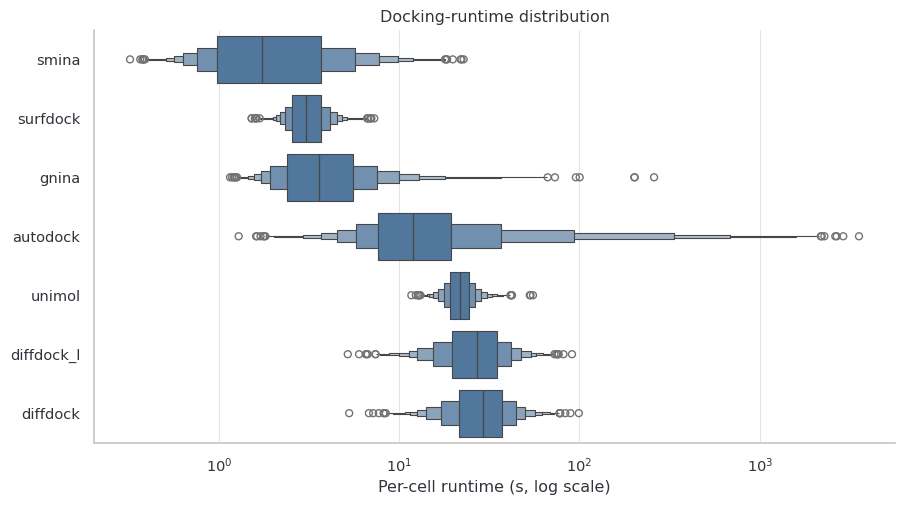

,cells,median_s,mean_s,total_h
algorithm,,,,
smina,3179,1.74,2.83,2.50
surfdock,3179,3.03,3.18,2.81
gnina,3179,3.61,4.95,4.37
autodock,3179,12.00,48.37,42.71
unimol,3179,21.65,22.03,19.45
diffdock_l,3179,27.11,28.00,24.73
diffdock,3179,29.10,30.15,26.62


In [100]:
runtime_long = (
    runtime_wide.rename_axis("instance_id").reset_index()
    .melt(id_vars="instance_id", var_name="algorithm", value_name="runtime_s")
)
algorithm_order = runtime_long.groupby("algorithm")["runtime_s"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9.2, 5.2))
sns.boxenplot(data=runtime_long, x="runtime_s", y="algorithm", order=algorithm_order, color="#4477AA", linewidth=0.8, ax=ax)
ax.set_xscale("log")
ax.set(xlabel="Per-cell runtime (s, log scale)", ylabel=None, title="Docking-runtime distribution")
fig.tight_layout()
save_figure(fig, "runtime_distribution")
plt.show()

display(
    runtime_long.groupby("algorithm")["runtime_s"]
    .agg(cells="size", median_s="median", mean_s="mean", total_h=lambda x: x.sum() / 3600)
    .loc[algorithm_order]
    .round(2)
)


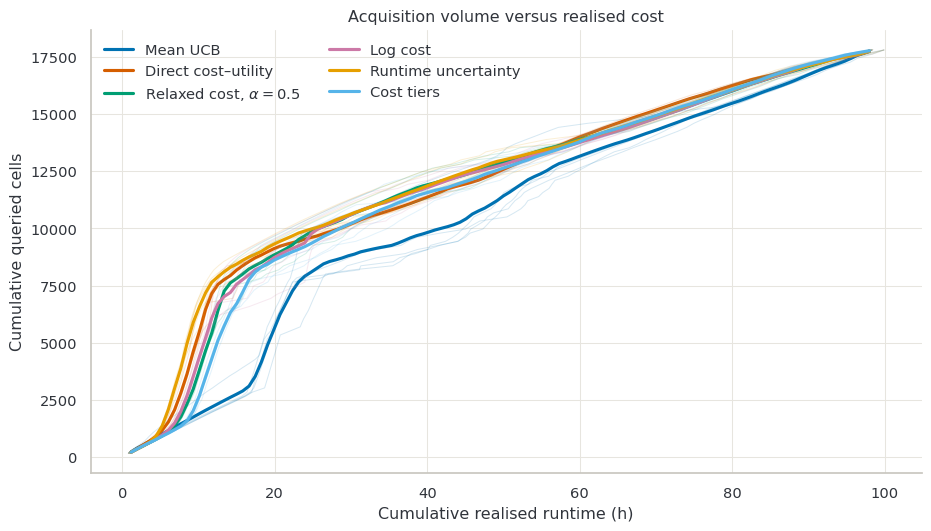

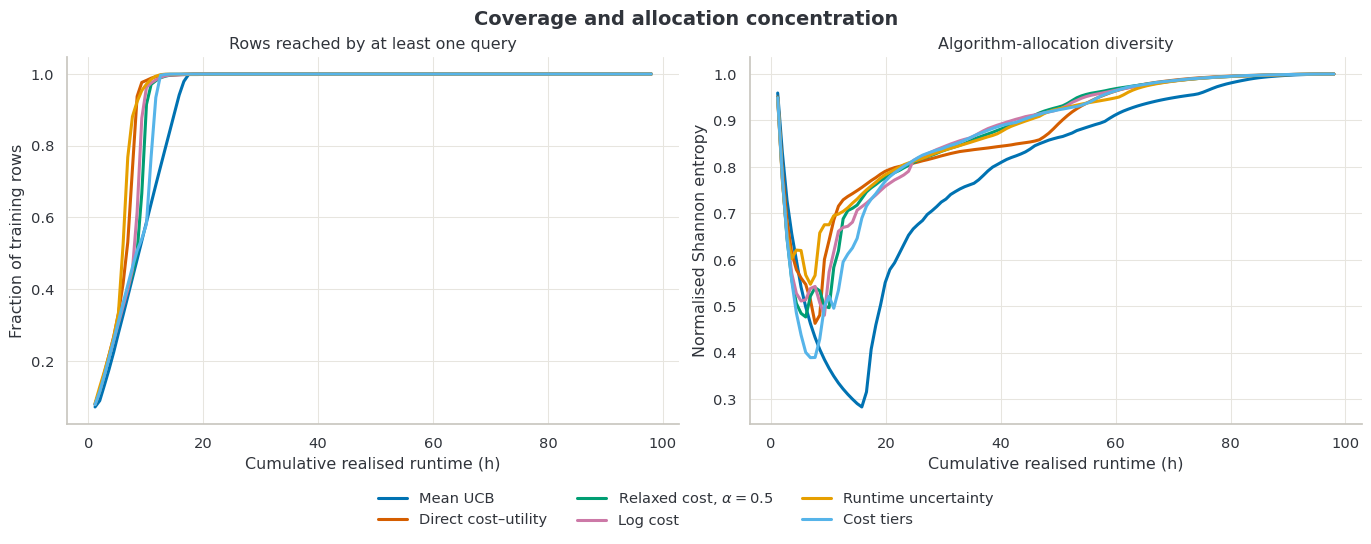

In [101]:
def common_curve_grid(data, x, y, points=120, required_folds=FOLDS):
    rows = []
    required_folds = set(required_folds) if required_folds is not None else None
    for method, method_data in data.dropna(subset=[x, y]).groupby("method"):
        trajectories, limits = [], []
        for fold, group in method_data.groupby("fold"):
            curve = group.groupby(x, as_index=False)[y].mean().sort_values(x)
            if len(curve) >= 2:
                trajectories.append((fold, curve))
                limits.append((curve[x].min(), curve[x].max()))
        if required_folds is not None and {fold for fold, _ in trajectories} != required_folds:
            continue
        if not trajectories:
            continue
        lower = max(bound[0] for bound in limits)
        upper = min(bound[1] for bound in limits)
        if lower > upper:
            continue
        grid = np.linspace(lower, upper, points) if lower < upper else np.array([lower])
        for fold, curve in trajectories:
            values = np.interp(grid, curve[x], curve[y])
            rows.extend({"method": method, "fold": fold, "x": gx, "value": gy} for gx, gy in zip(grid, values))
    return pd.DataFrame(rows, columns=["method", "fold", "x", "value"])


def draw_fold_curve_panel(ax, data, x, y, x_label, y_label, title, required_folds=FOLDS):
    interpolated = common_curve_grid(data, x, y, required_folds=required_folds)
    for method in METHODS:
        colour = METHOD_COLOURS[method]
        raw = data[data["method"].eq(method)]
        for _, fold_curve in raw.groupby("fold"):
            fold_curve = fold_curve.sort_values(x)
            ax.plot(fold_curve[x], fold_curve[y], color=colour, linewidth=0.72, alpha=0.16)
        grid_curve = interpolated[interpolated["method"].eq(method)]
        if grid_curve.empty:
            continue
        mean_curve = grid_curve.groupby("x")["value"].mean()
        ax.plot(mean_curve.index, mean_curve, color=colour, linewidth=2.25, label=method_label(method))
    ax.set(xlabel=x_label, ylabel=y_label, title=title)


def plot_cost_curves(data, y, y_label, title, name):
    fig, ax = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
    draw_fold_curve_panel(
        ax, data, "query_cost_h", y,
        "Cumulative realised runtime (h)", y_label, title,
    )
    ax.legend(frameon=False, ncol=2)
    save_figure(fig, name)
    plt.show()


plot_cost_curves(
    query_metrics_complete,
    "query_count",
    "Cumulative queried cells",
    "Acquisition volume versus realised cost",
    "queried_cells_vs_cost",
)

fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.7), constrained_layout=True)
for method in METHODS:
    colour = METHOD_COLOURS[method]
    group = query_metrics_complete[query_metrics_complete["method"].eq(method)]
    for metric, ax in (("row_coverage", axes[0]), ("allocation_entropy", axes[1])):
        interpolated = common_curve_grid(group, "query_cost_h", metric)
        if not interpolated.empty:
            mean_curve = interpolated.groupby("x")["value"].mean()
            ax.plot(mean_curve.index, mean_curve, color=colour, linewidth=2.2, label=method_label(method))
axes[0].set(xlabel="Cumulative realised runtime (h)", ylabel="Fraction of training rows", title="Rows reached by at least one query")
axes[1].set(xlabel="Cumulative realised runtime (h)", ylabel="Normalised Shannon entropy", title="Algorithm-allocation diversity")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
fig.suptitle("Coverage and allocation concentration", fontsize=14, fontweight="semibold")
save_figure(fig, "coverage_and_allocation_entropy")
plt.show()


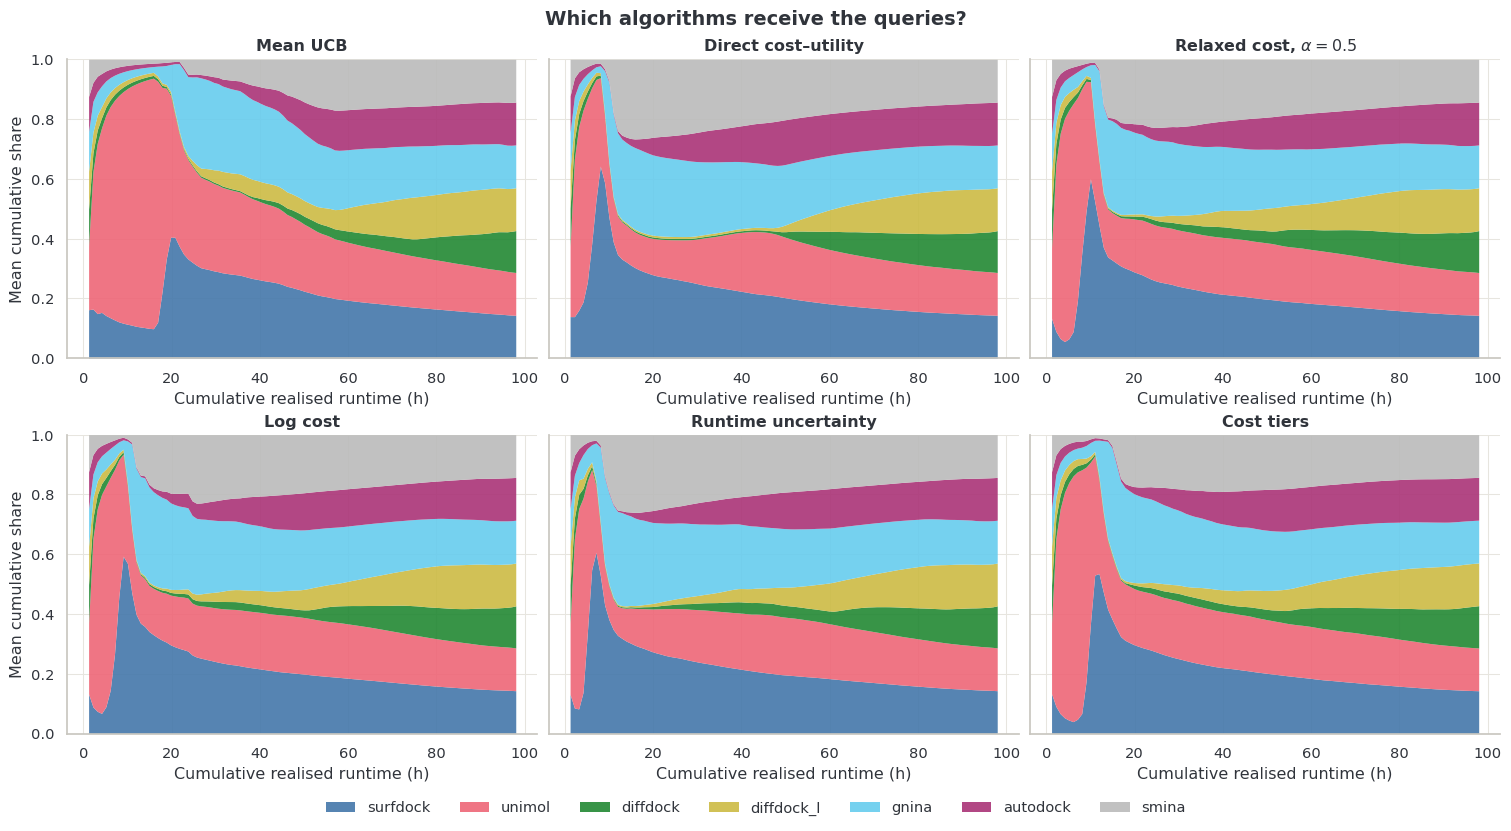

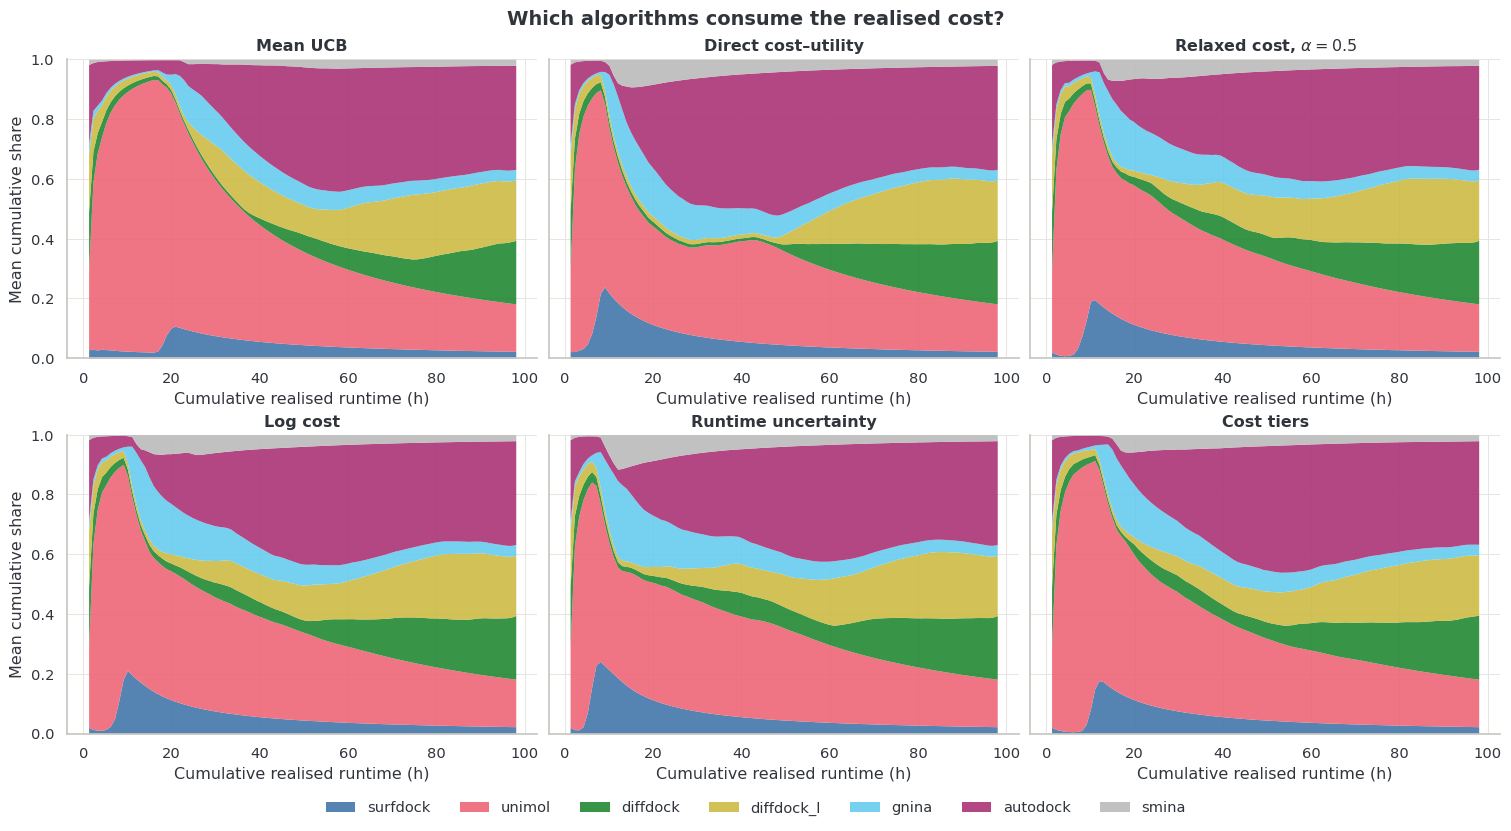

In [102]:
def mean_composition(data, value, points=100):
    rows = []
    for method, method_data in data.groupby("method"):
        fold_pivots, limits = [], []
        for fold, group in method_data.groupby("fold"):
            pivot = (
                group.pivot_table(index="total_query_cost_h", columns="algorithm", values=value, aggfunc="mean")
                .reindex(columns=ALGORITHMS, fill_value=0).sort_index()
            )
            if len(pivot) >= 2:
                fold_pivots.append((fold, pivot))
                limits.append((pivot.index.min(), pivot.index.max()))
        if {fold for fold, _ in fold_pivots} != set(FOLDS):
            continue
        lower = max(bound[0] for bound in limits)
        upper = min(bound[1] for bound in limits)
        if lower >= upper:
            continue
        grid = np.linspace(lower, upper, points)
        values = np.mean([
            np.column_stack([np.interp(grid, pivot.index, pivot[algorithm]) for algorithm in ALGORITHMS])
            for _, pivot in fold_pivots
        ], axis=0)
        values /= values.sum(axis=1, keepdims=True)
        for cost, shares in zip(grid, values):
            rows.extend({"method": method, "algorithm": algorithm, "query_cost_h": cost, "value": share} for algorithm, share in zip(ALGORITHMS, shares))
    return pd.DataFrame(rows, columns=["method", "algorithm", "query_cost_h", "value"])


allocation_with_cost = allocation.merge(
    query_metrics_complete[["method", "fold", "percentage", "query_cost_h", "cost_fraction"]].rename(
        columns={"query_cost_h": "total_query_cost_h"}
    ),
    on=["method", "fold", "percentage"],
    how="inner",
    validate="many_to_one",
)


def plot_composition(value, title, name):
    mean_share = mean_composition(allocation_with_cost, value)
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.8), sharex=False, sharey=True, constrained_layout=True)
    for ax, method in zip(axes.flat, METHODS):
        group = mean_share[mean_share["method"].eq(method)]
        if group.empty:
            ax.text(0.5, 0.5, "Awaiting a complete\nfive-fold trajectory", ha="center", va="center", transform=ax.transAxes, color="#777777")
        else:
            pivot = group.pivot(index="query_cost_h", columns="algorithm", values="value").reindex(columns=ALGORITHMS).fillna(0)
            ax.stackplot(
                pivot.index,
                *(pivot[algorithm] for algorithm in ALGORITHMS),
                labels=ALGORITHMS,
                colors=[ALGORITHM_COLOURS[a] for a in ALGORITHMS],
                alpha=0.90,
                linewidth=0,
            )
        ax.set_title(method_label(method), fontweight="semibold")
        ax.set_ylim(0, 1)
        ax.set_xlabel("Cumulative realised runtime (h)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Mean cumulative share")
    handles, labels = next((axis.get_legend_handles_labels() for axis in axes.flat if axis.get_legend_handles_labels()[0]), ([], []))
    if handles:
        fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.055), ncol=len(ALGORITHMS), frameon=False)
    fig.suptitle(title, fontsize=14, fontweight="semibold")
    save_figure(fig, name)
    plt.show()


plot_composition("query_share", "Which algorithms receive the queries?", "cumulative_query_share")
plot_composition("cost_share", "Which algorithms consume the realised cost?", "cumulative_cost_share")


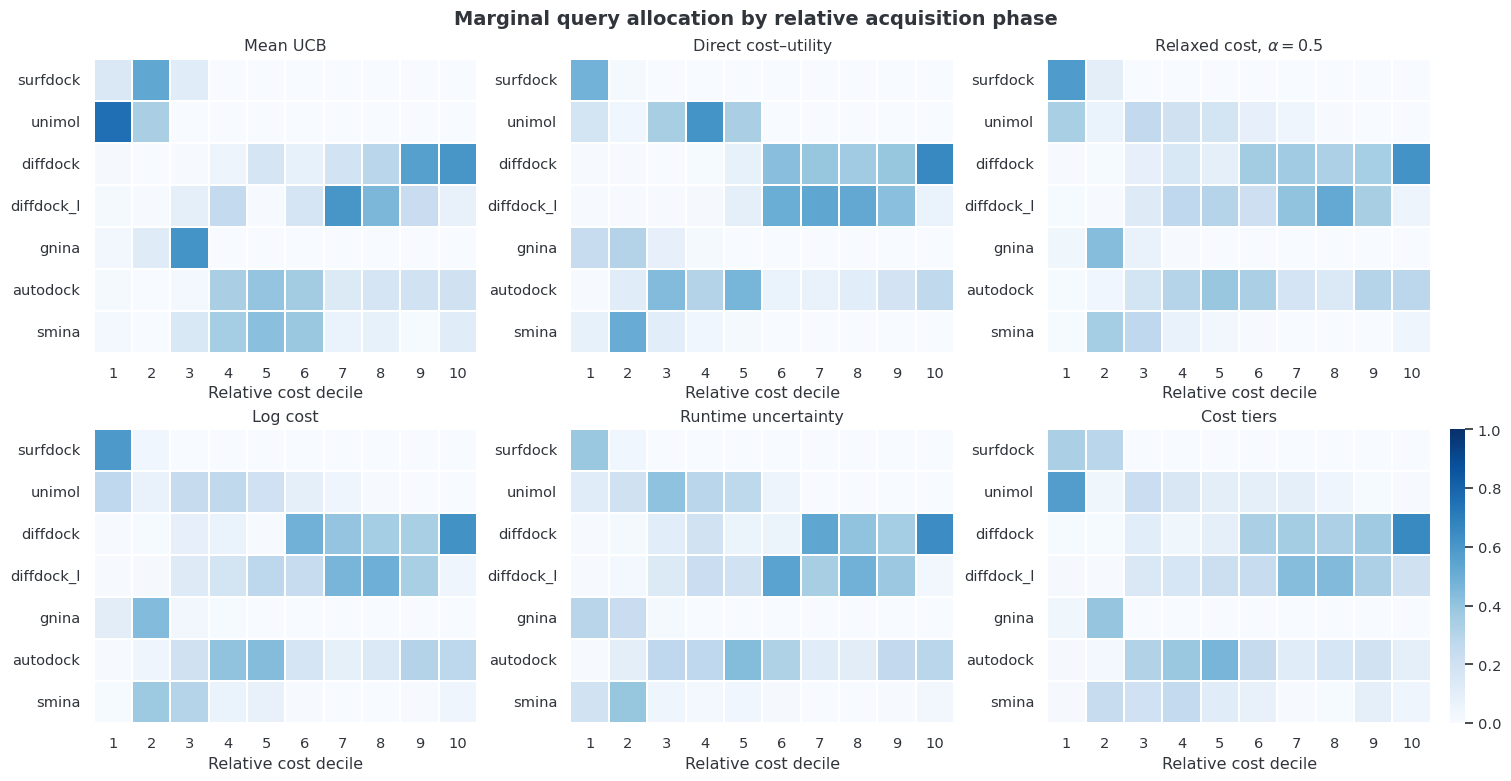

In [103]:
marginal = allocation_with_cost.copy()
marginal["cost_decile"] = np.clip(np.ceil(marginal["cost_fraction"] * 10), 1, 10).astype(int)
marginal = (
    marginal.groupby(["method", "fold", "cost_decile", "algorithm"], as_index=False)["marginal_query_count"].sum()
    .groupby(["method", "cost_decile", "algorithm"], as_index=False)["marginal_query_count"].mean()
)
marginal["share"] = marginal["marginal_query_count"] / marginal.groupby(["method", "cost_decile"])["marginal_query_count"].transform("sum")

fig, axes = plt.subplots(2, 3, figsize=(15, 7.7), constrained_layout=True)
for ax, method in zip(axes.flat, METHODS):
    table = (
        marginal[marginal["method"].eq(method)]
        .pivot(index="algorithm", columns="cost_decile", values="share")
        .reindex(index=ALGORITHMS, columns=range(1, 11))
    )
    sns.heatmap(table, vmin=0, vmax=1, cmap="Blues", cbar=ax is axes.flat[-1], ax=ax, linewidths=0.25)
    ax.set(title=method_label(method), xlabel="Relative cost decile", ylabel=None)
fig.suptitle("Marginal query allocation by relative acquisition phase", fontsize=14, fontweight="semibold")
save_figure(fig, "marginal_query_allocation")
plt.show()


## 8. Completed-matrix quality

The five faint trajectories expose split sensitivity; each bold curve is a fold-macro mean over that method's own five-fold common cost support. Shaded ranges are descriptive fold ranges, not confidence intervals.


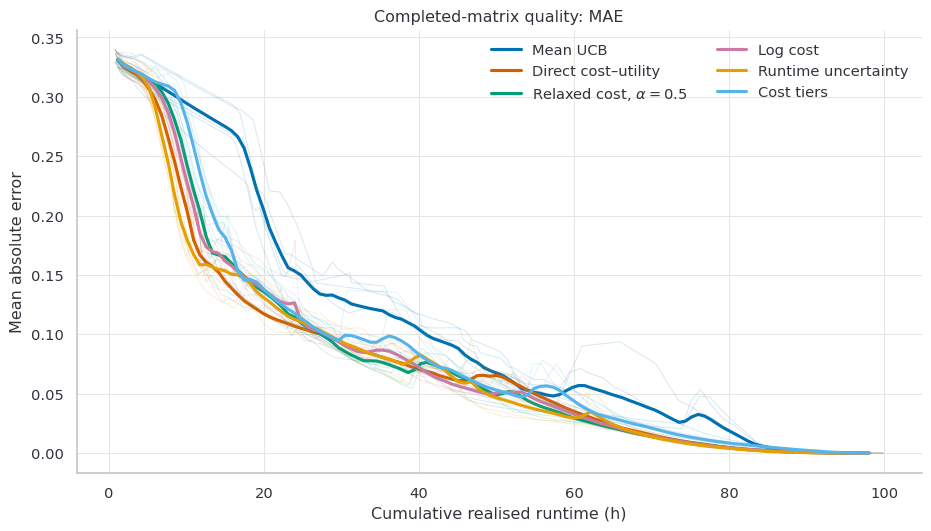

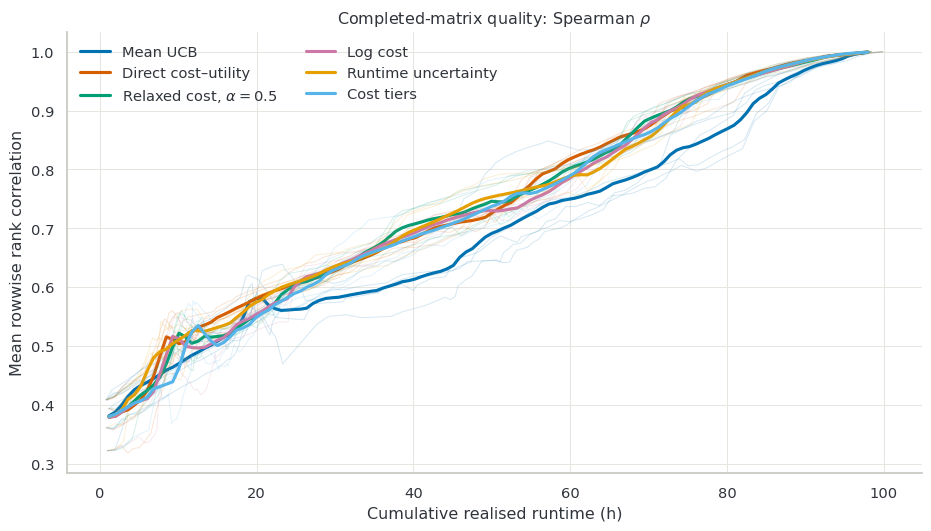

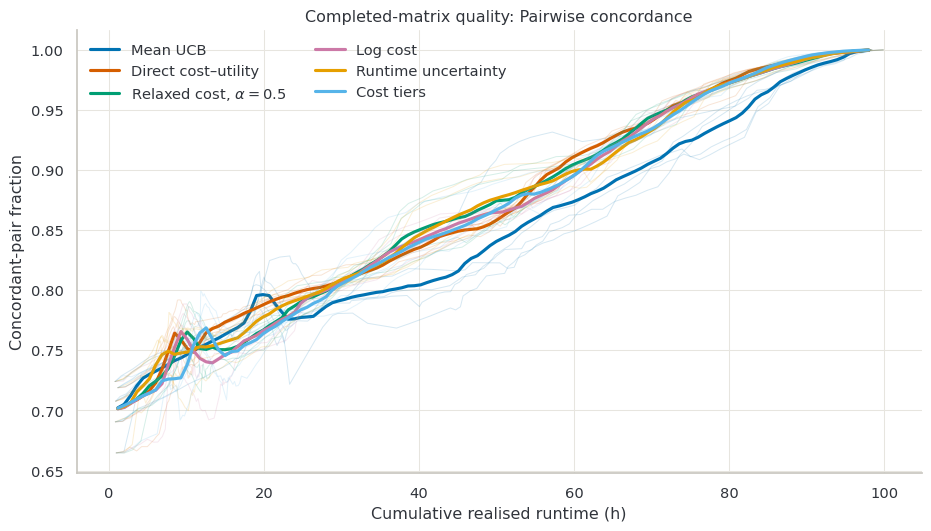

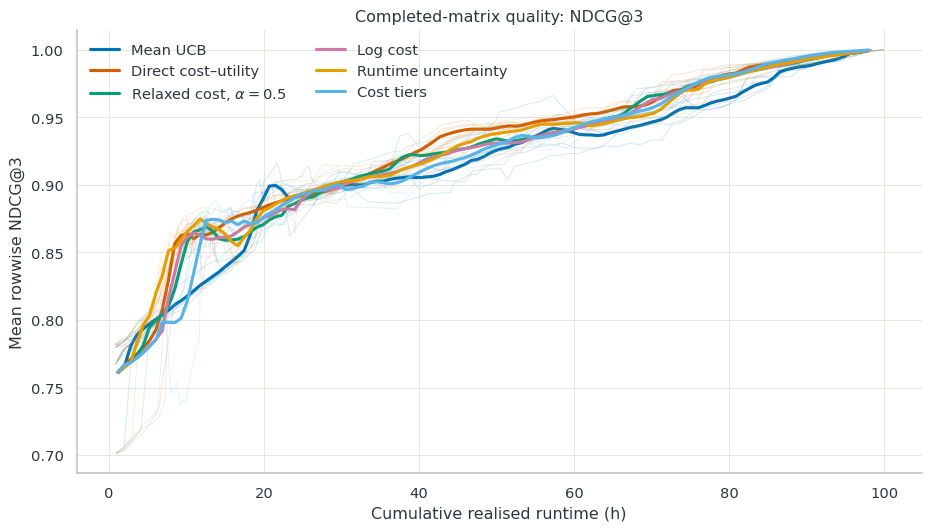

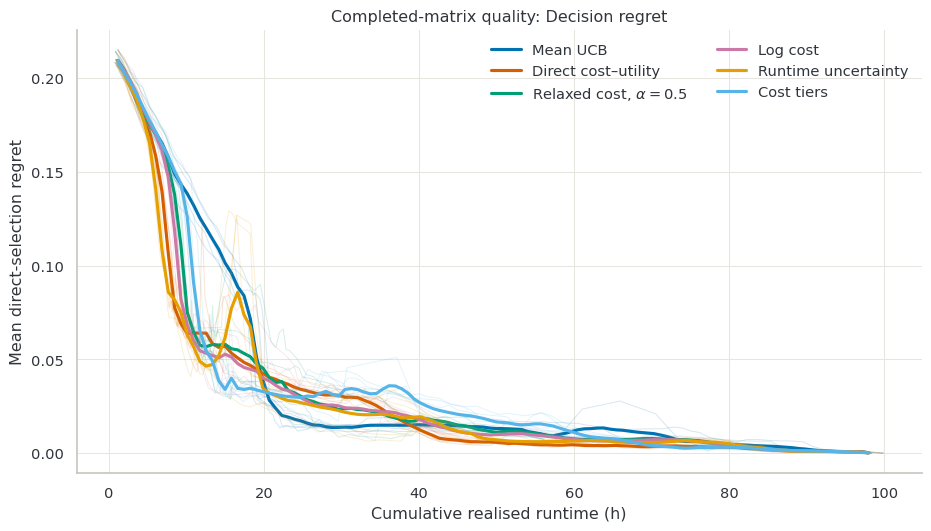

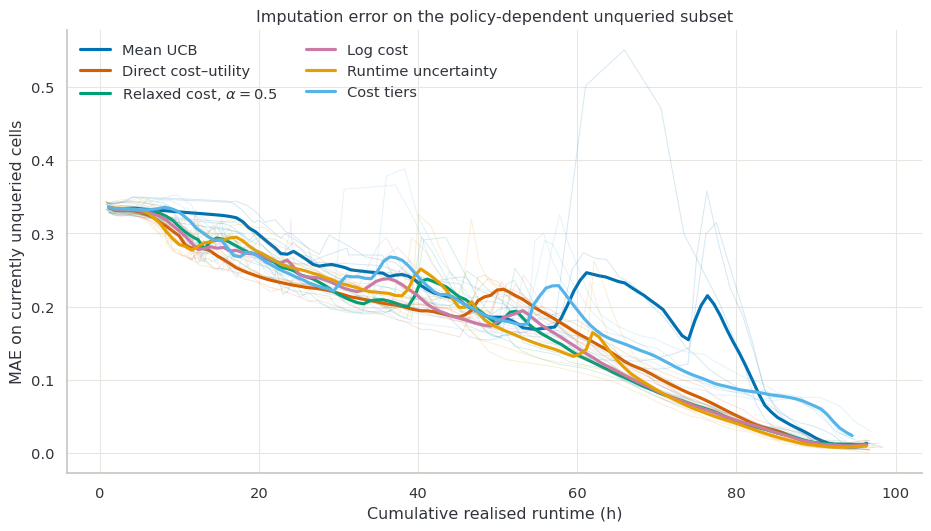

In [104]:
for metric, (title, y_label, _) in UPSTREAM_METRICS.items():
    plot_cost_curves(
        fold_metrics_complete,
        metric,
        y_label,
        f"Completed-matrix quality: {title}",
        f"upstream_{metric}",
    )

plot_cost_curves(
    fold_metrics_complete,
    "unqueried_mae",
    "MAE on currently unqueried cells",
    "Imputation error on the policy-dependent unqueried subset",
    "unqueried_cell_mae",
)


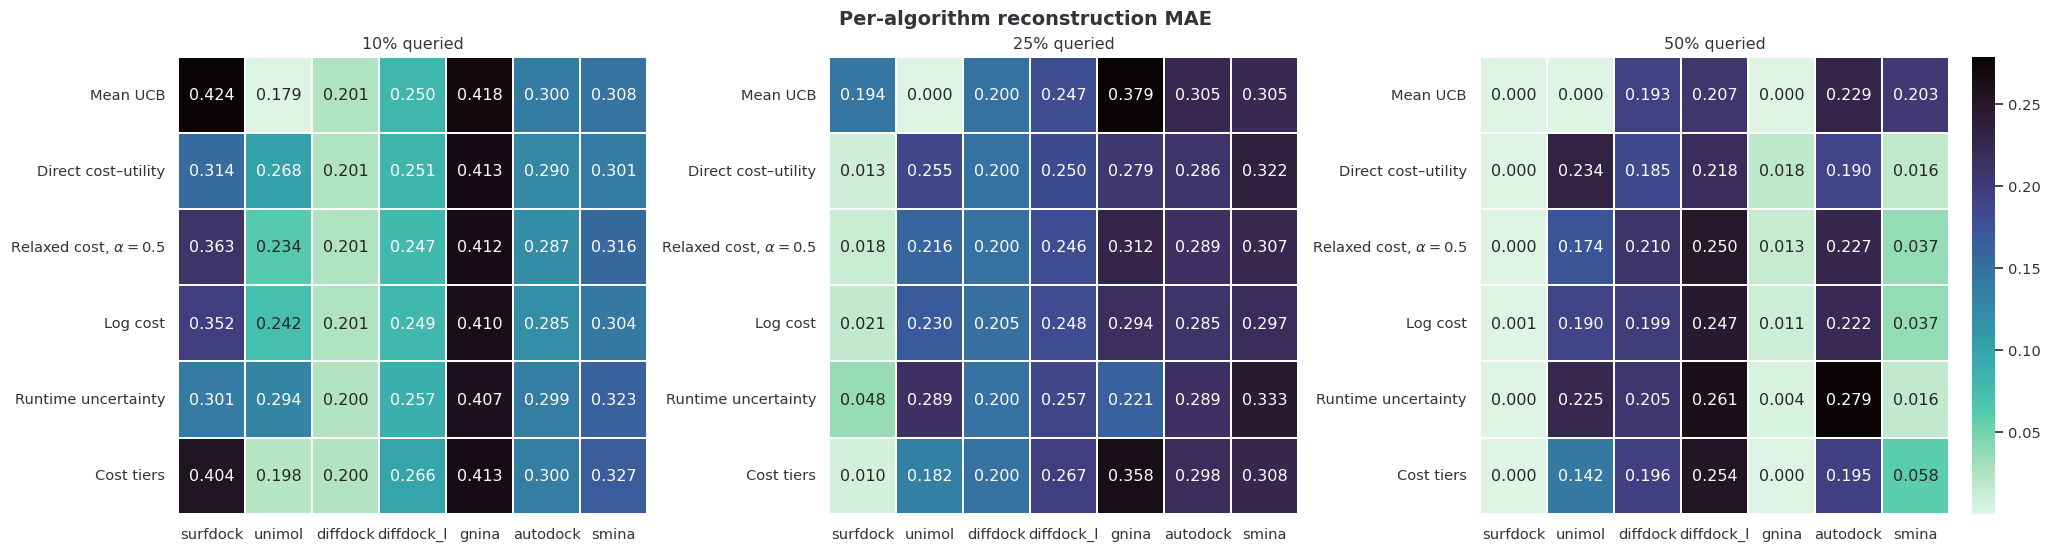

In [105]:
algorithm_metrics_complete = algorithm_metrics.merge(matrix_complete_keys, on=["method", "percentage"], how="inner", validate="many_to_one")
selected_percentages = [p for p in (10, 25, 50) if p in set(algorithm_metrics_complete["percentage"])]
if selected_percentages:
    fig, axes = plt.subplots(1, len(selected_percentages), figsize=(6.8 * len(selected_percentages), 5.4), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, percentage in zip(axes, selected_percentages):
        table = (
            algorithm_metrics_complete[algorithm_metrics_complete["percentage"].eq(percentage)]
            .groupby(["method", "algorithm"])["mae"].mean()
            .unstack("algorithm").reindex(index=METHODS, columns=ALGORITHMS)
            .rename(index=METHOD_LABELS)
        )
        sns.heatmap(table, cmap="mako_r", annot=True, fmt=".3f", linewidths=0.3, cbar=ax is axes[-1], ax=ax)
        ax.set(title=f"{percentage}% queried", xlabel=None, ylabel=None)
    fig.suptitle("Per-algorithm reconstruction MAE", fontsize=14, fontweight="semibold")
    save_figure(fig, "algorithm_mae_checkpoints")
    plt.show()


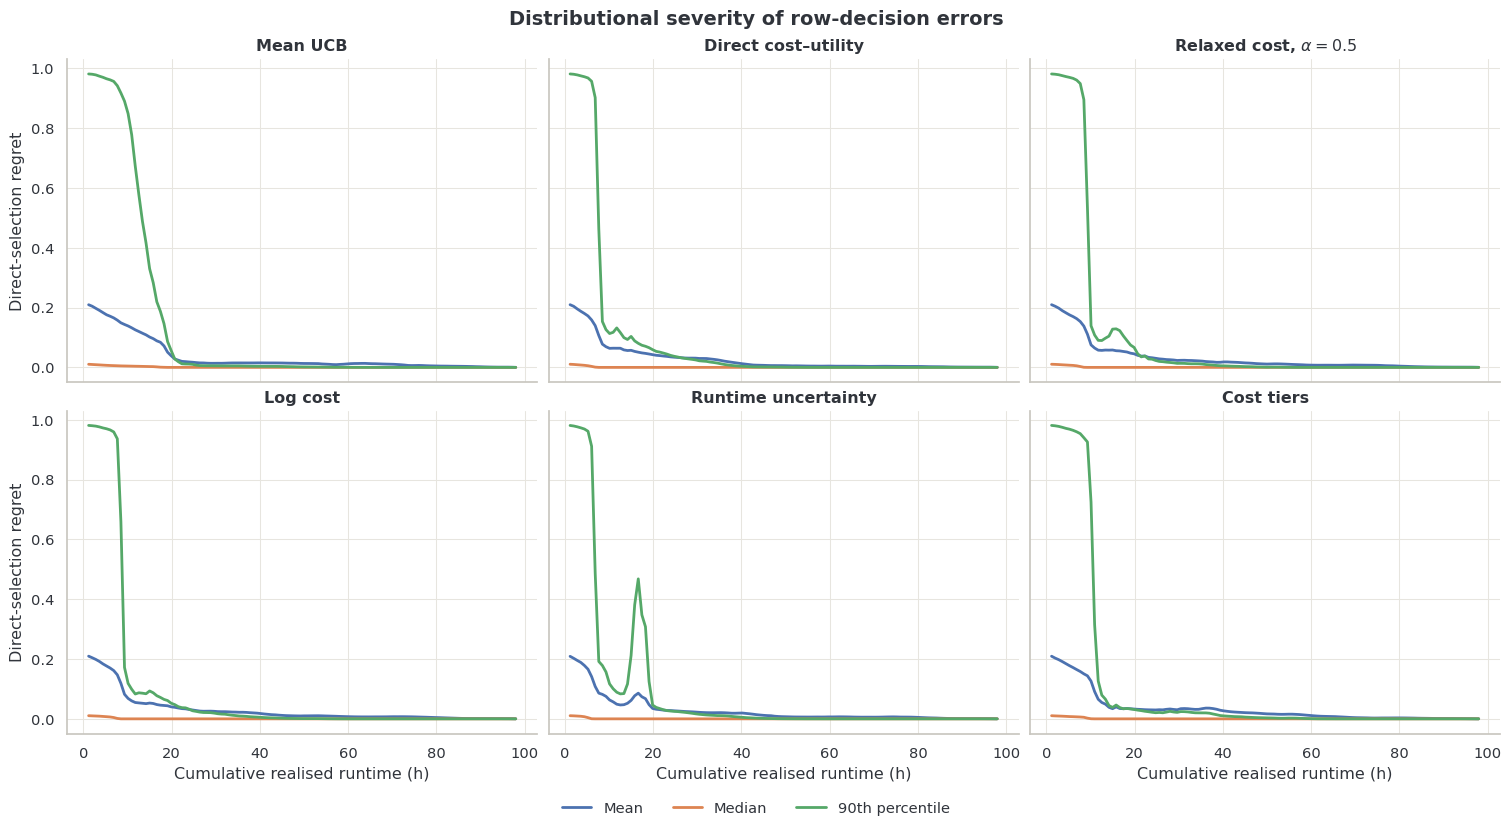

In [106]:
regret_summary = fold_metrics_complete.melt(
    id_vars=["method", "fold", "percentage", "query_cost_h", "cost_fraction"],
    value_vars=["decision_regret_mean", "decision_regret_median", "decision_regret_p90"],
    var_name="summary",
    value_name="regret",
)
labels = {
    "decision_regret_mean": "Mean",
    "decision_regret_median": "Median",
    "decision_regret_p90": "90th percentile",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 7.8), sharex=True, sharey=True, constrained_layout=True)
for ax, method in zip(axes.flat, METHODS):
    group = regret_summary[regret_summary["method"].eq(method)]
    for summary, curve in group.groupby("summary"):
        interpolated = common_curve_grid(curve, "query_cost_h", "regret")
        mean_curve = interpolated.groupby("x")["value"].mean()
        ax.plot(mean_curve.index, mean_curve, label=labels[summary], linewidth=2)
    ax.set_title(method_label(method), fontweight="semibold")
for ax in axes[-1]:
    ax.set_xlabel("Cumulative realised runtime (h)")
for ax in axes[:, 0]:
    ax.set_ylabel("Direct-selection regret")
handles, labels_ = axes.flat[-1].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", bbox_to_anchor=(0.5, -0.055), ncol=3, frameon=False)
fig.suptitle("Distributional severity of row-decision errors", fontsize=14, fontweight="semibold")
save_figure(fig, "decision_regret_distribution")
plt.show()


## 9. Sensitivity to the available training pool

Every instance appears in four training pools. The dispersion below compares those four predictions for the same cell. This is the one place where matrices are aligned with missing entries—and only to measure cross-fold stability, not to construct a synthetic training matrix.


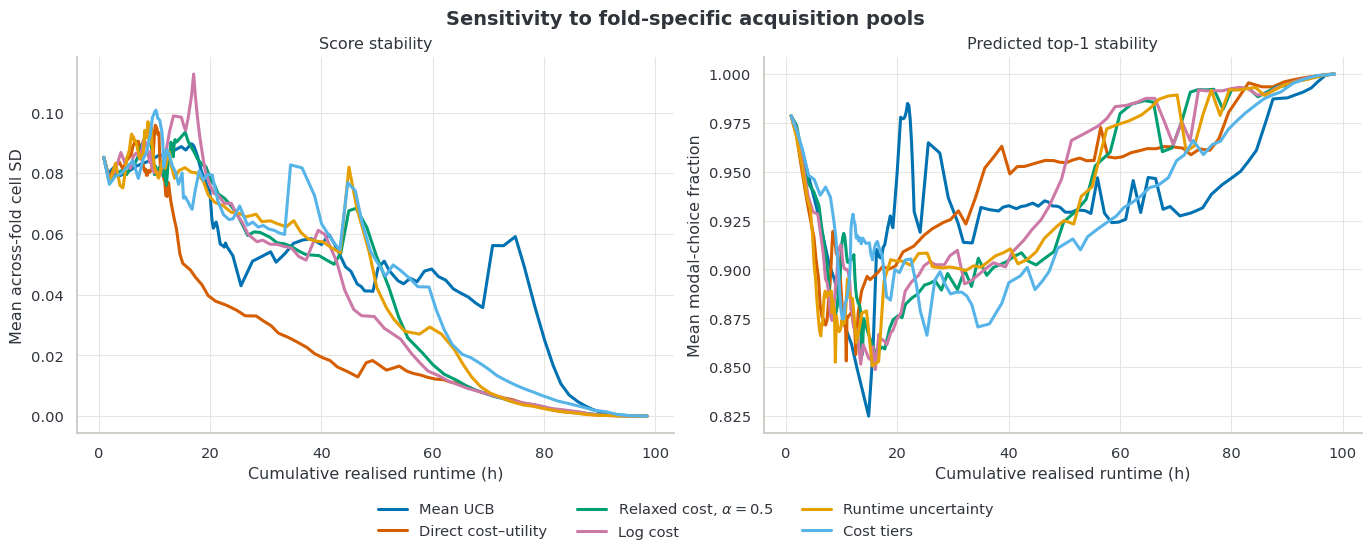

In [107]:
stability_curve = (
    stability.merge(matrix_complete_keys, on=["method", "percentage"], how="inner", validate="many_to_one")
    .groupby(["method", "percentage"], as_index=False)
    .agg(prediction_sd_mean=("prediction_sd_mean", "first"), top1_stability=("top1_stability", "first"))
    .merge(query_metrics_complete.groupby(["method", "percentage"], as_index=False)["query_cost_h"].mean(), on=["method", "percentage"])
)

fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.8), constrained_layout=True)
for method in METHODS:
    group = stability_curve[stability_curve["method"].eq(method)].sort_values("query_cost_h")
    axes[0].plot(group["query_cost_h"], group["prediction_sd_mean"], color=METHOD_COLOURS[method], linewidth=2.2, label=method_label(method))
    axes[1].plot(group["query_cost_h"], group["top1_stability"], color=METHOD_COLOURS[method], linewidth=2.2)
axes[0].set(xlabel="Cumulative realised runtime (h)", ylabel="Mean across-fold cell SD", title="Score stability")
axes[1].set(xlabel="Cumulative realised runtime (h)", ylabel="Mean modal-choice fraction", title="Predicted top-1 stability")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
fig.suptitle("Sensitivity to fold-specific acquisition pools", fontsize=14, fontweight="semibold")
save_figure(fig, "cross_fold_stability")
plt.show()


## 10. Downstream MolAS performance

Each fold's AS performance is normalised by its own SBS–VBS interval,

\[
100\,\frac{\mathrm{AS}_{mfp}-\mathrm{SBS}_{f}}{\mathrm{VBS}_{f}-\mathrm{SBS}_{f}},
\]

before the five folds are macro-averaged. This removes fold-level baseline difficulty: SBS is 0%, VBS is 100%, and raw outcomes remain in the exported tables.

Only method–percentage checkpoints with all five folds contribute. Because equal acquisition percentages imply different realised costs across folds, each fold's aggregate downstream performance is linearly interpolated onto that method's common realised-cost support before the five folds are averaged. There is no extrapolation. This interpolation applies to aggregate performance summaries, never to discrete per-row algorithm choices. The five thin lines show observed fold checkpoints and the heavy line is the cost-aligned macro mean.

The inverse plot takes the first-attainment frontier of exactly the same cost-aligned macro curve. Diamonds additionally retain the observed 100% acquisition endpoint even when it lies outside the common fold-cost support or is dominated and therefore absent from the frontier.


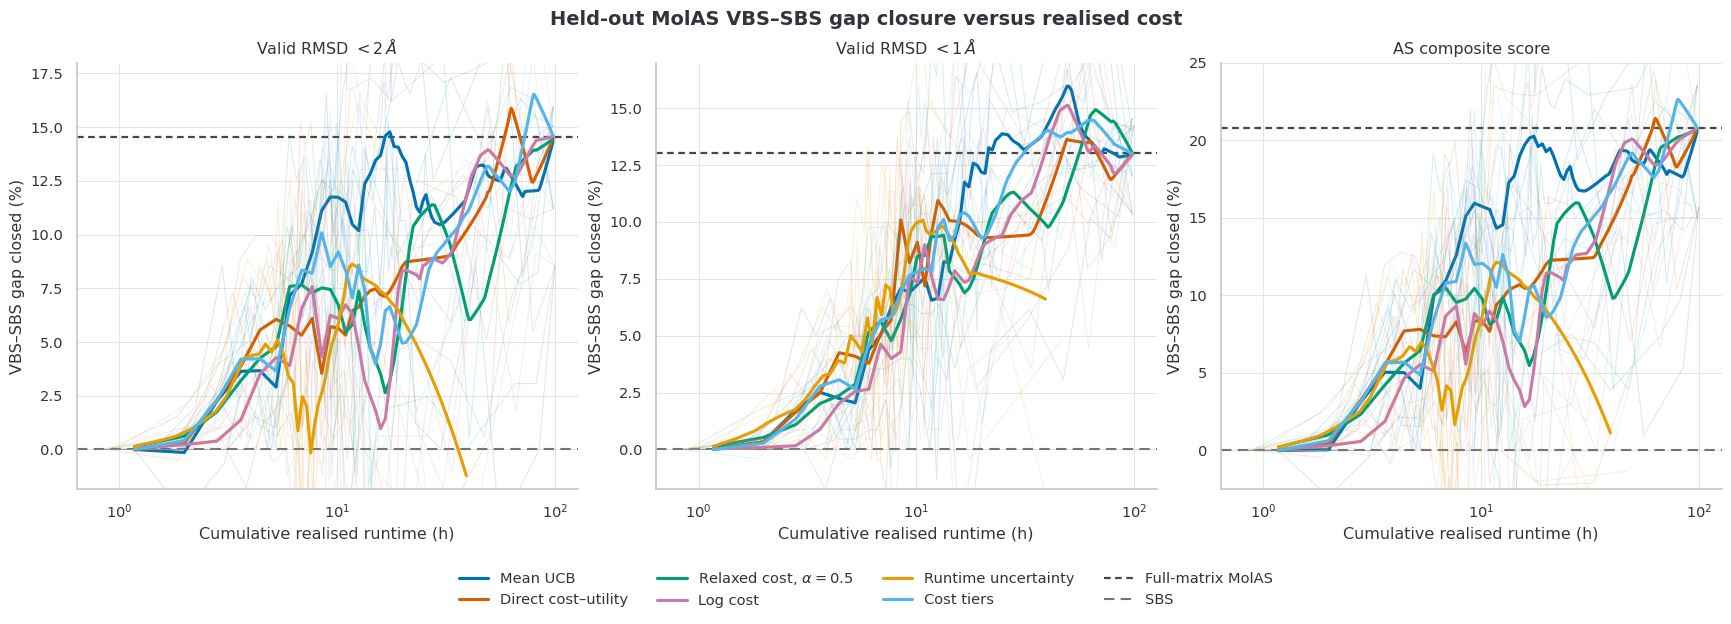

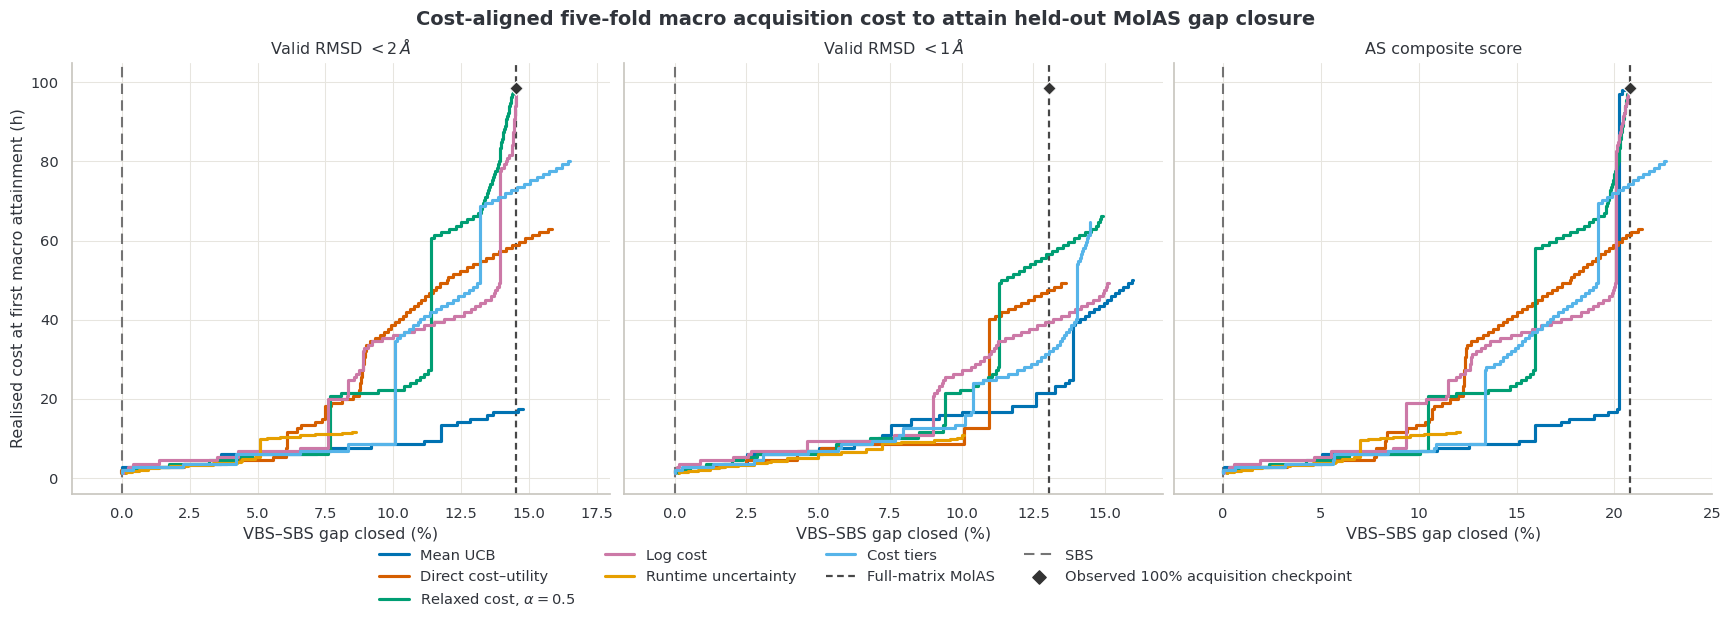

**Five-fold macro outcomes at selected acquisition percentages.**

gap_closed_valid_rmsd_2                         gap_closed_valid_rmsd_1                         gap_closed_as_score          \
percentage                                     10      25      50      100                     10      25      50      100                 10      25    
method                                                                                                                                                   
Cost tiers                                   7.900   6.235   6.014  14.545                   7.396   7.406  10.798  13.039              10.917   9.823   
Direct cost–utility                          4.064   3.566   8.703  14.545                   2.818   8.083   9.388  13.039               5.536   5.888   
Log cost                                     7.753   6.522   6.986  14.545                   4.475   7.483   6.892  13.039               9.882   8.514   
Mean UCB                                    11.650  14.377  10.539  14.545                   7.016  12.798  12.310  13.039              15.922  19.494   
Relaxed cost, $\alpha=0.5$                   6.949   5.448   9.859  14.545                   5.475   8.457   9.584  13.039               9.270   8.055   
Runtime uncertainty                          3.926   1.998   7.616     NaN                   3.811   6.344   8.102     NaN               5.680   4.035   

                                            
percentage                     50      100  
method                                      
Cost tiers                  10.301  20.804  
Direct cost–utility         12.288  20.804  
Log cost                     9.510  20.804  
Mean UCB                    16.715  20.804  
Relaxed cost, $\alpha=0.5$  13.957  20.804  
Runtime uncertainty         10.701     NaN

In [ ]:
paired_all = fold_metrics.merge(
    downstream,
    on=["method", "fold", "percentage"],
    how="inner",
    validate="one_to_one",
)


paired_fold_coverage = fold_coverage(paired_all, "paired matrix–MolAS")
paired_complete_keys = paired_fold_coverage.loc[
    paired_fold_coverage["fold_complete"], ["method", "percentage"]
]
paired = paired_all.merge(
    paired_complete_keys,
    on=["method", "percentage"],
    how="inner",
    validate="many_to_one",
)

full_matrix_rows = downstream[downstream["percentage"].eq(100)].copy()
full_matrix_coverage = full_matrix_rows.groupby("method")["fold"].nunique()
full_matrix_methods = [method for method in METHODS if full_matrix_coverage.get(method, 0) == len(FOLDS)]
if not full_matrix_methods:
    raise RuntimeError("A full-matrix MolAS reference requires a 100% result for every fold of at least one method.")

full_matrix_method = REFERENCE_METHOD if REFERENCE_METHOD in full_matrix_methods else full_matrix_methods[0]
full_matrix_by_fold = (
    full_matrix_rows[full_matrix_rows["method"].eq(full_matrix_method)]
    .groupby("fold")[list(DOWNSTREAM_METRICS)].mean().reindex(FOLDS)
)
reference_values = (
    full_matrix_by_fold.rename_axis("fold").reset_index()
    .melt(id_vars="fold", var_name="metric", value_name="reference_value")
)
comparison = (
    full_matrix_rows.melt(
        id_vars=["method", "fold", "percentage"],
        value_vars=list(DOWNSTREAM_METRICS),
        var_name="metric",
        value_name="value",
    )
    .merge(reference_values, on=["fold", "metric"], how="left", validate="many_to_one")
)
max_full_matrix_difference = (comparison["value"] - comparison["reference_value"]).abs().max()
if max_full_matrix_difference > 1e-6:
    warnings.warn(
        f"100% downstream results disagree by up to {max_full_matrix_difference:.3g} gap-closure points; "
        f"the reference uses {method_label(full_matrix_method)}."
    )

BASELINE_STYLES["Full-matrix MolAS"] = {
    "color": "#333333",
    "linestyle": (0, (3, 2)),
    "linewidth": 1.6,
}
downstream_baselines = pd.DataFrame([
    {
        "baseline": baseline,
        "metric": metric,
        "value": value,
        "fold_min": fold_min,
        "fold_max": fold_max,
        "n_folds": len(FOLDS),
    }
    for metric in DOWNSTREAM_METRICS
    for baseline, value, fold_min, fold_max in (
        (
            "Full-matrix MolAS",
            full_matrix_by_fold[metric].mean(),
            full_matrix_by_fold[metric].min(),
            full_matrix_by_fold[metric].max(),
        ),
        ("SBS", 0.0, 0.0, 0.0),
    )
])


def draw_downstream_baselines(ax, metric, orientation):
    for row in downstream_baselines[downstream_baselines["metric"].eq(metric)].itertuples(index=False):
        style = {**BASELINE_STYLES[row.baseline], "alpha": 0.9, "zorder": 1.1, "label": row.baseline}
        if orientation == "horizontal":
            ax.axhline(row.value, **style)
        else:
            ax.axvline(row.value, **style)


downstream_plot_limits = {
    "gap_closed_valid_rmsd_2": (-1.85, 18),
    "gap_closed_valid_rmsd_1": (-1.75, 17),
    "gap_closed_as_score": (-2.5, 25),
}
cost_aligned_parts = []
for metric in DOWNSTREAM_METRICS:
    part = common_curve_grid(paired, "query_cost_h", metric, required_folds=FOLDS)
    part = part.rename(columns={"x": "query_cost_h", "value": "performance_level"})
    part["metric"] = metric
    cost_aligned_parts.append(part)
downstream_cost_aligned_folds = pd.concat(cost_aligned_parts, ignore_index=True)
downstream_cost_aligned_macro = (
    downstream_cost_aligned_folds.groupby(["method", "metric", "query_cost_h"], as_index=False)
    .agg(performance_level=("performance_level", "mean"), n_folds=("fold", "nunique"))
    .loc[lambda frame: frame["n_folds"].eq(len(FOLDS))]
)


def draw_downstream_cost_aligned_panel(ax, metric, title, y_label):
    for method in METHODS:
        colour = METHOD_COLOURS[method]
        raw = paired[paired["method"].eq(method)]
        for _, fold_curve in raw.groupby("fold"):
            fold_curve = fold_curve.sort_values("query_cost_h")
            ax.plot(
                fold_curve["query_cost_h"], fold_curve[metric],
                color=colour, linewidth=0.72, alpha=0.16,
            )
        macro = downstream_cost_aligned_macro[
            downstream_cost_aligned_macro["method"].eq(method)
            & downstream_cost_aligned_macro["metric"].eq(metric)
        ].sort_values("query_cost_h")
        if not macro.empty:
            ax.plot(
                macro["query_cost_h"], macro["performance_level"],
                color=colour, linewidth=2.25, label=method_label(method),
            )
    ax.set(
        # xscale="log",
        xlabel="Cumulative realised runtime (h)",
        ylabel=y_label,
        title=title,
        ylim=downstream_plot_limits[metric],
    )


fig, axes = plt.subplots(1, 3, figsize=(17.2, 5.4), constrained_layout=True)
for ax, (metric, (title, y_label, _)) in zip(axes, DOWNSTREAM_METRICS.items()):
    draw_downstream_cost_aligned_panel(ax, metric, title, y_label)
    draw_downstream_baselines(ax, metric, "horizontal")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False)
fig.suptitle("Held-out MolAS VBS–SBS gap closure versus realised cost", fontsize=14, fontweight="semibold")
save_figure(fig, "downstream_performance_vs_cost")
plt.show()


def first_attainment_frontier(curves):
    frontiers = []
    for (method, metric), curve in curves.groupby(["method", "metric"]):
        curve = curve.sort_values("query_cost_h")
        direction = 1 if DOWNSTREAM_METRICS[metric][2] else -1
        best = np.maximum.accumulate(direction * curve["performance_level"].to_numpy())
        improved = np.r_[True, np.diff(best) > 0]
        frontier = curve.loc[improved].copy()
        frontier["performance_level"] = direction * best[improved]
        frontiers.append(frontier)
    return pd.concat(frontiers, ignore_index=True)


attainment_costs = first_attainment_frontier(downstream_cost_aligned_macro)
terminal_checkpoints = (
    paired[paired["percentage"].eq(100)]
    .groupby("method", as_index=False)
    .agg(
        n_folds=("fold", "nunique"),
        query_cost_h=("query_cost_h", "mean"),
        **{metric: (metric, "mean") for metric in DOWNSTREAM_METRICS},
    )
    .loc[lambda frame: frame["n_folds"].eq(len(FOLDS))]
    .melt(
        id_vars=["method", "n_folds", "query_cost_h"],
        value_vars=list(DOWNSTREAM_METRICS),
        var_name="metric",
        value_name="performance_level",
    )
)

fig, axes = plt.subplots(1, 3, figsize=(17.2, 5.4), sharey=True, constrained_layout=True)
for ax, (metric, (title, performance_label, higher_is_better)) in zip(axes, DOWNSTREAM_METRICS.items()):
    for method in METHODS:
        colour = METHOD_COLOURS[method]
        frontier = attainment_costs[
            attainment_costs["metric"].eq(metric)
            & attainment_costs["method"].eq(method)
        ].sort_values("performance_level", ascending=higher_is_better)
        if not frontier.empty:
            ax.step(
                frontier["performance_level"], frontier["query_cost_h"],
                where="pre" if higher_is_better else "post",
                color=colour, linewidth=2.25, label=method_label(method),
            )
    terminal = terminal_checkpoints[terminal_checkpoints["metric"].eq(metric)].drop_duplicates(
        ["performance_level", "query_cost_h"]
    )
    ax.scatter(
        terminal["performance_level"], terminal["query_cost_h"],
        color="#333333", marker="D", s=46, edgecolor="white", linewidth=0.7, zorder=3,
    )
    draw_downstream_baselines(ax, metric, "vertical")
    if not higher_is_better:
        ax.invert_xaxis()
    ax.set(xlabel=performance_label, title=title, xlim=downstream_plot_limits[metric])
axes[0].scatter([], [], color="#333333", marker="D", s=46, label="Observed 100% acquisition checkpoint")
axes[0].set_ylabel("Realised cost at first macro attainment (h)")
axes[0].set_ylim(-4, 105)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False)
fig.suptitle("Cost-aligned five-fold macro acquisition cost to attain held-out MolAS gap closure", fontsize=14, fontweight="semibold")
save_figure(fig, "downstream_attainment_cost")
plt.show()


downstream_overall_raw = (
    downstream_complete.assign(
        valid_rmsd_2_weighted=lambda frame: frame["valid_rmsd_2"] * frame["test_rows"],
        valid_rmsd_1_weighted=lambda frame: frame["valid_rmsd_1"] * frame["test_rows"],
        as_score_weighted=lambda frame: frame["as_score"] * frame["test_rows"],
    )
    .groupby(["method", "percentage"], as_index=False)
    .agg(
        test_rows=("test_rows", "sum"),
        n_folds=("fold", "nunique"),
        valid_rmsd_2_sum=("valid_rmsd_2_weighted", "sum"),
        valid_rmsd_1_sum=("valid_rmsd_1_weighted", "sum"),
        as_score_sum=("as_score_weighted", "sum"),
    )
)
for metric in RAW_DOWNSTREAM_METRICS:
    downstream_overall_raw[metric] = downstream_overall_raw.pop(f"{metric}_sum") / downstream_overall_raw["test_rows"]

downstream_overall_gap = (
    downstream_complete.groupby(["method", "percentage"], as_index=False)[list(DOWNSTREAM_METRICS)].mean()
)
downstream_overall = downstream_overall_raw.merge(
    downstream_overall_gap,
    on=["method", "percentage"],
    how="inner",
    validate="one_to_one",
)

checkpoints = [percentage for percentage in (10, 25, 50, 100) if percentage in set(downstream_overall["percentage"])]
display(Markdown("**Five-fold macro outcomes at selected acquisition percentages.**"))
display(
    downstream_overall[downstream_overall["percentage"].isin(checkpoints)]
    .pivot(index="method", columns="percentage", values=list(DOWNSTREAM_METRICS))
    .rename(index=METHOD_LABELS).round(3)
)


## 11. Downstream mechanism diagnostics

The landmarks are defined on the five-fold Mean UCB trajectory. Within each fold, Mean UCB is first assigned its nearest observed checkpoint; every alternative is then assigned the checkpoint nearest to that **observed reference cost**, subject to the explicit absolute/relative caliper. A method enters a landmark comparison only if all five fold pairs pass the caliper. This avoids both interpolation and systematic method-specific underspend.

The following analyses report queried-cell efficiency, raw held-out outcomes, fold-normalised gap closure, PB validity, conditional RMSD quality, and the Unimol–SurfDock decision boundary. They compare exactly the same held-out instances within each fold.


In [109]:
if str(MOLAS_REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(MOLAS_REPO_ROOT))
try:
    from data.dataset import prepare_data_pose, prepare_data_rmsd
except ImportError as error:
    raise ImportError(f"Could not import MolAS data loaders from {MOLAS_REPO_ROOT}.") from error


def load_raw_outcome_matrix(loader, value_name):
    previous_directory = Path.cwd()
    try:
        os.chdir(MOLAS_REPO_ROOT)
        frame, _ = loader([], "moad")
    finally:
        os.chdir(previous_directory)
    frame = frame.copy()
    frame.columns = [normalise_algorithm(column) for column in frame.columns]
    frame["instance_id"] = frame["protein"].astype(str) + "_" + frame["ligand"].astype(str)
    missing = set(ground_truth.index).difference(frame["instance_id"])
    if missing or not frame["instance_id"].is_unique:
        raise ValueError(f"Raw {value_name} table violates the analysed-instance contract.")
    return frame.set_index("instance_id").loc[ground_truth.index, list(ALGORITHMS)]


def coerce_pose_validity(frame):
    converted = pd.DataFrame(index=frame.index)
    labels = {"true": True, "false": False, "1": True, "0": False}
    for column in frame:
        numeric = pd.to_numeric(frame[column], errors="coerce")
        if numeric.notna().all() and numeric.isin([0, 1]).all():
            converted[column] = numeric.astype(bool)
        else:
            converted[column] = frame[column].astype(str).str.strip().str.casefold().map(labels)
    if converted.isna().any().any():
        raise ValueError("Unrecognised PoseBusters values.")
    return converted.astype(bool)


def outcome_long(frame, value_name):
    return frame.rename_axis("instance_id").reset_index().melt(
        id_vars="instance_id", var_name="algorithm", value_name=value_name
    )


pose_wide = coerce_pose_validity(load_raw_outcome_matrix(prepare_data_pose, "PoseBusters"))
rmsd_wide = load_raw_outcome_matrix(prepare_data_rmsd, "RMSD").apply(pd.to_numeric, errors="coerce")
outcome_truth = (
    outcome_long(pose_wide, "pb_valid")
    .merge(outcome_long(rmsd_wide, "rmsd"), on=["instance_id", "algorithm"], validate="one_to_one")
    .merge(outcome_long(ground_truth, "composite_score"), on=["instance_id", "algorithm"], validate="one_to_one")
)


def complete_diagnostic_methods(data):
    complete = []
    for method, method_data in data.groupby("method"):
        fold_counts = method_data.groupby("fold").size()
        if set(fold_counts.index) == set(FOLDS) and fold_counts.reindex(FOLDS).ge(2).all():
            complete.append(method)
    return [method for method in METHODS if method in complete]


def nearest_checkpoint(group, target_cost_h):
    return group.assign(distance_h=(group["query_cost_h"] - target_cost_h).abs()).sort_values(
        ["distance_h", "query_cost_h", "percentage"], kind="stable"
    ).iloc[0]


def pairwise_cost_checkpoints(data, reference_method, target_costs_h):
    rows = []
    methods = complete_diagnostic_methods(data)
    for target_id, target_cost_h in enumerate(target_costs_h):
        for fold in FOLDS:
            reference = nearest_checkpoint(
                data[data["method"].eq(reference_method) & data["fold"].eq(fold)], target_cost_h
            )
            reference_cost_h = float(reference["query_cost_h"])
            for method in methods:
                group = data[data["method"].eq(method) & data["fold"].eq(fold)]
                selected = reference if method == reference_method else nearest_checkpoint(group, reference_cost_h)
                cost_gap_h = float(selected["query_cost_h"] - reference_cost_h)
                caliper_h = max(PAIR_COST_ABS_CALIPER_H, PAIR_COST_REL_CALIPER * max(reference_cost_h, 1e-12))
                rows.append({
                    "target_id": target_id,
                    "target_cost_h": float(target_cost_h),
                    "method": method,
                    "fold": fold,
                    "percentage": int(selected["percentage"]),
                    "observed_cost_h": float(selected["query_cost_h"]),
                    "reference_percentage": int(reference["percentage"]),
                    "reference_cost_h": reference_cost_h,
                    "cost_gap_h": cost_gap_h,
                    "abs_cost_gap_h": abs(cost_gap_h),
                    "caliper_h": caliper_h,
                    "within_caliper": method == reference_method or abs(cost_gap_h) <= caliper_h + 1e-12,
                    "query_count": int(selected["query_count"]),
                    "cost_per_query_s": float(3600 * selected["query_cost_h"] / selected["query_count"]),
                    "row_coverage": float(selected["row_coverage"]),
                    "target_minus_used_cost_h": float(target_cost_h - selected["query_cost_h"]),
                    "realised_underspend_h": max(0.0, float(target_cost_h - selected["query_cost_h"])),
                    "realised_overspend_h": max(0.0, float(selected["query_cost_h"] - target_cost_h)),
                })
    matches = pd.DataFrame(rows)
    complete_pairs = (
        matches.groupby(["target_id", "method"])
        .agg(n_folds=("fold", "nunique"), all_within_caliper=("within_caliper", "all"))
        .reset_index()
        .loc[lambda frame: frame["n_folds"].eq(len(FOLDS)) & frame["all_within_caliper"], ["target_id", "method"]]
    )
    return matches, matches.merge(complete_pairs, on=["target_id", "method"], how="inner", validate="many_to_one")


diagnostic_methods = complete_diagnostic_methods(paired)
reference_trajectories = [group for _, group in paired[paired["method"].eq(REFERENCE_METHOD)].groupby("fold")]
reference_cost_lower = max(group["query_cost_h"].min() for group in reference_trajectories)
reference_cost_upper = min(group["query_cost_h"].max() for group in reference_trajectories)
matched_costs_h = (
    [reference_cost_lower + fraction * (reference_cost_upper - reference_cost_lower) for fraction in MATCHED_COST_FRACTIONS]
    if MATCHED_COSTS_H is None else [float(cost) for cost in MATCHED_COSTS_H]
)
pairwise_cost_matches, matched_budget_checkpoints = pairwise_cost_checkpoints(
    paired, REFERENCE_METHOD, matched_costs_h
)
checkpoint_audit = (
    pairwise_cost_matches.groupby(["target_id", "target_cost_h", "method"], as_index=False)
    .agg(
        n_folds=("fold", "nunique"),
        all_within_caliper=("within_caliper", "all"),
        mean_used_cost_h=("observed_cost_h", "mean"),
        mean_target_minus_used_cost_h=("target_minus_used_cost_h", "mean"),
        mean_realised_underspend_h=("realised_underspend_h", "mean"),
        mean_realised_overspend_h=("realised_overspend_h", "mean"),
        mean_abs_pair_gap_h=("abs_cost_gap_h", "mean"),
        max_abs_pair_gap_h=("abs_cost_gap_h", "max"),
        mean_query_count=("query_count", "mean"),
        mean_cost_per_query_s=("cost_per_query_s", "mean"),
        mean_row_coverage=("row_coverage", "mean"),
    )
)
display(Markdown("**Nearest discrete checkpoints; signed target gaps and strict-caliper availability are explicit.**"))
display(checkpoint_audit.assign(method=checkpoint_audit["method"].map(method_label)).round(3))

budget_instances = matched_budget_checkpoints.merge(
    downstream_instances, on=["method", "fold", "percentage"], how="left", validate="many_to_many"
)
if len(budget_instances):
    budget_instances = budget_instances.merge(
        outcome_truth,
        left_on=["instance_id", "choose"], right_on=["instance_id", "algorithm"],
        how="left", validate="many_to_one",
    ).drop(columns="algorithm")
    budget_instances["valid_rmsd_1"] = budget_instances["pb_valid"] & budget_instances["rmsd"].lt(1)
    budget_instances["valid_rmsd_2"] = budget_instances["pb_valid"] & budget_instances["rmsd"].lt(2)
else:
    display(Markdown("**Strict pairwise matched estimand: unavailable under the declared caliper. This is a data-support limitation, not a software failure.**"))


**Nearest discrete checkpoints; signed target gaps and strict-caliper availability are explicit.**

,target_id,target_cost_h,method,n_folds,all_within_caliper,mean_used_cost_h,mean_target_minus_used_cost_h,mean_realised_underspend_h,mean_realised_overspend_h,mean_abs_pair_gap_h,max_abs_pair_gap_h,mean_query_count,mean_cost_per_query_s,mean_row_coverage
0,0,25.374,Cost tiers,5,False,26.097,-0.723,0.452,1.175,2.229,3.973,9613.6,9.811,1.0
1,0,25.374,Direct cost–utility,5,False,25.162,0.212,3.692,3.480,5.678,7.279,9613.6,9.258,1.0
2,0,25.374,Log cost,5,False,26.185,-0.811,0.696,1.507,1.946,3.470,9791.6,9.679,1.0
3,0,25.374,Mean UCB,5,True,25.457,-0.083,0.705,0.788,0.000,0.000,8011.6,11.518,1.0
4,0,25.374,"Relaxed cost, $\alpha=0.5$",5,False,24.412,0.961,1.592,0.631,2.406,5.098,9613.6,9.146,1.0
5,0,25.374,Runtime uncertainty,5,False,17.634,7.740,7.740,0.000,7.823,11.098,8901.6,7.131,1.0
6,1,49.576,Cost tiers,5,False,51.965,-2.389,0.821,3.209,2.155,7.471,12818.0,14.555,1.0
7,1,49.576,Direct cost–utility,5,False,49.221,0.355,0.473,0.118,2.137,5.581,12462.0,14.219,1.0
8,1,49.576,Log cost,5,False,50.772,-1.196,2.208,3.404,3.940,10.366,12818.0,14.190,1.0
9,1,49.576,Mean UCB,5,True,50.509,-0.933,0.667,1.600,0.000,0.000,11393.8,16.083,1.0


In [110]:
matched_allocation = pairwise_cost_matches.merge(
    allocation,
    on=["method", "fold", "percentage"],
    how="left",
    validate="many_to_many",
)
allocation_landmark_summary = (
    matched_allocation.groupby(["target_id", "target_cost_h", "method", "algorithm"], as_index=False)
    .agg(
        n_folds=("fold", "nunique"),
        mean_query_count=("query_count_y", "mean"),
        mean_query_share=("query_share", "mean"),
        mean_query_cost_h=("query_cost_h", "mean"),
        all_within_caliper=("within_caliper", "all"),
    )
)
display(Markdown("**Per-algorithm query allocation at the nearest discrete landmarks.**"))
display(allocation_landmark_summary.assign(method=lambda frame: frame["method"].map(method_label)).round(3))

if len(budget_instances):
    outcome_bin_summary = (
        budget_instances.assign(
            outcome_bin=np.select(
                [budget_instances["valid_rmsd_1"], budget_instances["valid_rmsd_2"]],
                ["valid_lt_1A", "valid_1_to_2A"], default="other",
            )
        ).groupby(["target_id", "target_cost_h", "method", "outcome_bin"], as_index=False).size()
    )
    downstream_choice_summary = (
        budget_instances.groupby(["target_id", "target_cost_h", "method", "choose"], as_index=False).size()
    )
else:
    outcome_bin_summary = pd.DataFrame(columns=["target_id", "target_cost_h", "method", "outcome_bin", "size"])
    downstream_choice_summary = pd.DataFrame(columns=["target_id", "target_cost_h", "method", "choose", "size"])
downstream_choice_curves = pd.DataFrame(columns=["method", "fold", "percentage", "algorithm", "share"])


**Per-algorithm query allocation at the nearest discrete landmarks.**

,target_id,target_cost_h,method,algorithm,n_folds,mean_query_count,mean_query_share,mean_query_cost_h,all_within_caliper
0,0,25.374,Cost tiers,autodock,5,432.2,0.048,4.799,False
1,0,25.374,Cost tiers,diffdock,5,239.6,0.023,1.448,False
2,0,25.374,Cost tiers,diffdock_l,5,262.8,0.025,1.627,False
3,0,25.374,Cost tiers,gnina,5,2543.0,0.267,3.499,False
4,0,25.374,Cost tiers,smina,5,1726.6,0.177,1.322,False
...,...,...,...,...,...,...,...,...,...
121,2,73.779,Runtime uncertainty,diffdock_l,5,709.0,0.057,4.868,False
122,2,73.779,Runtime uncertainty,gnina,5,2543.2,0.204,3.499,False
123,2,73.779,Runtime uncertainty,smina,5,2496.0,0.200,1.933,False
124,2,73.779,Runtime uncertainty,surfdock,5,2543.2,0.204,2.245,False


In [111]:
comparison_columns = [
    "target_id", "target_cost_h", "method", "fold", "instance_id", "choose", "reference_choice",
    "delta_valid_rmsd_1", "delta_valid_rmsd_2", "delta_as_score",
]
reference_instances = budget_instances.iloc[0:0].copy()
instance_comparisons = pd.DataFrame(columns=comparison_columns)
transition_summary = pd.DataFrame(columns=[
    "target_id", "target_cost_h", "method", "reference_choice", "choose", "n",
    "delta_valid_rmsd_1_pp", "delta_valid_rmsd_2_pp", "delta_as_score",
    "share_all_pct", "share_within_reference_pct",
])
grouped_transition_summary = pd.DataFrame(columns=[
    "target_id", "target_cost_h", "method", "reference_group", "alternative_group", "n",
    "share_within_reference_pct",
])
validity_by_fold = pd.DataFrame(columns=["target_id", "target_cost_h", "method", "fold"])
validity_summary = pd.DataFrame(columns=["target_id", "target_cost_h", "method"])
us_counts = pd.DataFrame(columns=["target_id", "target_cost_h", "method", "fold"])
us_boundary_summary = pd.DataFrame(columns=["target_id", "target_cost_h", "method"])

if len(budget_instances) and REFERENCE_METHOD in set(budget_instances["method"]):
    reference_instances = (
        budget_instances[budget_instances["method"].eq(REFERENCE_METHOD)]
        [["target_id", "target_cost_h", "fold", "instance_id", "choose", "valid_rmsd_1", "valid_rmsd_2", "as_score"]]
        .rename(columns={
            "choose": "reference_choice",
            "valid_rmsd_1": "reference_valid_rmsd_1",
            "valid_rmsd_2": "reference_valid_rmsd_2",
            "as_score": "reference_as_score",
        })
    )
    instance_comparisons = budget_instances[budget_instances["method"].ne(REFERENCE_METHOD)].merge(
        reference_instances, on=["target_id", "target_cost_h", "fold", "instance_id"],
        how="inner", validate="many_to_one",
    )
    for metric in ("valid_rmsd_1", "valid_rmsd_2", "as_score"):
        instance_comparisons[f"delta_{metric}"] = (
            instance_comparisons[metric].astype(float) - instance_comparisons[f"reference_{metric}"].astype(float)
        )

if len(instance_comparisons):
    transition_summary = (
        instance_comparisons.groupby(
            ["target_id", "target_cost_h", "method", "reference_choice", "choose"], as_index=False
        ).agg(
            n=("instance_id", "size"),
            delta_valid_rmsd_1_pp=("delta_valid_rmsd_1", lambda values: 100 * values.mean()),
            delta_valid_rmsd_2_pp=("delta_valid_rmsd_2", lambda values: 100 * values.mean()),
            delta_as_score=("delta_as_score", "mean"),
        )
    )
    transition_summary["share_all_pct"] = 100 * transition_summary["n"] / transition_summary.groupby(
        ["target_id", "method"]
    )["n"].transform("sum")
    transition_summary["share_within_reference_pct"] = 100 * transition_summary["n"] / transition_summary.groupby(
        ["target_id", "method", "reference_choice"]
    )["n"].transform("sum")
    grouped_transition_summary = (
        instance_comparisons.assign(
            reference_group=lambda frame: frame["reference_choice"].where(frame["reference_choice"].isin(["unimol", "surfdock"]), "other"),
            alternative_group=lambda frame: frame["choose"].where(frame["choose"].isin(["unimol", "surfdock"]), "other"),
        ).groupby(["target_id", "target_cost_h", "method", "reference_group", "alternative_group"], as_index=False).size()
        .rename(columns={"size": "n"})
    )
    grouped_transition_summary["share_within_reference_pct"] = 100 * grouped_transition_summary["n"] / grouped_transition_summary.groupby(
        ["target_id", "method", "reference_group"]
    )["n"].transform("sum")
    validity_by_fold = instance_comparisons.groupby(
        ["target_id", "target_cost_h", "method", "fold"], as_index=False
    ).agg(
        n=("instance_id", "size"),
        valid_rmsd_1_pct=("valid_rmsd_1", lambda values: 100 * values.mean()),
        valid_rmsd_2_pct=("valid_rmsd_2", lambda values: 100 * values.mean()),
    )
    validity_summary = validity_by_fold.groupby(
        ["target_id", "target_cost_h", "method"], as_index=False
    )[["valid_rmsd_1_pct", "valid_rmsd_2_pct"]].mean()
    us_counts = instance_comparisons.assign(
        selected_surfdock=lambda frame: frame["choose"].eq("surfdock")
    ).groupby(["target_id", "target_cost_h", "method", "fold"], as_index=False).agg(
        n=("instance_id", "size"), selected_surfdock_n=("selected_surfdock", "sum")
    )
    us_boundary_summary = us_counts.groupby(
        ["target_id", "target_cost_h", "method"], as_index=False
    )[["selected_surfdock_n"]].mean()
    middle_target = sorted(transition_summary["target_id"].unique())[len(transition_summary["target_id"].unique()) // 2]
    middle_cost = float(transition_summary.loc[transition_summary["target_id"].eq(middle_target), "target_cost_h"].iloc[0])
    display(Markdown(f"**Strict matched transition estimand available at {middle_cost:.2f} h.**"))
    display(transition_summary[transition_summary["target_id"].eq(middle_target)].nlargest(15, "n").round(3))
else:
    middle_target = np.nan
    middle_cost = np.nan
    display(Markdown("**Strict matched transition estimand: NA. No alternative method has five-fold support within the declared caliper at these discrete checkpoints.**"))


**Strict matched transition estimand: NA. No alternative method has five-fold support within the declared caliper at these discrete checkpoints.**

In [112]:
PAIRED_METRICS = {
    "valid_rmsd_2": (r"Valid RMSD $<2\,\AA$", "sbs_valid_rmsd_2", "vbs_valid_rmsd_2", 100.0),
    "valid_rmsd_1": (r"Valid RMSD $<1\,\AA$", "sbs_valid_rmsd_1", "vbs_valid_rmsd_1", 100.0),
    "as_score": ("AS composite score", "sbs_as_score", "vbs_as_score", 1.0),
}
paired_fold_deltas = pd.DataFrame(columns=[
    "target_id", "target_cost_h", "method", "fold", "metric", "raw_delta", "gap_delta"
])
paired_instance_summary = pd.DataFrame(columns=[
    "target_id", "target_cost_h", "method", "metric", "macro_raw_delta",
    "instance_weighted_raw_delta", "raw_fold_min", "raw_fold_max", "macro_gap_delta",
    "instance_weighted_gap_delta", "gap_fold_min", "gap_fold_max", "n_pairs", "n_folds",
])

if len(instance_comparisons):
    baseline_columns = sorted({column for _, sbs, vbs, _ in PAIRED_METRICS.values() for column in (sbs, vbs)})
    baseline_by_fold = downstream.groupby("fold")[baseline_columns].mean().reindex(FOLDS)
    fold_rows, summary_rows = [], []
    for (target_id, target_cost_h, method), group in instance_comparisons.groupby(["target_id", "target_cost_h", "method"]):
        fold_sizes = group.groupby("fold").size().reindex(FOLDS)
        for metric, (_, sbs_metric, vbs_metric, raw_scale) in PAIRED_METRICS.items():
            raw_fold = (group[f"delta_{metric}"] * raw_scale).groupby(group["fold"]).mean().reindex(FOLDS)
            gap = baseline_by_fold[vbs_metric] - baseline_by_fold[sbs_metric]
            gap_fold = 100 * raw_fold / gap
            fold_rows.extend({
                "target_id": target_id, "target_cost_h": target_cost_h, "method": method,
                "fold": fold, "metric": metric, "raw_delta": raw_fold.loc[fold], "gap_delta": gap_fold.loc[fold],
            } for fold in FOLDS)
            summary_rows.append({
                "target_id": target_id, "target_cost_h": target_cost_h, "method": method, "metric": metric,
                "macro_raw_delta": raw_fold.mean(),
                "instance_weighted_raw_delta": np.average(raw_fold, weights=fold_sizes),
                "raw_fold_min": raw_fold.min(), "raw_fold_max": raw_fold.max(),
                "macro_gap_delta": gap_fold.mean(),
                "instance_weighted_gap_delta": np.average(gap_fold, weights=fold_sizes),
                "gap_fold_min": gap_fold.min(), "gap_fold_max": gap_fold.max(),
                "n_pairs": len(group), "n_folds": raw_fold.notna().sum(),
            })
    paired_fold_deltas = pd.DataFrame(fold_rows)
    paired_instance_summary = pd.DataFrame(summary_rows).loc[lambda frame: frame["n_folds"].eq(len(FOLDS))]
    display(Markdown("**Raw downstream endpoint differences and VBS–SBS gap-closure differences.**"))
    display(paired_instance_summary.round(4))
else:
    display(Markdown("**Raw endpoint and gap-closure pairwise estimands: NA under the declared strict matching rule.**"))


**Raw endpoint and gap-closure pairwise estimands: NA under the declared strict matching rule.**

## 12. Do upstream metrics explain downstream performance?

These correlations are secondary diagnostics: they average dependent interpolated cost points and should not replace the paired comparisons above. A pooled correlation over all checkpoints is dominated by the common budget trend. The primary analysis therefore compares methods **within the same fold and at the same realised runtime**. Upstream metrics are oriented so that larger always means better before ranks are correlated.

The trajectory analysis that follows asks a different, weaker question: whether a metric tracks progress as one method receives more budget. It is descriptive because adjacent checkpoints are highly dependent.


In [113]:
def align_paired_curves(data, columns, points=80, reference_method=REFERENCE_METHOD):
    reference = data[data["method"].eq(reference_method)]
    reference_limits = [
        (group["query_cost_h"].min(), group["query_cost_h"].max())
        for _, group in reference.groupby("fold")
    ]
    lower = max(bound[0] for bound in reference_limits)
    upper = min(bound[1] for bound in reference_limits)
    if lower >= upper:
        return pd.DataFrame(), np.nan, np.nan
    grid = np.linspace(lower, upper, points)
    rows = []
    for (method, fold), group in data.groupby(["method", "fold"]):
        curve = (
            group.groupby("query_cost_h", as_index=False)[columns]
            .mean().sort_values("query_cost_h").dropna()
        )
        if len(curve) < 2:
            continue
        supported = grid[
            (grid >= curve["query_cost_h"].min())
            & (grid <= curve["query_cost_h"].max())
        ]
        for cost in supported:
            row = {"method": method, "fold": fold, "query_cost_h": cost}
            row.update({
                column: np.interp(cost, curve["query_cost_h"], curve[column])
                for column in columns
            })
            rows.append(row)
    return pd.DataFrame(rows), lower, upper


upstream_columns = list(UPSTREAM_METRICS)
downstream_columns = list(DOWNSTREAM_METRICS)
aligned, aligned_cost_lower, aligned_cost_upper = align_paired_curves(
    paired,
    upstream_columns + downstream_columns,
)
low_cost_max_h = aligned_cost_lower + 0.40 * (aligned_cost_upper - aligned_cost_lower)

oriented = aligned.copy()
for metric, (_, _, higher_is_better) in UPSTREAM_METRICS.items():
    if not higher_is_better:
        oriented[metric] *= -1

matched_correlations = []
for (cost, fold), group in oriented.groupby(["query_cost_h", "fold"]):
    for upstream_metric in upstream_columns:
        for downstream_metric in downstream_columns:
            values = group[["method", upstream_metric, downstream_metric]].dropna()
            rho = (
                spearmanr(values[upstream_metric], values[downstream_metric]).statistic
                if len(values) >= 4 else np.nan
            )
            matched_correlations.append({
                "query_cost_h": cost,
                "fold": fold,
                "upstream_metric": upstream_metric,
                "downstream_metric": downstream_metric,
                "n_methods": len(values),
                "rho": rho,
            })
matched_correlations = pd.DataFrame(matched_correlations)


/tmp/ipykernel_874481/3777363519.py:53: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(values[upstream_metric], values[downstream_metric]).statistic
/tmp/ipykernel_874481/3777363519.py:53: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(values[upstream_metric], values[downstream_metric]).statistic
/tmp/ipykernel_874481/3777363519.py:53: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(values[upstream_metric], values[downstream_metric]).statistic
/tmp/ipykernel_874481/3777363519.py:53: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(values[upstream_metric], values[downstream_metric]).statistic
/tmp/ipykernel_874481/3777363519.py:53: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(values[upstream_metric

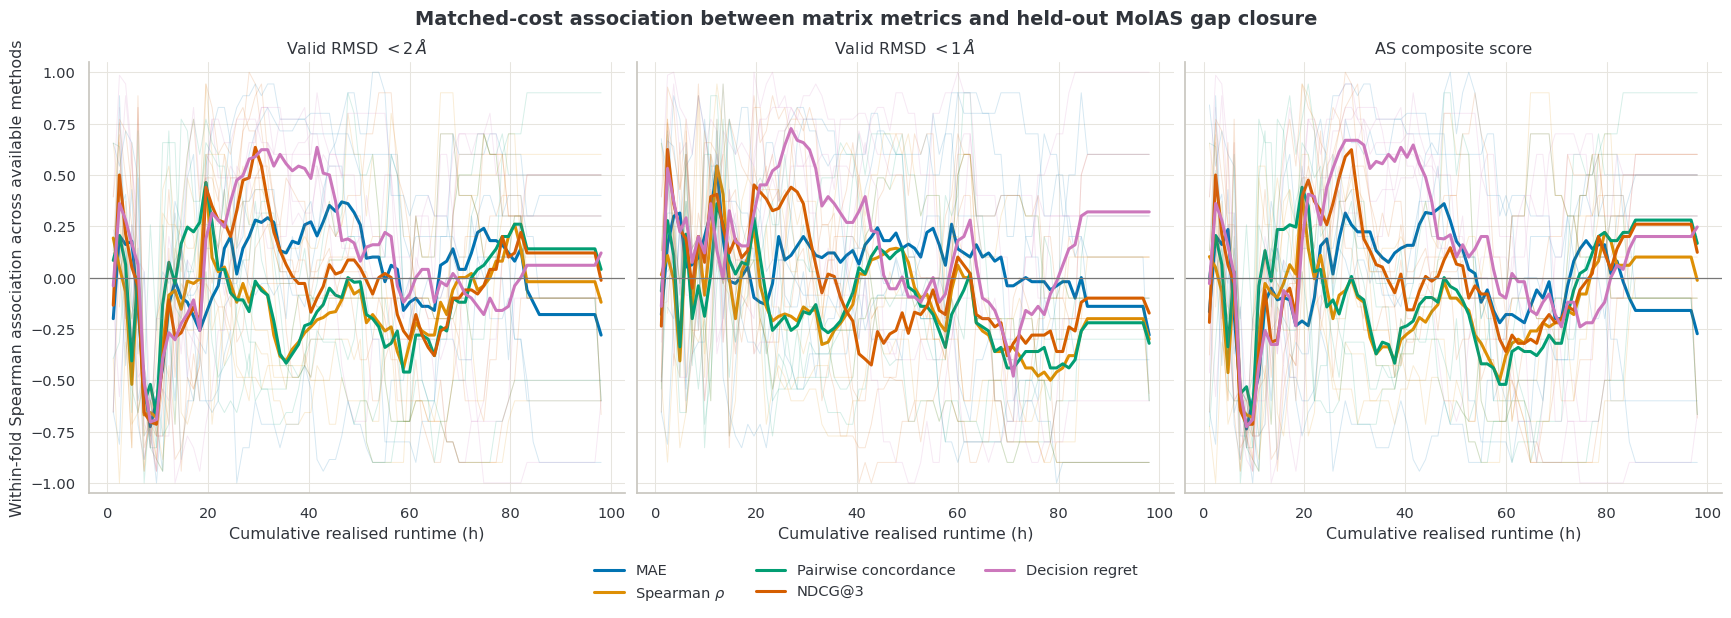

In [114]:
association_colours = sns.color_palette("colorblind", len(upstream_columns))
fig, axes = plt.subplots(1, 3, figsize=(17.2, 5.4), sharex=True, sharey=True, constrained_layout=True)
for ax, downstream_metric in zip(axes, downstream_columns):
    association = matched_correlations[
        matched_correlations["downstream_metric"].eq(downstream_metric)
    ]
    for colour, upstream_metric in zip(association_colours, upstream_columns):
        group = association[association["upstream_metric"].eq(upstream_metric)]
        for _, fold_curve in group.groupby("fold"):
            fold_curve = fold_curve.sort_values("query_cost_h")
            ax.plot(
                fold_curve["query_cost_h"], fold_curve["rho"],
                color=colour, linewidth=0.7, alpha=0.16,
            )
        mean_curve = group.groupby("query_cost_h")["rho"].mean()
        ax.plot(
            mean_curve.index, mean_curve, color=colour, linewidth=2.2,
            label=UPSTREAM_METRICS[upstream_metric][0],
        )
    ax.axhline(0, color="#777777", linewidth=0.9)
    ax.set(
        xlabel="Cumulative realised runtime (h)",
        title=DOWNSTREAM_METRICS[downstream_metric][0],
        ylim=(-1.05, 1.05),
    )
axes[0].set_ylabel("Within-fold Spearman association across available methods")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
fig.suptitle(
    "Matched-cost association between matrix metrics and held-out MolAS gap closure",
    fontsize=14, fontweight="semibold",
)
save_figure(fig, "matched_cost_primary_association")
plt.show()


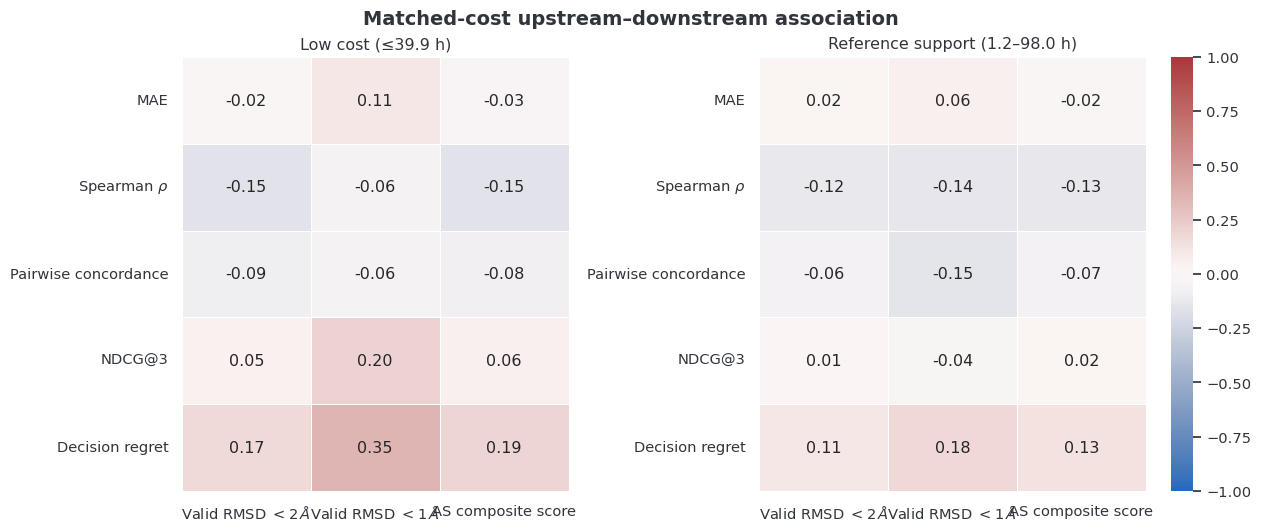

In [115]:
association_tables = []
for region, subset in {
    f"Low cost (≤{low_cost_max_h:.1f} h)": matched_correlations[matched_correlations["query_cost_h"].le(low_cost_max_h)],
    f"Reference support ({aligned_cost_lower:.1f}–{aligned_cost_upper:.1f} h)": matched_correlations,
}.items():
    table = subset.groupby(["upstream_metric", "downstream_metric"])["rho"].mean().unstack("downstream_metric")
    table = table.reindex(index=upstream_columns, columns=downstream_columns)
    association_tables.append((region, table))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), constrained_layout=True)
for ax, (region, table) in zip(axes, association_tables):
    shown = table.rename(index={key: value[0] for key, value in UPSTREAM_METRICS.items()}, columns={key: value[0] for key, value in DOWNSTREAM_METRICS.items()})
    sns.heatmap(shown, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f", linewidths=0.4, cbar=ax is axes[-1], ax=ax)
    ax.set(title=region, xlabel=None, ylabel=None)
fig.suptitle("Matched-cost upstream–downstream association", fontsize=14, fontweight="semibold")
save_figure(fig, "matched_cost_association_heatmaps")
plt.show()


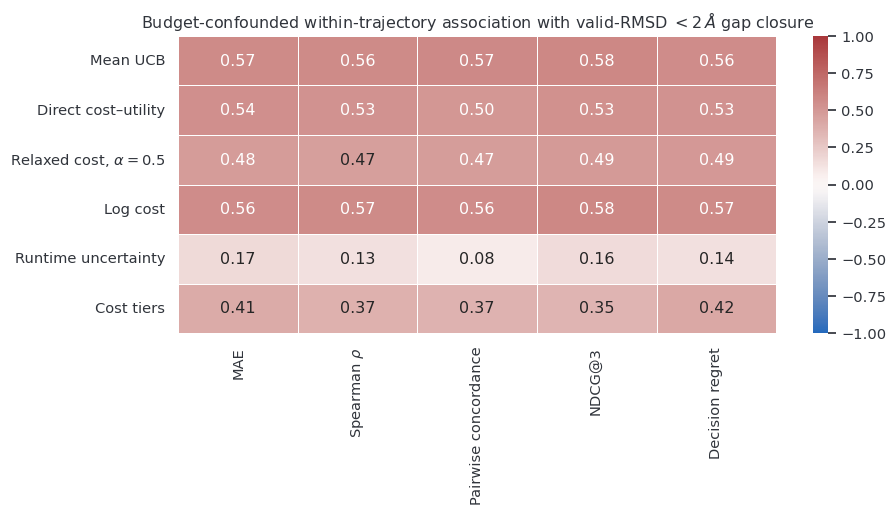

**Raw pooled correlations — descriptive only; budget-confounded.**

,"Valid RMSD $<2\,\AA$","Valid RMSD $<1\,\AA$",AS composite score
MAE,0.381,0.674,0.446
Spearman $\rho$,0.406,0.694,0.471
Pairwise concordance,0.342,0.602,0.407
NDCG@3,0.407,0.710,0.478
Decision regret,0.452,0.749,0.522


In [116]:
trajectory_correlations = []
for (method, fold), group in paired.groupby(["method", "fold"]):
    for upstream_metric in upstream_columns:
        sign = 1 if UPSTREAM_METRICS[upstream_metric][2] else -1
        for downstream_metric in downstream_columns:
            values = group[[upstream_metric, downstream_metric]].dropna()
            rho = spearmanr(sign * values[upstream_metric], values[downstream_metric]).statistic if len(values) >= 4 else np.nan
            trajectory_correlations.append({
                "method": method,
                "fold": fold,
                "upstream_metric": upstream_metric,
                "downstream_metric": downstream_metric,
                "rho": rho,
            })
trajectory_correlations = pd.DataFrame(trajectory_correlations)

trajectory_table = (
    trajectory_correlations[trajectory_correlations["downstream_metric"].eq("gap_closed_valid_rmsd_2")]
    .groupby(["method", "upstream_metric"])["rho"].mean()
    .unstack("upstream_metric").reindex(index=METHODS, columns=upstream_columns)
    .rename(index=METHOD_LABELS, columns={key: value[0] for key, value in UPSTREAM_METRICS.items()})
)
fig, ax = plt.subplots(figsize=(9.5, 5.3))
sns.heatmap(trajectory_table, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f", linewidths=0.4, ax=ax)
ax.set(title=r"Budget-confounded within-trajectory association with valid-RMSD $<2\,\AA$ gap closure", xlabel=None, ylabel=None)
fig.tight_layout()
save_figure(fig, "trajectory_association")
plt.show()

raw_pooled = pd.DataFrame(index=upstream_columns, columns=downstream_columns, dtype=float)
for upstream_metric in upstream_columns:
    sign = 1 if UPSTREAM_METRICS[upstream_metric][2] else -1
    for downstream_metric in downstream_columns:
        raw_pooled.at[upstream_metric, downstream_metric] = spearmanr(
            sign * paired[upstream_metric], paired[downstream_metric], nan_policy="omit"
        ).statistic
raw_pooled = raw_pooled.rename(index={key: value[0] for key, value in UPSTREAM_METRICS.items()}, columns={key: value[0] for key, value in DOWNSTREAM_METRICS.items()})
display(Markdown("**Raw pooled correlations — descriptive only; budget-confounded.**"))
display(raw_pooled.round(3))


## 13. Fixed-horizon efficiency summaries

Normalised area under the learning curve (AULC) is integrated over the explicitly configured absolute-cost horizons. A method–horizon enters the summary only when all five folds cover both endpoints. Comparisons are paired by fold against Mean UCB and oriented so that positive values always favour the alternative. Thin connections show the five paired fold differences; the heavy marker is their macro mean.


**Actual foldwise support for every fixed AULC horizon.**

,horizon_lower_h,horizon_upper_h,method,fold,observed_cost_min_h,observed_cost_max_h,spans_horizon
0,5.0,20.0,Cost tiers,0,0.965,98.230,True
1,5.0,20.0,Cost tiers,1,1.172,98.251,True
2,5.0,20.0,Cost tiers,2,0.856,99.883,True
3,5.0,20.0,Cost tiers,3,0.890,97.981,True
4,5.0,20.0,Cost tiers,4,0.809,98.412,True
5,5.0,20.0,Direct cost–utility,0,0.965,98.230,True
6,5.0,20.0,Direct cost–utility,1,1.172,98.251,True
7,5.0,20.0,Direct cost–utility,2,0.856,99.883,True
8,5.0,20.0,Direct cost–utility,3,0.890,97.981,True
9,5.0,20.0,Direct cost–utility,4,0.809,98.412,True


,horizon_lower_h,horizon_upper_h,horizon_label
0,5.0,20.0,all-method
1,5.0,50.0,supported subset; excluded: Runtime uncertainty


metric                                                         MAE  Spearman $\rho$  Pairwise concordance  NDCG@3  Decision regret  Valid RMSD $<2\,\AA$  \
horizon_lower_h horizon_upper_h method                                                                                                                     
5.0             20.0            Cost tiers                  0.2268           0.4883                0.7449  0.8428           0.0864                6.8504   
                                Direct cost–utility         0.1873           0.5205                0.7617  0.8566           0.0756                6.4785   
                                Log cost                    0.2043           0.4971                0.7467  0.8485           0.0797                4.6848   
                                Mean UCB                    0.2795           0.4931                0.7569  0.8314           0.1187               11.4742   
                                Relaxed cost, $\alpha=0.5$  0.2097           0.5022                0.7510  0.8496           0.0854                5.5668   
                                Runtime uncertainty         0.1839           0.5201                0.7553  0.8612           0.0704                5.9261   
                50.0            Cost tiers                  0.1349           0.5982                0.7948  0.8847           0.0461                8.8983   
                                Direct cost–utility         0.1206           0.6090                0.8008  0.8934           0.0419                8.7106   
                                Log cost                    0.1247           0.6049                0.7974  0.8879           0.0420                8.6532   
                                Mean UCB                    0.1709           0.5690                0.7866  0.8809           0.0502               11.7202   
                                Relaxed cost, $\alpha=0.5$  0.1267           0.6083                0.8005  0.8888           0.0447                7.5712   

metric                                                      Valid RMSD $<1\,\AA$  AS composite score  
horizon_lower_h horizon_upper_h method                                                                
5.0             20.0            Cost tiers                                8.1843             10.0899  
                                Direct cost–utility                       8.5630              9.3280  
                                Log cost                                  6.5544              6.7403  
                                Mean UCB                                  8.2156             15.9085  
                                Relaxed cost, $\alpha=0.5$                7.2028              8.3132  
                                Runtime uncertainty                       8.1199              8.7400  
                50.0            Cost tiers                               11.2894             13.4446  
                                Direct cost–utility                       9.9100             12.4100  
                                Log cost                                 10.2204             12.4688  
                                Mean UCB                                 12.1050             17.3492  
                                Relaxed cost, $\alpha=0.5$                9.4267             11.2959

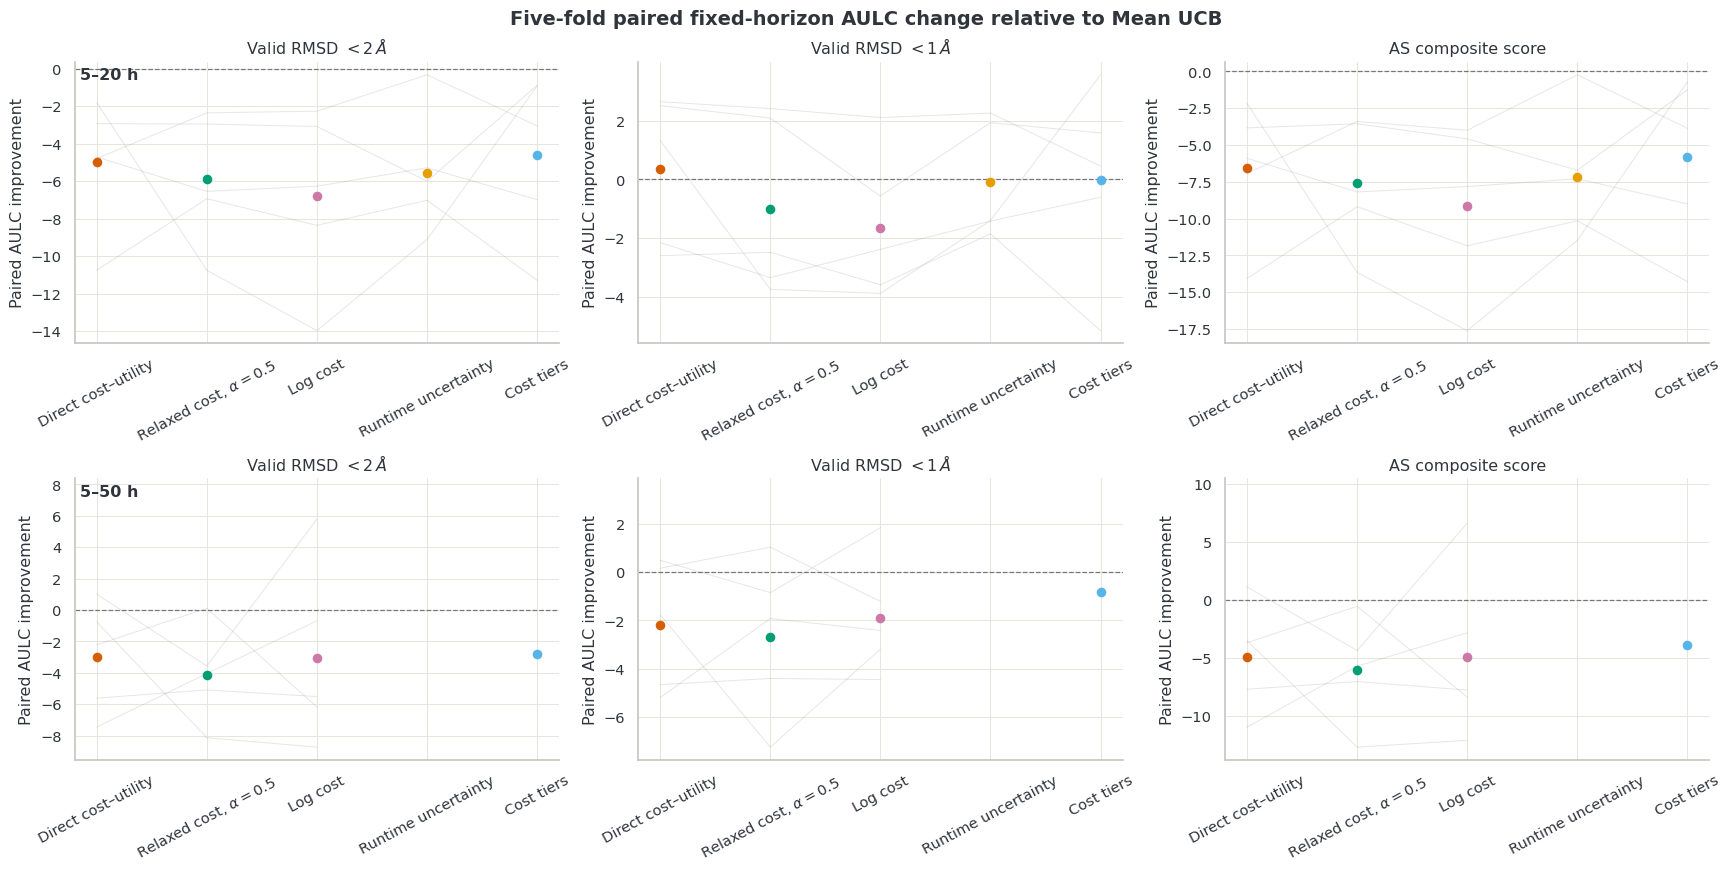

In [117]:
integrate_curve = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
aulc_columns = upstream_columns + downstream_columns

aulc_support_rows = []
for lower_h, upper_h in AULC_HORIZONS_H:
    for (method, fold), group in paired.groupby(["method", "fold"]):
        minimum, maximum = group["query_cost_h"].min(), group["query_cost_h"].max()
        aulc_support_rows.append({
            "horizon_lower_h": lower_h,
            "horizon_upper_h": upper_h,
            "method": method,
            "fold": fold,
            "observed_cost_min_h": minimum,
            "observed_cost_max_h": maximum,
            "spans_horizon": minimum <= lower_h and maximum >= upper_h,
        })
aulc_support_by_horizon = pd.DataFrame(aulc_support_rows)
aulc_horizon_labels = {}
for horizon, group in aulc_support_by_horizon.groupby(["horizon_lower_h", "horizon_upper_h"]):
    complete_methods = set(
        group.groupby("method")["spans_horizon"].agg(lambda values: len(values) == len(FOLDS) and values.all())
        .loc[lambda values: values].index
    )
    excluded = [method_label(method) for method in METHODS if method not in complete_methods]
    aulc_horizon_labels[horizon] = (
        "all-method" if complete_methods == set(METHODS)
        else "supported subset; excluded: " + ", ".join(excluded)
    )
display(Markdown("**Actual foldwise support for every fixed AULC horizon.**"))
display(aulc_support_by_horizon.assign(method=lambda frame: frame["method"].map(method_label)).round(3))
display(pd.DataFrame([
    {"horizon_lower_h": lower, "horizon_upper_h": upper, "horizon_label": label}
    for (lower, upper), label in aulc_horizon_labels.items()
]))


def fixed_horizon_aulc(curve, x, y, lower, upper):
    curve = curve.groupby(x, as_index=False)[y].mean().dropna().sort_values(x)
    if len(curve) < 2 or curve[x].min() > lower or curve[x].max() < upper:
        return np.nan
    interior = curve[curve[x].between(lower, upper)]
    grid = np.unique(np.r_[lower, interior[x].to_numpy(), upper])
    values = np.interp(grid, curve[x], curve[y])
    return integrate_curve(values, grid) / (upper - lower)


aulc_rows = []
for horizon_lower_h, horizon_upper_h in AULC_HORIZONS_H:
    if horizon_lower_h >= horizon_upper_h:
        raise ValueError(f"Invalid AULC horizon: {(horizon_lower_h, horizon_upper_h)}")
    for (method, fold), group in paired.groupby(["method", "fold"]):
        for metric in aulc_columns:
            value = fixed_horizon_aulc(
                group, "query_cost_h", metric, horizon_lower_h, horizon_upper_h
            )
            if np.isfinite(value):
                aulc_rows.append({
                    "horizon_lower_h": horizon_lower_h,
                    "horizon_upper_h": horizon_upper_h,
                    "method": method,
                    "fold": fold,
                    "metric": metric,
                    "aulc": value,
                })
aulc_all = pd.DataFrame(aulc_rows)
aulc_coverage = (
    aulc_all.groupby(["horizon_lower_h", "horizon_upper_h", "method", "metric"])["fold"]
    .nunique().rename("n_folds").reset_index()
)
aulc_complete_keys = aulc_coverage.loc[
    aulc_coverage["n_folds"].eq(len(FOLDS)),
    ["horizon_lower_h", "horizon_upper_h", "method", "metric"],
]
aulc = aulc_all.merge(
    aulc_complete_keys,
    on=["horizon_lower_h", "horizon_upper_h", "method", "metric"],
    how="inner",
    validate="many_to_one",
)

reference_aulc = (
    aulc[aulc["method"].eq(REFERENCE_METHOD)]
    [["horizon_lower_h", "horizon_upper_h", "fold", "metric", "aulc"]]
    .rename(columns={"aulc": "reference_aulc"})
)
aulc_differences = aulc.merge(
    reference_aulc,
    on=["horizon_lower_h", "horizon_upper_h", "fold", "metric"],
    how="inner",
    validate="many_to_one",
)
directions = {
    **{metric: values[2] for metric, values in UPSTREAM_METRICS.items()},
    **{metric: values[2] for metric, values in DOWNSTREAM_METRICS.items()},
}
aulc_differences["oriented_delta"] = np.where(
    aulc_differences["metric"].map(directions),
    aulc_differences["aulc"] - aulc_differences["reference_aulc"],
    aulc_differences["reference_aulc"] - aulc_differences["aulc"],
)
aulc_difference_summary = (
    aulc_differences.groupby(
        ["horizon_lower_h", "horizon_upper_h", "method", "metric"], as_index=False
    ).agg(
        mean_oriented_delta=("oriented_delta", "mean"),
        fold_min=("oriented_delta", "min"),
        fold_max=("oriented_delta", "max"),
        n_folds=("fold", "nunique"),
    )
    .loc[lambda frame: frame["n_folds"].eq(len(FOLDS))]
)

aulc_table = (
    aulc.groupby(["horizon_lower_h", "horizon_upper_h", "method", "metric"])["aulc"].mean()
    .unstack("metric").reindex(columns=aulc_columns)
    .rename(
        index=METHOD_LABELS,
        columns={
            **{key: value[0] for key, value in UPSTREAM_METRICS.items()},
            **{key: value[0] for key, value in DOWNSTREAM_METRICS.items()},
        },
    )
)
display(aulc_table.round(4))

horizons = list(AULC_HORIZONS_H)
fig, axes = plt.subplots(
    len(horizons), 3,
    figsize=(17.2, 4.3 * len(horizons)),
    squeeze=False,
    constrained_layout=True,
)
alternative_order = [method for method in METHODS if method != REFERENCE_METHOD]
positions = np.arange(len(alternative_order))
for row_index, (lower_h, upper_h) in enumerate(horizons):
    for ax, (metric, (title, _, _)) in zip(axes[row_index], DOWNSTREAM_METRICS.items()):
        subset = aulc_differences[
            aulc_differences["horizon_lower_h"].eq(lower_h)
            & aulc_differences["horizon_upper_h"].eq(upper_h)
            & aulc_differences["metric"].eq(metric)
            & aulc_differences["method"].isin(alternative_order)
        ]
        for fold, fold_data in subset.groupby("fold"):
            fold_data = fold_data.set_index("method").reindex(alternative_order)
            ax.plot(positions, fold_data["oriented_delta"], color="#777777", linewidth=0.7, alpha=0.18)
        means = subset.groupby("method")["oriented_delta"].mean().reindex(alternative_order)
        for position, method in enumerate(alternative_order):
            if pd.notna(means.loc[method]):
                ax.scatter(position, means.loc[method], s=35, color=METHOD_COLOURS[method], zorder=3)
        ax.axhline(0, color="#777777", linewidth=0.9, linestyle="--")
        ax.set(
            title=title,
            ylabel="Paired AULC improvement",
            xticks=positions,
            xticklabels=[method_label(method) for method in alternative_order],
        )
        ax.tick_params(axis="x", rotation=28)
    axes[row_index, 0].text(
        0.01, 0.98, f"{lower_h:g}–{upper_h:g} h",
        transform=axes[row_index, 0].transAxes, ha="left", va="top", fontweight="semibold",
    )
fig.suptitle("Five-fold paired fixed-horizon AULC change relative to Mean UCB", fontsize=14, fontweight="semibold")
save_figure(fig, "fixed_horizon_aulc_differences")
plt.show()


## 14. Compact audit summary

The checkpoint table below uses only fold-complete method–percentage pairs. The AULC table reports paired fold differences over the configured fixed horizons; no “winner” is declared from five folds, overlapping trajectories, or unequal coverage.


In [118]:
reference_percentage = 10 if 10 in set(downstream_overall["percentage"]) else int(downstream_overall["percentage"].min())
reference_cost = (
    query_metrics_complete[query_metrics_complete["percentage"].eq(reference_percentage)]
    .groupby("method")["query_cost_h"].mean().rename(f"cost_h_at_{reference_percentage}pct")
)
reference_downstream = (
    downstream_overall[downstream_overall["percentage"].eq(reference_percentage)]
    .set_index("method")[[*RAW_DOWNSTREAM_METRICS, *DOWNSTREAM_METRICS]]
    .add_suffix(f"_at_{reference_percentage}pct")
)
method_summary = (
    reference_cost.to_frame().join(reference_downstream)
    .reindex(METHODS).rename(index=METHOD_LABELS)
)
display(method_summary.round(4))

display(Markdown("**Five-fold paired AULC differences; positive favours the alternative over Mean UCB.**"))
display(
    aulc_difference_summary.assign(
        method=lambda frame: frame["method"].map(method_label),
        metric=lambda frame: frame["metric"].map({
            **{key: value[0] for key, value in UPSTREAM_METRICS.items()},
            **{key: value[0] for key, value in DOWNSTREAM_METRICS.items()},
        }),
    ).round(4)
)

low_cost_primary = (
    matched_correlations[
        matched_correlations["query_cost_h"].le(low_cost_max_h)
        & matched_correlations["downstream_metric"].eq("gap_closed_valid_rmsd_2")
    ]
    .groupby("upstream_metric")["rho"].mean().sort_values(ascending=False)
)
if len(low_cost_primary):
    best_metric = low_cost_primary.index[0]
    display(Markdown(
        f"**Strongest descriptive low-cost matched association with valid-RMSD < 2 Å gap closure:** "
        f"{UPSTREAM_METRICS[best_metric][0]} "
        f"(mean within-fold Spearman ρ = {low_cost_primary.iloc[0]:.3f})."
    ))


,cost_h_at_10pct,valid_rmsd_2_at_10pct,valid_rmsd_1_at_10pct,as_score_at_10pct,gap_closed_valid_rmsd_2_at_10pct,gap_closed_valid_rmsd_1_at_10pct,gap_closed_as_score_at_10pct
method,,,,,,,
Mean UCB,9.7226,71.5330,46.0853,0.6851,11.6500,7.0160,15.9217
Direct cost–utility,6.4901,69.3913,44.5090,0.6631,4.0640,2.8176,5.5361
"Relaxed cost, $\alpha=0.5$",7.7425,70.1812,45.4873,0.6708,6.9492,5.4745,9.2698
Log cost,7.4224,70.3689,45.1091,0.6718,7.7528,4.4747,9.8820
Runtime uncertainty,5.7658,69.3331,44.8894,0.6633,3.9256,3.8111,5.6800
Cost tiers,8.9638,70.4619,46.2392,0.6743,7.9002,7.3957,10.9172


**Five-fold paired AULC differences; positive favours the alternative over Mean UCB.**

,horizon_lower_h,horizon_upper_h,method,metric,mean_oriented_delta,fold_min,fold_max,n_folds
0,5.0,20.0,Cost tiers,Decision regret,0.0322,0.0257,0.0438,5
1,5.0,20.0,Cost tiers,AS composite score,-5.8185,-14.2811,-0.7025,5
2,5.0,20.0,Cost tiers,"Valid RMSD $<1\,\AA$",-0.0314,-5.1489,3.5618,5
3,5.0,20.0,Cost tiers,"Valid RMSD $<2\,\AA$",-4.6238,-11.2864,-0.8837,5
4,5.0,20.0,Cost tiers,MAE,0.0527,0.0295,0.0620,5
...,...,...,...,...,...,...,...,...
83,5.0,50.0,"Relaxed cost, $\alpha=0.5$","Valid RMSD $<2\,\AA$",-4.1491,-8.1384,0.1005,5
84,5.0,50.0,"Relaxed cost, $\alpha=0.5$",MAE,0.0442,0.0293,0.0577,5
85,5.0,50.0,"Relaxed cost, $\alpha=0.5$",NDCG@3,0.0079,0.0013,0.0148,5
86,5.0,50.0,"Relaxed cost, $\alpha=0.5$",Pairwise concordance,0.0139,0.0061,0.0271,5


**Strongest descriptive low-cost matched association with valid-RMSD < 2 Å gap closure:** Decision regret (mean within-fold Spearman ρ = 0.166).

## 15. Export

The cached tables retain fold identity and are suitable for subsequent paired analyses. Figures and tidy CSVs are written only when `SAVE_OUTPUTS` is enabled.


In [119]:
tables = {
    "coverage_inventory_current_notebook": coverage_inventory,
    "query_metrics": query_metrics,
    "query_fold_coverage": query_fold_coverage,
    "algorithm_allocation": allocation,
    "fold_matrix_metrics": fold_metrics,
    "matrix_fold_coverage": matrix_fold_coverage,
    "per_algorithm_matrix_metrics": algorithm_metrics,
    "cross_fold_stability": stability,
    "downstream_fold_metrics": downstream,
    "downstream_fold_coverage": downstream_fold_coverage,
    "downstream_overall_metrics": downstream_overall,
    "downstream_baselines": downstream_baselines,
    "downstream_cost_aligned_fold_curves": downstream_cost_aligned_folds,
    "downstream_cost_aligned_macro_curves": downstream_cost_aligned_macro,
    "downstream_attainment_frontiers": attainment_costs,
    "downstream_attainment_costs": attainment_costs,
    "full_acquisition_audit": full_acquisition_audit,
    "run_readiness": run_readiness,
    "diagnostic_pairwise_cost_matches_all": pairwise_cost_matches,
    "diagnostic_budget_checkpoints": matched_budget_checkpoints,
    "diagnostic_checkpoint_audit": checkpoint_audit,
    "diagnostic_algorithm_allocation_at_landmarks": allocation_landmark_summary,
    "diagnostic_algorithm_allocation_at_landmarks": allocation_landmark_summary,
    "diagnostic_outcome_bins": outcome_bin_summary,
    "diagnostic_choice_shares": downstream_choice_summary,
    "downstream_choice_curves": downstream_choice_curves,
    "diagnostic_choice_transitions": transition_summary,
    "diagnostic_grouped_choice_transitions": grouped_transition_summary,
    "diagnostic_pb_validity_by_fold": validity_by_fold,
    "diagnostic_pb_validity_summary": validity_summary,
    "diagnostic_unimol_surfdock_by_fold": us_counts,
    "diagnostic_unimol_surfdock_summary": us_boundary_summary,
    "diagnostic_paired_fold_deltas": paired_fold_deltas,
    "diagnostic_paired_instance_summary": paired_instance_summary,
    "matched_cost_correlations": matched_correlations,
    "trajectory_correlations": trajectory_correlations,
    "aulc_foldwise_support": aulc_support_by_horizon,
    "aulc_foldwise_support": aulc_support_by_horizon,
    "aulc_coverage": aulc_coverage,
    "aulc_by_fold": aulc,
    "aulc_paired_differences": aulc_differences,
    "aulc_paired_difference_summary": aulc_difference_summary,
    "audit_log": audits,
}
if SAVE_OUTPUTS:
    for name, table in tables.items():
        table.to_csv(TABLE_DIR / f"{name}.csv", index=False)
    aulc_table.to_csv(TABLE_DIR / "aulc_summary.csv")

print(f"Tables:  {TABLE_DIR}")
print(f"Figures: {FIGURE_DIR}")


Tables:  /data1/home/jw1017/AS_Dock/results/MolAS/AL_analysis/port_as_primary_reconciled_20260827_v1/tables
Figures: /data1/home/jw1017/AS_Dock/results/MolAS/AL_analysis/port_as_primary_reconciled_20260827_v1/figures


## 16. Acquisition internals: utility, predicted cost, and realised cost

These reconciliation diagnostics use the utility and runtime-model outputs logged for every *queried* cell (excluding round 0's runtime-blind seed sample) to ask why: is the runtime model well calibrated, and does reweighting by predicted cost actually shift the acquisition operating point? These describe cells that were queried, not the full unqueried candidate pool, which is not observable from these files.

In [120]:
ACQUISITION_COLUMNS = ["query_order", "round", "algorithm", "utility", "predicted_runtime_mean", "predicted_runtime_sd", "runtime"]


def load_master_events(method, fold):
    available = [p for p in PERCENTAGES if query_path(method, fold, p).exists()]
    if not available:
        return None
    events = pd.read_csv(query_path(method, fold, max(available)), usecols=ACQUISITION_COLUMNS).sort_values("query_order")
    events["algorithm"] = events["algorithm"].map(normalise_algorithm)
    events["query_cost_h"] = events["runtime"].cumsum() / 3600  # realised cost at each event, matching query_cost_h elsewhere
    events["method"], events["fold"] = method, fold
    return events[events["round"] > 0]


with ThreadPoolExecutor(max_workers=N_JOBS) as executor:
    method_folds = [(m, f) for m in METHODS for f in FOLDS]
    parts = [part for part in executor.map(lambda mf: load_master_events(*mf), method_folds) if part is not None]
acquisition_events = pd.concat(parts, ignore_index=True)
cost_aware_methods = [
    m for m in METHODS
    if acquisition_events.loc[acquisition_events["method"].eq(m), "predicted_runtime_mean"].notna().any()
]
print(f"Loaded {len(acquisition_events):,} post-seed queried-cell events; cost model active for: {[method_label(m) for m in cost_aware_methods]}")

Loaded 528,702 post-seed queried-cell events; cost model active for: ['Direct cost–utility', 'Relaxed cost, $\\alpha=0.5$', 'Log cost', 'Runtime uncertainty', 'Cost tiers']


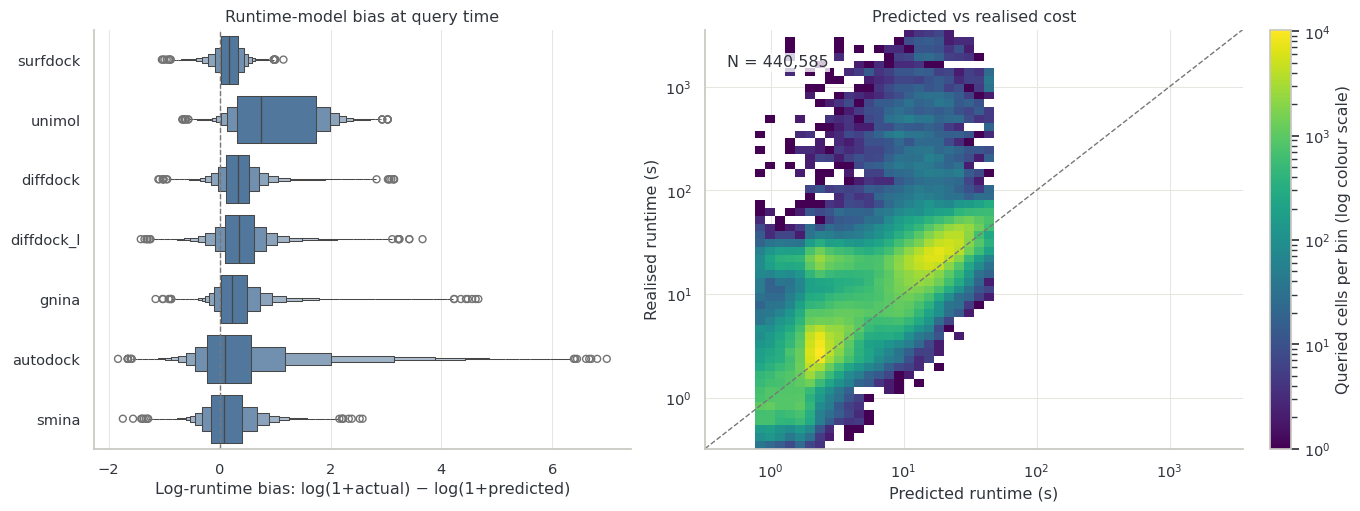

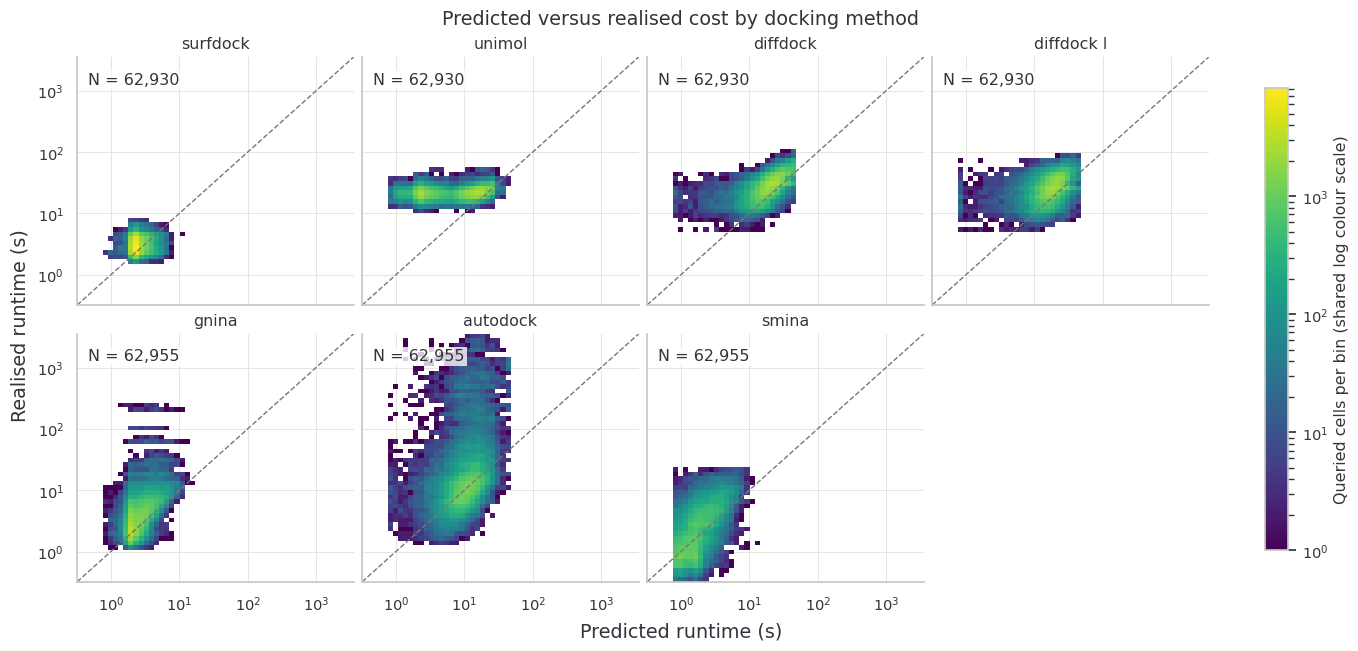

**Acquisition-method heterogeneity check.** Each completed policy contributes the same number of post-seed cells, but orders them differently and predicts at different model states. The adjusted columns subtract each docking method's pooled median bias. This is descriptive, not a test of predictor equivalence; Mean UCB is absent because it did not use the runtime predictor.

,method,n_queried,median_log_bias,sd_log_bias,median_absolute_log_error,median_algorithm_adjusted_bias,sd_algorithm_adjusted_bias
0,Direct cost–utility,88117,0.331,0.631,0.358,0.070,0.598
1,"Relaxed cost, $\alpha=0.5$",88117,0.310,0.637,0.352,0.041,0.579
2,Log cost,88117,0.316,0.634,0.356,0.047,0.582
3,Runtime uncertainty,88117,0.138,0.551,0.242,-0.132,0.529
4,Cost tiers,88117,0.244,0.647,0.342,-0.018,0.571


**Uncertainty support and exploratory raw-scale coverage.** Coverage is reported only where the exported SD is positive; it is not treated as a calibrated predictive interval because the producer's SD definition remains unverified.

,method,algorithm,n_queried,n_positive_sd
0,Cost tiers,autodock,12591,0
1,Cost tiers,diffdock,12586,0
2,Cost tiers,diffdock_l,12586,0
3,Cost tiers,gnina,12591,0
4,Cost tiers,smina,12591,0
5,Cost tiers,surfdock,12586,0
6,Cost tiers,unimol,12586,0
7,Direct cost–utility,autodock,12591,0
8,Direct cost–utility,diffdock,12586,0
9,Direct cost–utility,diffdock_l,12586,0


,method,algorithm,nominal_raw_90pct_coverage
0,Runtime uncertainty,autodock,0.287
1,Runtime uncertainty,diffdock,0.345
2,Runtime uncertainty,diffdock_l,0.292
3,Runtime uncertainty,gnina,0.352
4,Runtime uncertainty,smina,0.295
5,Runtime uncertainty,surfdock,0.531
6,Runtime uncertainty,unimol,0.242


In [121]:
from matplotlib.colors import LogNorm

calibration = acquisition_events.dropna(subset=["predicted_runtime_mean"]).copy()
calibration["log_bias"] = np.log1p(calibration["runtime"]) - np.log1p(calibration["predicted_runtime_mean"])
positive_calibration = calibration[
    calibration["predicted_runtime_mean"].gt(0) & calibration["runtime"].gt(0)
].copy()

runtime_limits = (
    positive_calibration[["predicted_runtime_mean", "runtime"]].min().min(),
    positive_calibration[["predicted_runtime_mean", "runtime"]].max().max(),
)
runtime_bins = np.geomspace(*runtime_limits, 55)


def runtime_histogram(data):
    return np.histogram2d(data["predicted_runtime_mean"], data["runtime"], bins=(runtime_bins, runtime_bins))[0]


def draw_runtime_density(ax, data, norm, title):
    counts = runtime_histogram(data)
    mesh = ax.pcolormesh(
        runtime_bins, runtime_bins, np.ma.masked_equal(counts.T, 0),
        cmap="viridis", norm=norm, shading="auto",
    )
    ax.plot(runtime_limits, runtime_limits, color="#777777", linestyle="--", linewidth=1)
    ax.set(xscale="log", yscale="log", xlim=runtime_limits, ylim=runtime_limits, title=title)
    ax.text(
        0.04, 0.94, f"N = {len(data):,}", transform=ax.transAxes, va="top", color="#30343B",
        bbox={"facecolor": "white", "alpha": 0.78, "edgecolor": "none", "pad": 1.5},
    )
    return mesh


pooled_norm = LogNorm(vmin=1, vmax=max(2, runtime_histogram(positive_calibration).max()))
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), constrained_layout=True)
sns.boxenplot(data=calibration, x="log_bias", y="algorithm", order=ALGORITHMS, color="#4477AA", ax=axes[0])
axes[0].axvline(0, color="#777777", linestyle="--", linewidth=1)
axes[0].set(xlabel="Log-runtime bias: log(1+actual) − log(1+predicted)", ylabel=None, title="Runtime-model bias at query time")

mesh = draw_runtime_density(axes[1], positive_calibration, pooled_norm, "Predicted vs realised cost")
axes[1].set(xlabel="Predicted runtime (s)", ylabel="Realised runtime (s)")
fig.colorbar(mesh, ax=axes[1], label="Queried cells per bin (log colour scale)")
save_figure(fig, "acquisition_runtime_calibration")
plt.show()

algorithm_counts = {
    algorithm: runtime_histogram(positive_calibration[positive_calibration["algorithm"].eq(algorithm)])
    for algorithm in ALGORITHMS
}
algorithm_norm = LogNorm(vmin=1, vmax=max(2, max(counts.max() for counts in algorithm_counts.values())))
fig, axes = plt.subplots(2, 4, figsize=(13.5, 6.4), sharex=True, sharey=True, constrained_layout=True)
for ax, algorithm in zip(axes.flat, ALGORITHMS):
    subset = positive_calibration[positive_calibration["algorithm"].eq(algorithm)]
    mesh = draw_runtime_density(ax, subset, algorithm_norm, algorithm.replace("_", " "))
axes.flat[-1].set_visible(False)
fig.supxlabel("Predicted runtime (s)")
fig.supylabel("Realised runtime (s)")
fig.colorbar(mesh, ax=axes.ravel().tolist(), label="Queried cells per bin (shared log colour scale)", shrink=0.88)
fig.suptitle("Predicted versus realised cost by docking method")
save_figure(fig, "acquisition_runtime_calibration_by_algorithm")
plt.show()

calibration["algorithm_adjusted_log_bias"] = (
    calibration["log_bias"] - calibration.groupby("algorithm")["log_bias"].transform("median")
)
calibration["absolute_log_error"] = calibration["log_bias"].abs()
acquisition_calibration_summary = (
    calibration.groupby("method", as_index=False)
    .agg(
        n_queried=("runtime", "size"),
        median_log_bias=("log_bias", "median"),
        sd_log_bias=("log_bias", "std"),
        median_absolute_log_error=("absolute_log_error", "median"),
        median_algorithm_adjusted_bias=("algorithm_adjusted_log_bias", "median"),
        sd_algorithm_adjusted_bias=("algorithm_adjusted_log_bias", "std"),
    )
    .set_index("method").reindex(cost_aware_methods).reset_index()
)
display(Markdown(
    "**Acquisition-method heterogeneity check.** Each completed policy contributes the same number of post-seed cells, but "
    "orders them differently and predicts at different model states. The adjusted columns subtract each docking method's "
    "pooled median bias. This is descriptive, not a test of predictor equivalence; Mean UCB is absent because it did not use "
    "the runtime predictor."
))
display(acquisition_calibration_summary.assign(method=lambda frame: frame["method"].map(method_label)).round(3))
if SAVE_OUTPUTS:
    acquisition_calibration_summary.to_csv(TABLE_DIR / "runtime_calibration_by_acquisition_method.csv", index=False)

uncertainty_rows = calibration[calibration["predicted_runtime_sd"].gt(0)].copy()
uncertainty_support = (
    calibration.groupby(["method", "algorithm"], as_index=False)
    .agg(n_queried=("runtime", "size"), n_positive_sd=("predicted_runtime_sd", lambda values: values.gt(0).sum()))
)
if len(uncertainty_rows):
    uncertainty_rows["within_nominal_raw_90pct"] = (
        (uncertainty_rows["runtime"] - uncertainty_rows["predicted_runtime_mean"]).abs()
        <= 1.645 * uncertainty_rows["predicted_runtime_sd"]
    )
    nominal_raw_coverage = (
        uncertainty_rows.groupby(["method", "algorithm"])["within_nominal_raw_90pct"]
        .mean().rename("nominal_raw_90pct_coverage").reset_index()
    )
else:
    nominal_raw_coverage = pd.DataFrame(columns=["method", "algorithm", "nominal_raw_90pct_coverage"])
display(Markdown(
    "**Uncertainty support and exploratory raw-scale coverage.** Coverage is reported only where the exported SD is positive; "
    "it is not treated as a calibrated predictive interval because the producer's SD definition remains unverified."
))
display(uncertainty_support.assign(method=lambda frame: frame["method"].map(method_label)))
display(nominal_raw_coverage.assign(method=lambda frame: frame["method"].map(method_label)).round(3))


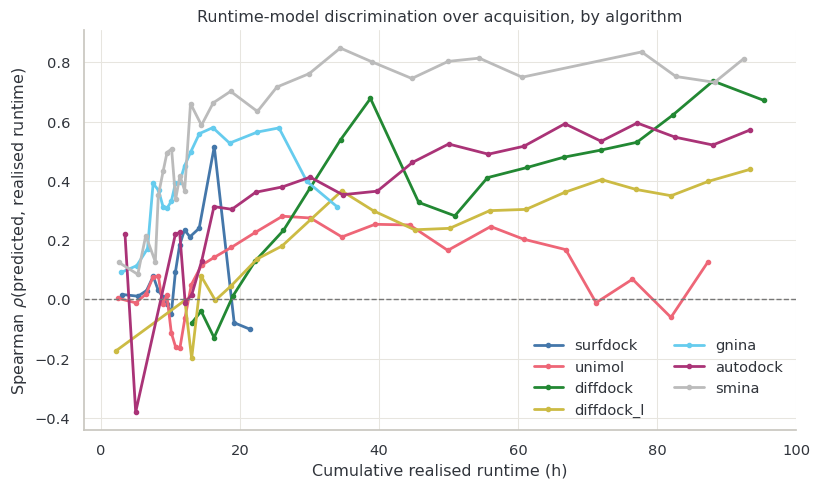

In [122]:
def cost_discrimination_by_algorithm(data, n_bins=30, min_bin_size=15):
    # Spearman rho within each cost bin is oriented: positive means costlier cells are correctly predicted as costlier.
    edges = np.unique(np.quantile(data["query_cost_h"], np.linspace(0, 1, n_bins + 1)))
    bin_index = np.clip(np.digitize(data["query_cost_h"], edges[1:-1]), 0, len(edges) - 2)
    rows = []
    for (algorithm, cost_bin), group in data.groupby(["algorithm", bin_index]):
        if len(group) < min_bin_size:
            continue
        rho = spearmanr(group["predicted_runtime_mean"], group["runtime"]).statistic
        rows.append({"algorithm": algorithm, "query_cost_h": group["query_cost_h"].mean(), "rho": rho, "n": len(group)})
    return pd.DataFrame(rows)


discrimination = cost_discrimination_by_algorithm(calibration)

fig, ax = plt.subplots(figsize=(9.2, 5.2))
for algorithm in ALGORITHMS:
    curve = discrimination[discrimination["algorithm"].eq(algorithm)].sort_values("query_cost_h")
    if curve.empty:
        continue
    ax.plot(curve["query_cost_h"], curve["rho"], color=ALGORITHM_COLOURS[algorithm], linewidth=2, marker="o", markersize=3, label=algorithm)
ax.axhline(0, color="#777777", linestyle="--", linewidth=1)
ax.set(
    xlabel="Cumulative realised runtime (h)", ylabel=r"Spearman $\rho$(predicted, realised runtime)",
    title="Runtime-model discrimination over acquisition, by algorithm",
)
ax.legend(frameon=False, ncol=2)
save_figure(fig, "acquisition_runtime_discrimination")
plt.show()

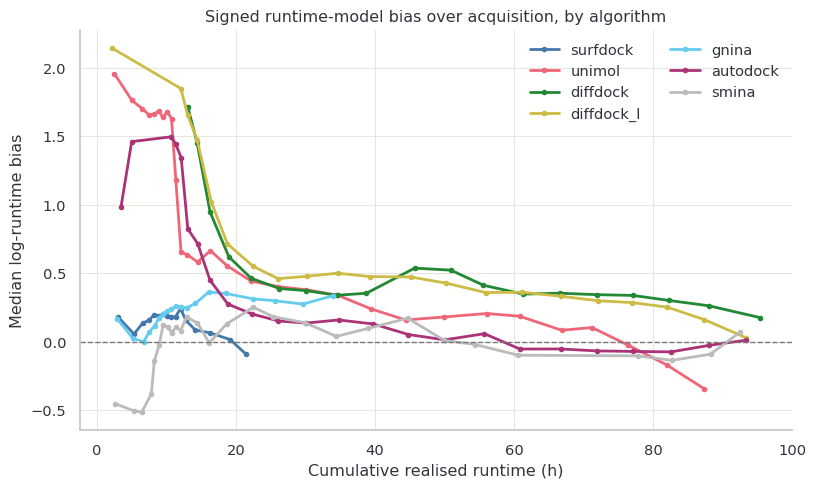

**Signed calibration:** positive values mean the model underpredicts realised runtime; negative values mean it overpredicts.

In [123]:
def signed_calibration_by_algorithm(data, n_bins=30, min_bin_size=15):
    edges = np.unique(np.quantile(data["query_cost_h"], np.linspace(0, 1, n_bins + 1)))
    bin_index = np.clip(np.digitize(data["query_cost_h"], edges[1:-1]), 0, len(edges) - 2)
    residual = np.log1p(data["runtime"]) - np.log1p(data["predicted_runtime_mean"])
    rows = []
    for (algorithm, cost_bin), group in data.assign(log_bias=residual).groupby(["algorithm", bin_index]):
        if len(group) < min_bin_size:
            continue
        rows.append({
            "algorithm": algorithm,
            "query_cost_h": group["query_cost_h"].mean(),
            "median_log_bias": group["log_bias"].median(),
            "underprediction_fraction": group["log_bias"].gt(0).mean(),
            "n": len(group),
        })
    return pd.DataFrame(rows)


signed_calibration = signed_calibration_by_algorithm(calibration)

fig, ax = plt.subplots(figsize=(9.2, 5.2))
for algorithm in ALGORITHMS:
    curve = signed_calibration[signed_calibration["algorithm"].eq(algorithm)].sort_values("query_cost_h")
    if curve.empty:
        continue
    ax.plot(
        curve["query_cost_h"], curve["median_log_bias"],
        color=ALGORITHM_COLOURS[algorithm], linewidth=2, marker="o", markersize=3,
        label=algorithm,
    )
ax.axhline(0, color="#777777", linestyle="--", linewidth=1)
ax.set(
    xlabel="Cumulative realised runtime (h)",
    ylabel="Median log-runtime bias",
    title="Signed runtime-model bias over acquisition, by algorithm",
)
ax.legend(frameon=False, ncol=2)
save_figure(fig, "acquisition_runtime_signed_calibration")
plt.show()

display(Markdown(
    "**Signed calibration:** positive values mean the model underpredicts realised runtime; "
    "negative values mean it overpredicts."
))


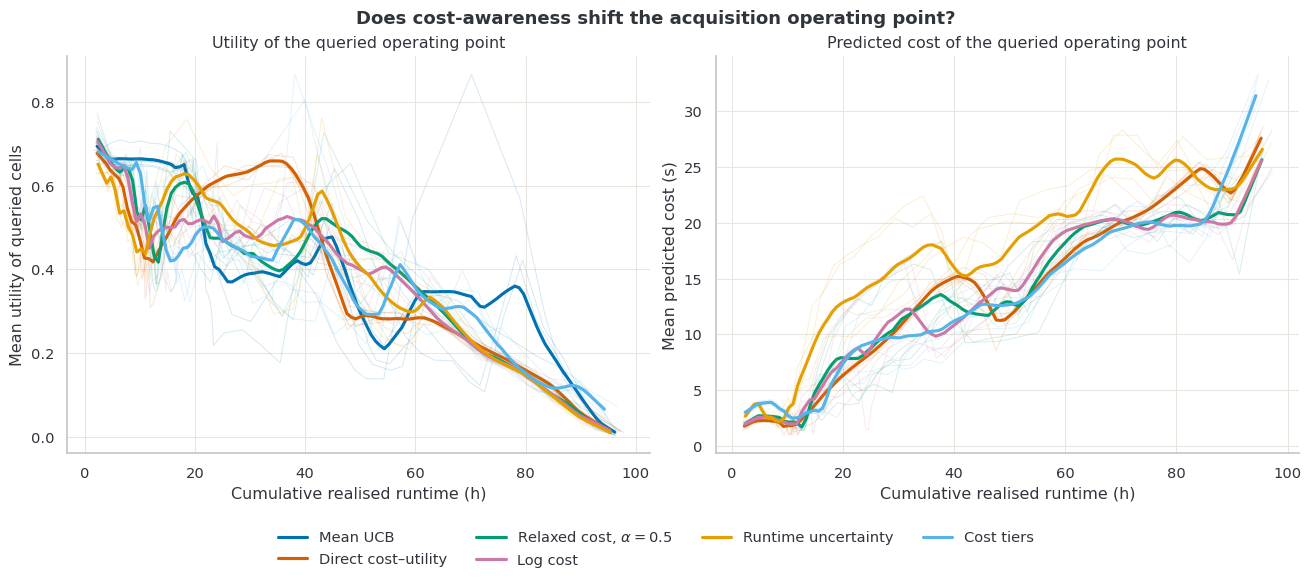

**Spearman correlation between utility and predicted cost among queried cells (negative = policy trades utility for cheapness).**

,utility_vs_cost_rho
Cost tiers,-0.359
Direct cost–utility,-0.263
Log cost,-0.332
"Relaxed cost, $\alpha=0.5$",-0.321
Runtime uncertainty,-0.292


In [124]:
def bin_by_cost(data, value_column, n_bins=40):
    # Equal-count cost bins per method-fold turn the raw per-query noise into a legible mean trend.
    rows = []
    for (method, fold), group in data.groupby(["method", "fold"]):
        edges = np.unique(np.quantile(group["query_cost_h"], np.linspace(0, 1, n_bins + 1)))
        if len(edges) < 2:
            continue
        bin_index = np.clip(np.digitize(group["query_cost_h"], edges[1:-1]), 0, len(edges) - 2)
        binned = group.groupby(bin_index)[["query_cost_h", value_column]].mean()
        binned["method"], binned["fold"] = method, fold
        rows.append(binned)
    return pd.concat(rows, ignore_index=True)


utility_binned = bin_by_cost(acquisition_events, "utility")
cost_binned = bin_by_cost(calibration, "predicted_runtime_mean")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
draw_fold_curve_panel(
    axes[0], utility_binned, "query_cost_h", "utility",
    "Cumulative realised runtime (h)", "Mean utility of queried cells", "Utility of the queried operating point",
)
draw_fold_curve_panel(
    axes[1], cost_binned, "query_cost_h", "predicted_runtime_mean",
    "Cumulative realised runtime (h)", "Mean predicted cost (s)", "Predicted cost of the queried operating point",
)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
fig.suptitle("Does cost-awareness shift the acquisition operating point?", fontsize=13, fontweight="semibold")
save_figure(fig, "acquisition_operating_point")
plt.show()

rank_association = pd.Series(
    {method_label(m): spearmanr(g["utility"], g["predicted_runtime_mean"]).statistic for m, g in calibration.groupby("method")},
    name="utility_vs_cost_rho",
).to_frame()
display(Markdown("**Spearman correlation between utility and predicted cost among queried cells (negative = policy trades utility for cheapness).**"))
display(rank_association.round(3))

In [125]:
runtime = pd.read_csv("/data1/home/jw1017/AS_Dock/data/MolAS/moad_runtime_trimmed.csv")

runtime.describe()

,surfdock_runtime,unimol_runtime,diffdock_runtime,diffdock_l_runtime,gnina_runtime,autodock_runtime,smina_runtime
count,3179.000000,3179.000000,3179.000000,3179.000000,3179.000000,3179.000000,3179.000000
mean,3.178285,22.026571,30.149476,28.001163,4.953672,48.367409,2.826719
std,0.809052,4.176817,12.056983,11.551889,8.340480,193.525231,2.761219
min,1.518635,11.680000,5.282832,5.187457,1.153948,1.288047,0.321645
25%,2.546243,19.110000,21.452184,19.564596,2.377275,7.656431,0.979093
50%,3.027440,21.650000,29.102863,27.109111,3.608358,12.003860,1.743825
75%,3.706621,24.335000,37.085876,34.775995,5.523969,19.320119,3.704165
max,7.276286,55.220000,99.162905,90.837141,259.143132,3547.965529,22.772781


## 17. Reconstructed-matrix stability as a retrospective stopping proxy

This section evaluates a long-term stopping-module idea without treating the current provenance-confounded downstream cohort as confirmatory evidence. The design follows the **stabilising predictions** principle: recent model-pair agreements are averaged over a longevity window rather than trusting one unusually stable transition ([Bloodgood & Vijay-Shanker, 2014](https://arxiv.org/abs/1409.5165)). It also separates a stopping **metric** from its threshold/patience **condition** and reports cost–regret trade-offs instead of selecting a universal threshold ([Pullar-Strecker et al., 2023](https://doi.org/10.1007/s10994-022-06253-1)).

For every method/fold/seed trajectory, matrices are ordered by acquisition checkpoint. A window of `w` matrices averages its `w-1` consecutive transition values (`w = 2, 3, 5`):

- **Top-1 agreement:** deterministic top-algorithm agreement, using the notebook's canonical algorithm order to break exact ties.
- **Top-3 Jaccard:** rowwise overlap of the two top-three algorithm sets.
- **Top-weighted Kendall agreement:** weighted tau-b ranking concordance mapped to `[0,1]`, retaining tie penalties. An algorithm's joint rank is its better rank in the two matrices; it receives hyperbolic weight `1/(r+1)`, and a pair receives the sum of its item weights, following the additive top-weighting construction of [Vigna (2015)](https://vigna.di.unimi.it/ftp/papers/WeightedTau.pdf).
- **Score/margin stability:** `1 - 0.5 × (normalised mean absolute score drift + normalised top1–top2 margin drift)`, clipped to `[0,1]`. Each row is normalised by the pooled score range across the two matrices.

All summaries preserve folds. Retrospective stopping is evaluated only at checkpoints with an existing downstream MolAS output. Consequently, its stop times are coarse-grid simulations—not evidence that the rule could already be deployed at every acquisition step. High stability is tested against next-checkpoint gain, next absolute change, and best remaining observed gain.

In [126]:
from analyses.port_as_stopping import (
    STABILITY_SIGNALS,
    downstream_gain_table,
    pair_stability,
    proxy_associations,
    rolling_stability,
    simulate_rules,
    summarise_rules,
)

STABILITY_WINDOWS = (2, 3, 5)
STOPPING_THRESHOLDS = (0.90, 0.95, 0.98, 0.99, 0.995, 0.999)
STOPPING_PATIENCES = (1, 2, 3)
STABILITY_CACHE_VERSION = "matrix-stability-v1"
STABILITY_CACHE_PATH = ANALYSIS_ROOT / "cache/matrix_stability.pkl"
STABILITY_MODULE_PATH = MOLAS_REPO_ROOT / "analyses/port_as_stopping.py"


def stability_trajectory(method_fold):
    method, fold = method_fold
    checkpoints = query_metrics[
        query_metrics["method"].eq(method) & query_metrics["fold"].eq(fold)
    ].set_index("percentage")
    rows, previous, previous_percentage = [], None, None
    for percentage in sorted(set(checkpoints.index) & set(PERCENTAGES)):
        matrix, *_ = read_reconstruction(matrix_path(method, fold, percentage), train_ids[fold])
        if matrix is None:
            continue
        current = matrix.to_numpy(float)
        if previous is not None:
            checkpoint = checkpoints.loc[percentage]
            rows.append({
                "method": method,
                "fold": fold,
                "al_seed": AL_SEED,
                "previous_percentage": previous_percentage,
                "percentage": percentage,
                "query_cost_h": float(checkpoint["query_cost_h"]),
                "query_count": int(checkpoint["query_count"]),
                "query_fraction": float(checkpoint["query_fraction"]),
                **pair_stability(previous, current),
            })
        previous, previous_percentage = current, percentage
    return rows


stability_signature = hashlib.sha256(json.dumps({
    "version": STABILITY_CACHE_VERSION,
    "upstream": input_signature("upstream"),
    "module": hashlib.sha256(STABILITY_MODULE_PATH.read_bytes()).hexdigest(),
    "windows": STABILITY_WINDOWS,
}, sort_keys=True).encode()).hexdigest()

stability_payload = None
if STABILITY_CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    candidate = pd.read_pickle(STABILITY_CACHE_PATH)
    if candidate.get("signature") == stability_signature:
        stability_payload = candidate

if stability_payload is None:
    rows = []
    with ThreadPoolExecutor(max_workers=N_JOBS) as executor:
        futures = [
            executor.submit(stability_trajectory, (method, fold))
            for method in METHODS for fold in FOLDS
        ]
        for future in tqdm(as_completed(futures), total=len(futures), desc="Matrix stability"):
            rows.extend(future.result())
    stability_consecutive = pd.DataFrame(rows)
    stability_rolling = rolling_stability(stability_consecutive, STABILITY_WINDOWS)
    stability_payload = {
        "signature": stability_signature,
        "consecutive": stability_consecutive,
        "rolling": stability_rolling,
    }
    pd.to_pickle(stability_payload, STABILITY_CACHE_PATH)

stability_consecutive = stability_payload["consecutive"]
stability_rolling = stability_payload["rolling"]
print(
    f"Computed {len(stability_consecutive):,} consecutive comparisons and "
    f"{len(stability_rolling):,} rolling-window checkpoints across "
    f"{stability_consecutive.groupby(['method', 'fold']).ngroups} fold trajectories."
)


Computed 2,970 consecutive comparisons and 8,790 rolling-window checkpoints across 30 fold trajectories.


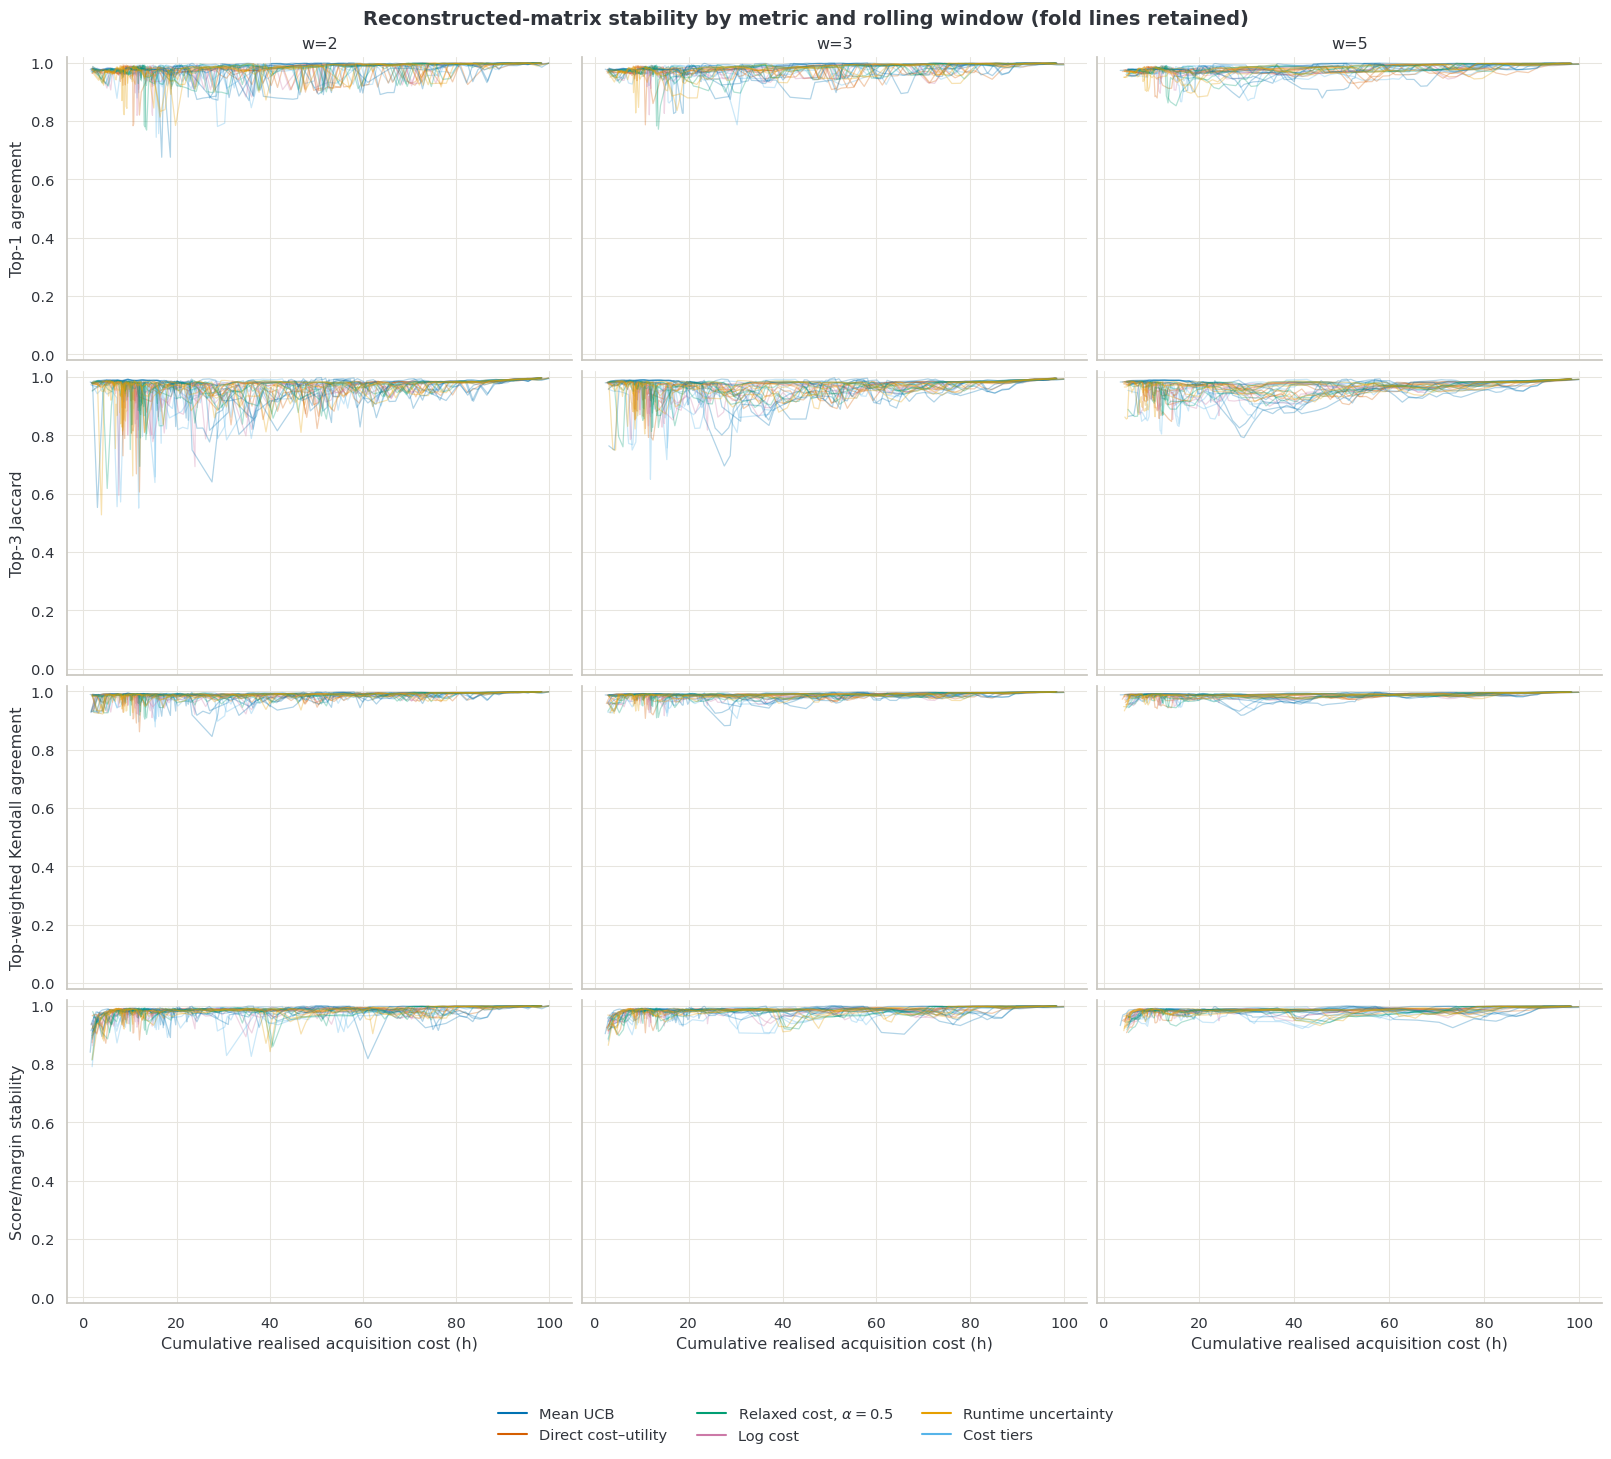

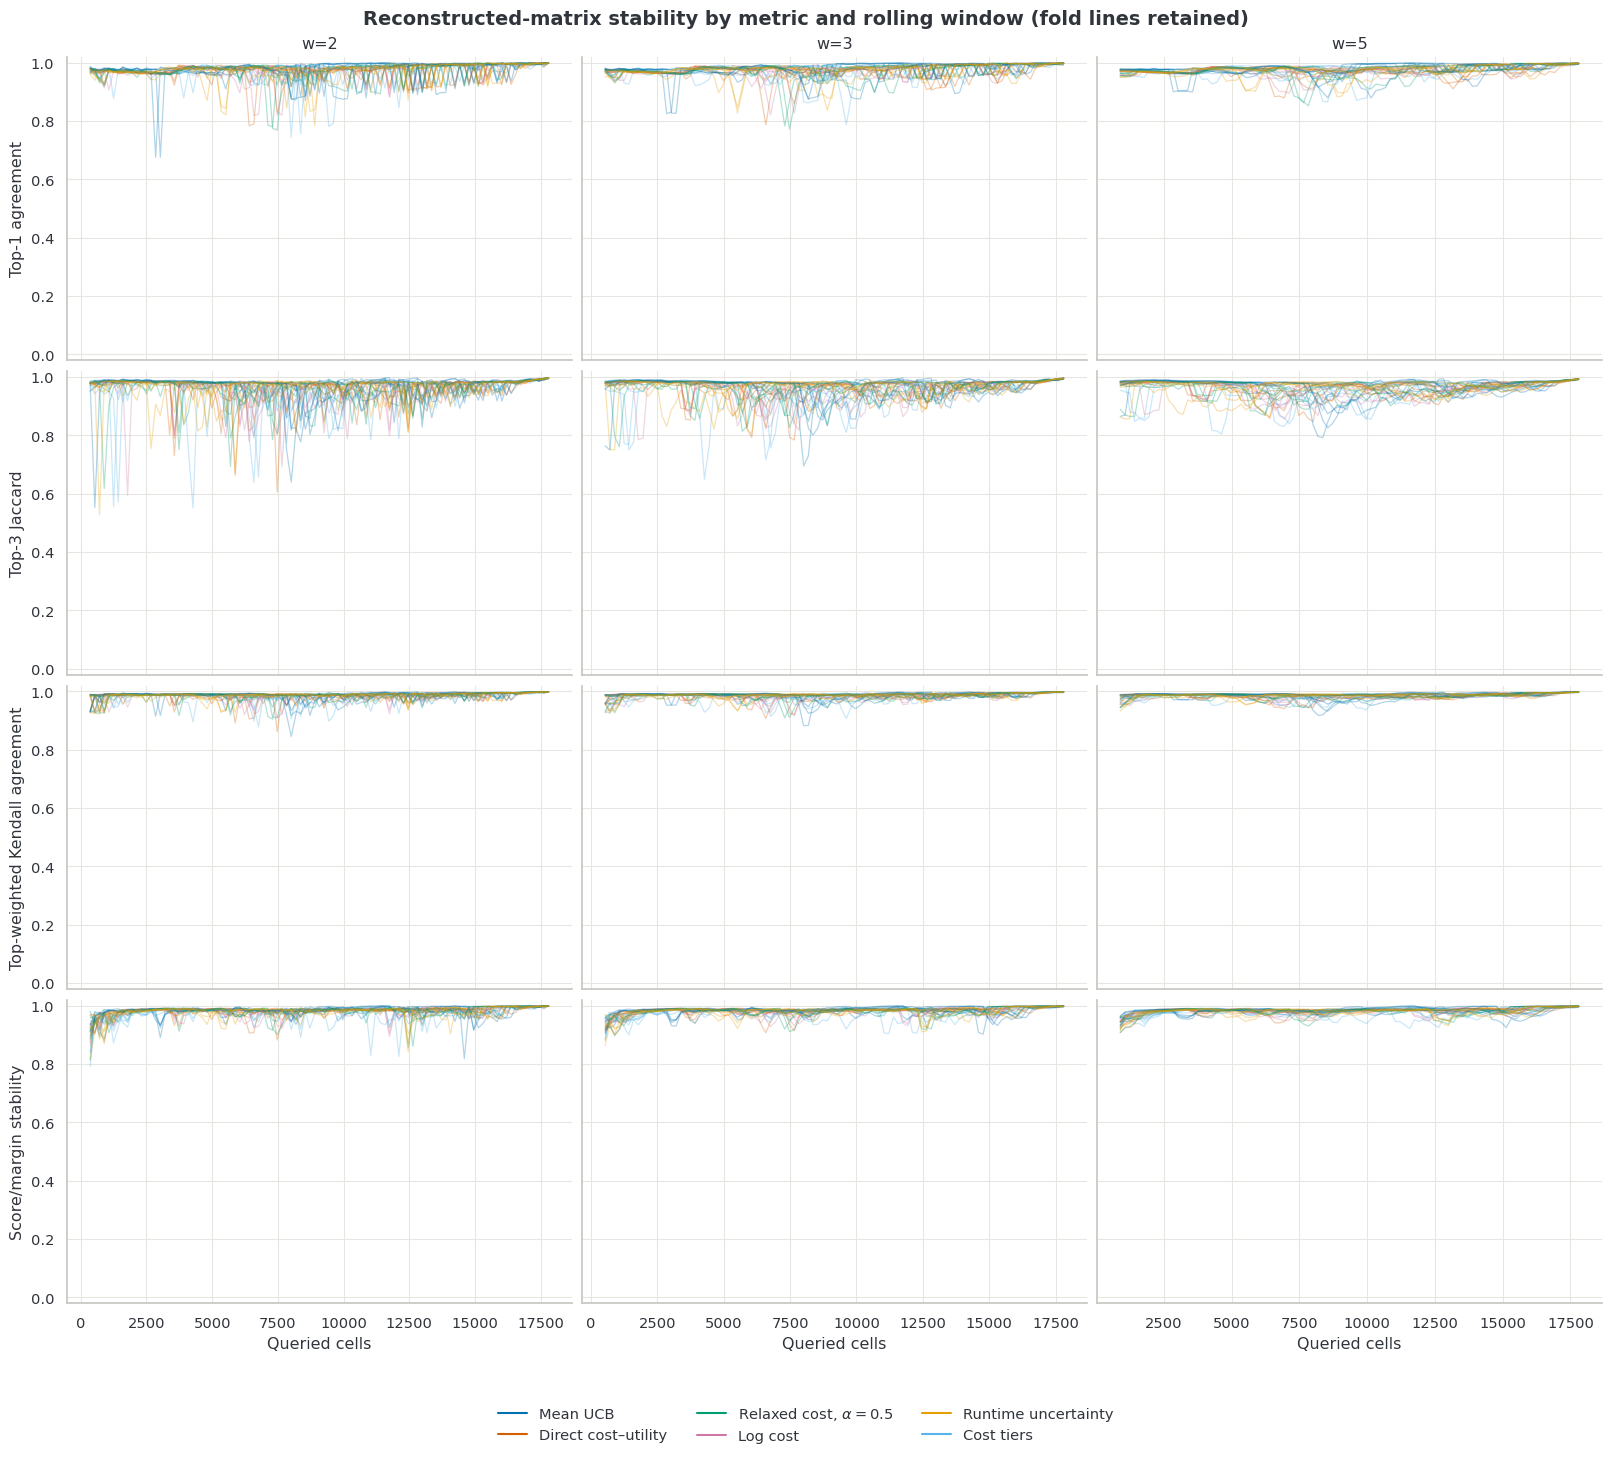

In [127]:
STABILITY_LABELS = {
    "top1_agreement": "Top-1 agreement",
    "top3_jaccard": "Top-3 Jaccard",
    "top_weighted_kendall": "Top-weighted Kendall agreement",
    "score_margin_stability": "Score/margin stability",
}


def plot_stability_trajectories(x, xlabel, filename):
    fig, axes = plt.subplots(
        len(STABILITY_SIGNALS), len(STABILITY_WINDOWS), figsize=(16, 13.5),
        sharex="col", sharey="row", constrained_layout=True,
    )
    for row, signal in enumerate(STABILITY_SIGNALS):
        for column, window in enumerate(STABILITY_WINDOWS):
            ax = axes[row, column]
            subset = stability_rolling[stability_rolling["window"].eq(window)]
            for (method, fold), curve in subset.groupby(["method", "fold"]):
                curve = curve.sort_values(x)
                ax.plot(
                    curve[x], curve[signal], color=METHOD_COLOURS[method],
                    linewidth=0.9, alpha=0.30,
                )
            if row == 0:
                ax.set_title(f"w={window}")
            if column == 0:
                ax.set_ylabel(STABILITY_LABELS[signal])
            if row == len(STABILITY_SIGNALS) - 1:
                ax.set_xlabel(xlabel)
            ax.set_ylim(-0.02, 1.02)
    handles = [
        plt.Line2D([], [], color=METHOD_COLOURS[method], label=method_label(method))
        for method in METHODS
    ]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.075), ncol=3, frameon=False)
    fig.suptitle(
        "Reconstructed-matrix stability by metric and rolling window (fold lines retained)",
        fontsize=14, fontweight="semibold",
    )
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


plot_stability_trajectories("query_cost_h", "Cumulative realised acquisition cost (h)", "matrix_stability_vs_cost")
plot_stability_trajectories("query_count", "Queried cells", "matrix_stability_vs_query_count")


**Retrospective proxy associations.** Negative correlations are directionally consistent with high stability preceding little subsequent change or improvement; trajectory-level values preserve method and fold.

,stability_metric,window,downstream_metric,n_trajectories,median_rho_next_gain,fraction_negative_rho_next_gain,median_rho_next_abs_change,fraction_negative_rho_next_abs_change,median_rho_future_best_gain,fraction_negative_rho_future_best_gain
0,score_margin_stability,2,gap_closed_as_score,30,-0.034,0.733,0.061,0.400,-0.338,0.867
1,score_margin_stability,2,gap_closed_valid_rmsd_1,30,-0.003,0.533,0.137,0.367,-0.520,0.967
2,score_margin_stability,2,gap_closed_valid_rmsd_2,30,-0.067,0.667,0.038,0.433,-0.261,0.900
3,score_margin_stability,3,gap_closed_as_score,30,-0.061,0.567,0.055,0.400,-0.314,0.833
4,score_margin_stability,3,gap_closed_valid_rmsd_1,30,-0.015,0.533,0.091,0.333,-0.489,0.933
5,score_margin_stability,3,gap_closed_valid_rmsd_2,30,-0.064,0.567,0.037,0.400,-0.266,0.800
6,score_margin_stability,5,gap_closed_as_score,30,-0.030,0.600,0.091,0.433,-0.314,0.800
7,score_margin_stability,5,gap_closed_valid_rmsd_1,30,-0.042,0.633,0.112,0.333,-0.536,0.900
8,score_margin_stability,5,gap_closed_valid_rmsd_2,30,-0.044,0.633,0.106,0.433,-0.228,0.800
9,top1_agreement,2,gap_closed_as_score,30,0.072,0.367,-0.023,0.500,-0.234,0.867


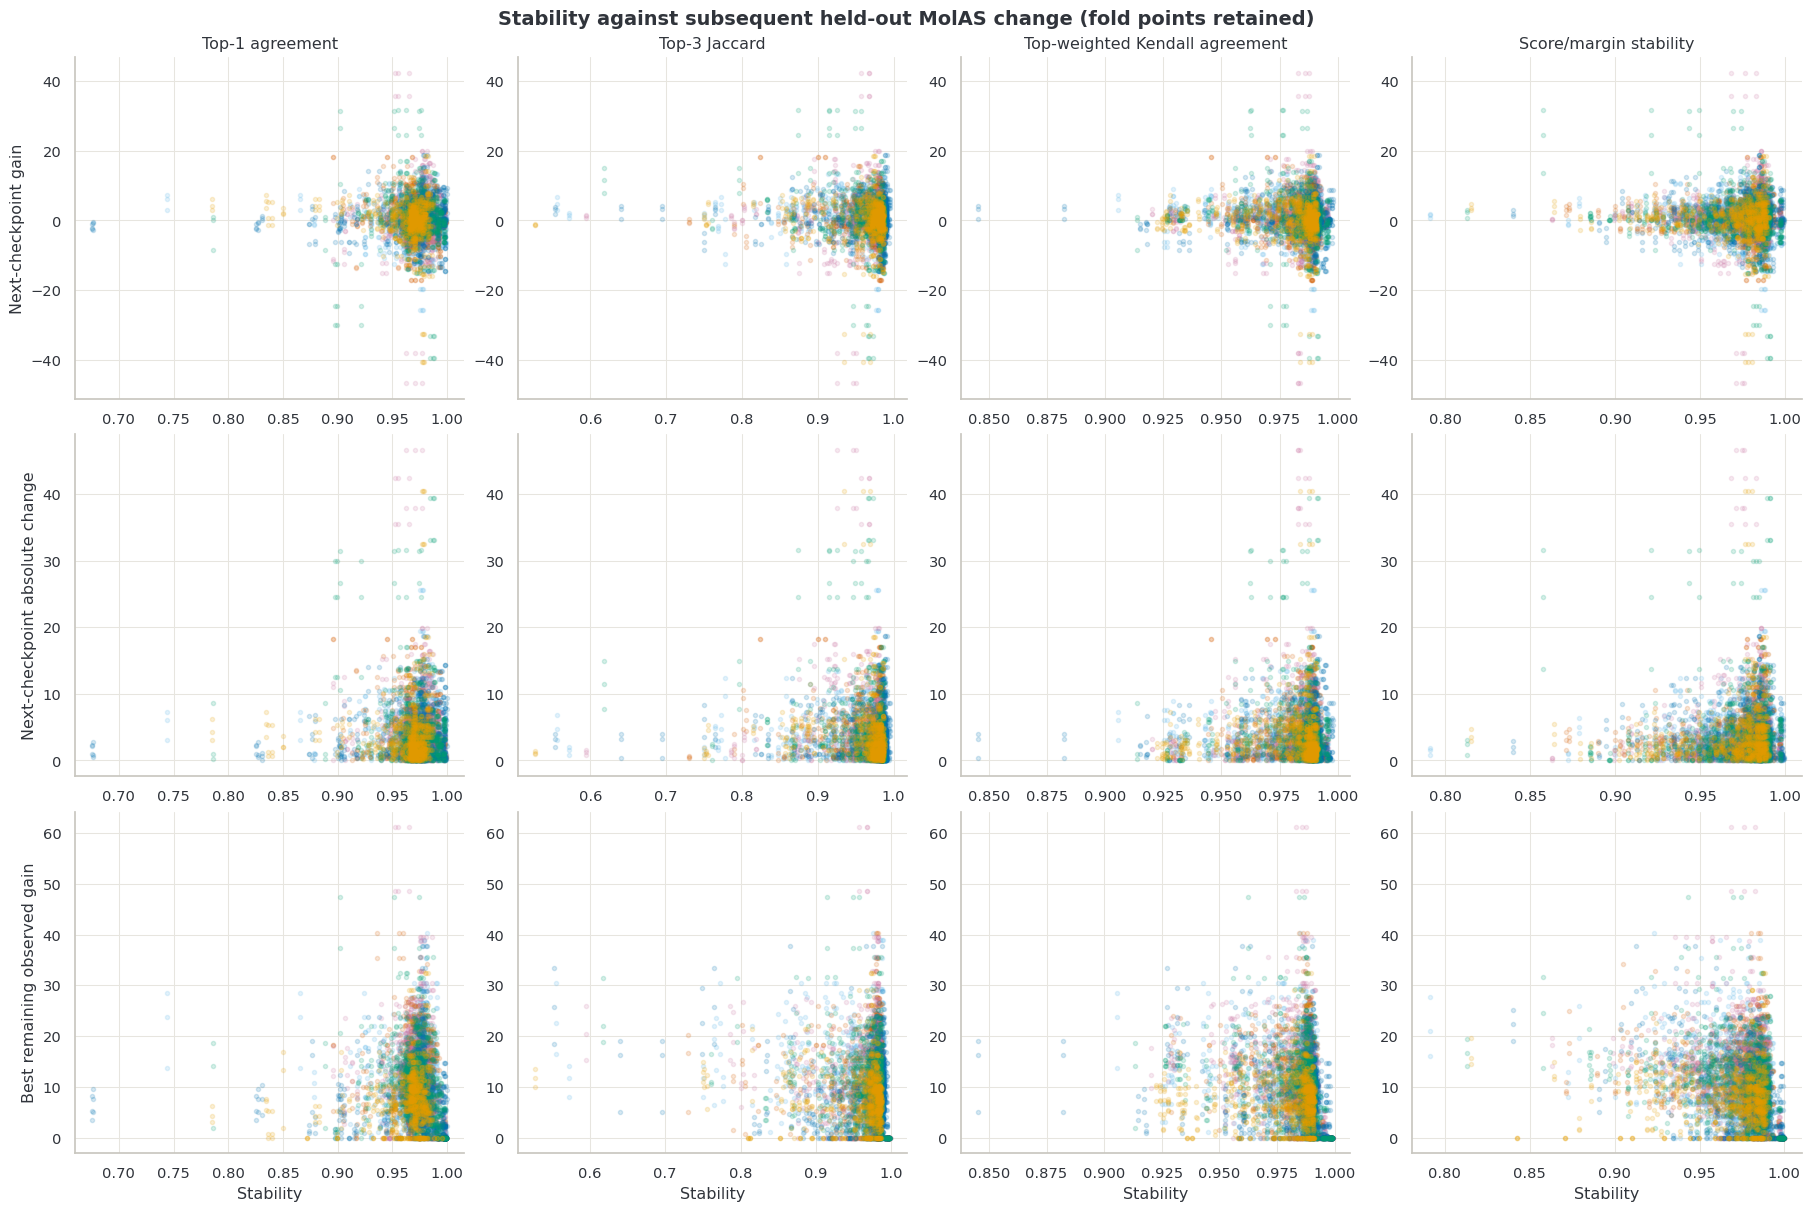

In [128]:
stopping_points = downstream_gain_table(
    stability_rolling,
    downstream,
    tuple(DOWNSTREAM_METRICS),
)
stability_proxy_by_trajectory = proxy_associations(stopping_points)
stability_proxy_summary = (
    stability_proxy_by_trajectory.groupby(
        ["stability_metric", "window", "downstream_metric"], as_index=False
    ).agg(
        n_trajectories=("fold", "size"),
        median_rho_next_gain=("rho_next_gain", "median"),
        fraction_negative_rho_next_gain=("rho_next_gain", lambda values: values.lt(0).mean()),
        median_rho_next_abs_change=("rho_next_abs_change", "median"),
        fraction_negative_rho_next_abs_change=("rho_next_abs_change", lambda values: values.lt(0).mean()),
        median_rho_future_best_gain=("rho_future_best_gain", "median"),
        fraction_negative_rho_future_best_gain=("rho_future_best_gain", lambda values: values.lt(0).mean()),
    )
)
display(Markdown(
    "**Retrospective proxy associations.** Negative correlations are directionally consistent with high stability "
    "preceding little subsequent change or improvement; trajectory-level values preserve method and fold."
))
display(stability_proxy_summary.round(3))

fig, axes = plt.subplots(3, 4, figsize=(18, 12), constrained_layout=True)
targets = (
    ("next_gain", "Next-checkpoint gain"),
    ("next_abs_change", "Next-checkpoint absolute change"),
    ("future_best_gain", "Best remaining observed gain"),
)
for row, (target, label) in enumerate(targets):
    for column, signal in enumerate(STABILITY_SIGNALS):
        ax = axes[row, column]
        subset = stopping_points[stopping_points["stability_metric"].eq(signal)]
        for method, group in subset.groupby("method"):
            ax.scatter(group["stability"], group[target], s=9, alpha=0.16, color=METHOD_COLOURS[method])
        if row == 0:
            ax.set_title(STABILITY_LABELS[signal])
        if column == 0:
            ax.set_ylabel(label)
        if row == len(targets) - 1:
            ax.set_xlabel("Stability")
fig.suptitle("Stability against subsequent held-out MolAS change (fold points retained)", fontsize=14, fontweight="semibold")
save_figure(fig, "matrix_stability_downstream_proxy")
plt.show()
plt.close(fig)


**Cross-method/fold robustness screens.** These declared 1/2 gap-closure-point and 10/20% cost-saving screens are sensitivity summaries, not tuned or recommended deployment thresholds.

,strict_1pp_10pct_screen,lenient_2pp_20pct_screen
downstream_metric,,
gap_closed_as_score,0,0
gap_closed_valid_rmsd_1,0,0
gap_closed_valid_rmsd_2,0,0


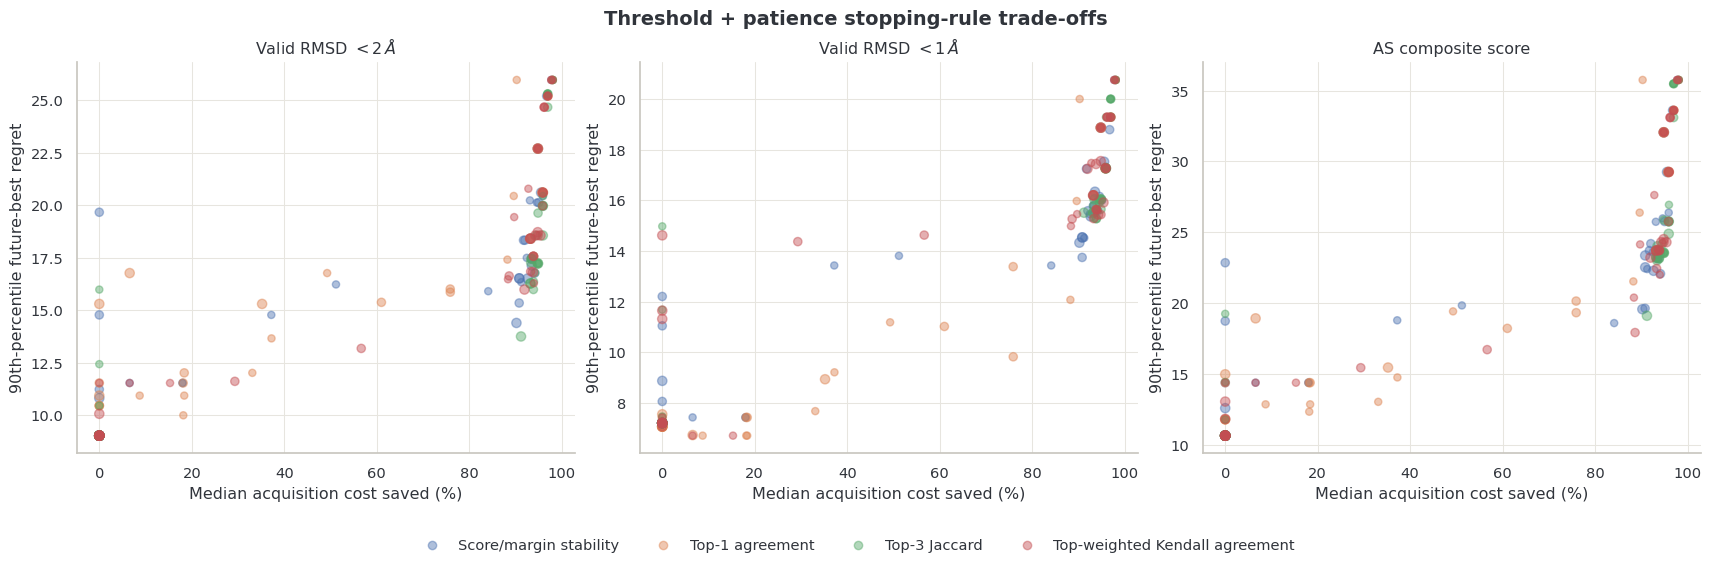

In [129]:
stopping_simulations = simulate_rules(
    stopping_points,
    thresholds=STOPPING_THRESHOLDS,
    patiences=STOPPING_PATIENCES,
)
stopping_rule_summary = summarise_rules(stopping_simulations)
stopping_rule_summary["strict_1pp_10pct_screen"] = (
    stopping_rule_summary["all_trajectories_triggered"]
    & stopping_rule_summary["max_future_best_regret"].le(1.0)
    & stopping_rule_summary["min_method_mean_cost_saved_fraction"].ge(0.10)
)
stopping_rule_summary["lenient_2pp_20pct_screen"] = (
    stopping_rule_summary["all_trajectories_triggered"]
    & stopping_rule_summary["max_future_best_regret"].le(2.0)
    & stopping_rule_summary["min_method_mean_cost_saved_fraction"].ge(0.20)
)

screen_counts = stopping_rule_summary.groupby("downstream_metric")[[
    "strict_1pp_10pct_screen", "lenient_2pp_20pct_screen"
]].sum()
display(Markdown(
    "**Cross-method/fold robustness screens.** These declared 1/2 gap-closure-point and 10/20% cost-saving "
    "screens are sensitivity summaries, not tuned or recommended deployment thresholds."
))
display(screen_counts)

fig, axes = plt.subplots(1, len(DOWNSTREAM_METRICS), figsize=(17, 5), constrained_layout=True)
for ax, metric in zip(axes, DOWNSTREAM_METRICS):
    subset = stopping_rule_summary[stopping_rule_summary["downstream_metric"].eq(metric)]
    for signal, group in subset.groupby("stability_metric"):
        ax.scatter(
            100 * group["median_cost_saved_fraction"], group["p90_future_best_regret"],
            s=18 + 9 * group["patience"], alpha=0.45, label=STABILITY_LABELS[signal],
        )
    ax.set(
        xlabel="Median acquisition cost saved (%)",
        ylabel="90th-percentile future-best regret",
        title=DOWNSTREAM_METRICS[metric][0],
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
fig.suptitle("Threshold + patience stopping-rule trade-offs", fontsize=14, fontweight="semibold")
save_figure(fig, "matrix_stability_stopping_tradeoffs")
plt.show()
plt.close(fig)


In [130]:
stability_tables = {
    "matrix_stability_consecutive": stability_consecutive,
    "matrix_stability_rolling": stability_rolling,
    "matrix_stability_downstream_points": stopping_points,
    "matrix_stability_proxy_by_trajectory": stability_proxy_by_trajectory,
    "matrix_stability_proxy_summary": stability_proxy_summary,
    "matrix_stability_stopping_simulations": stopping_simulations,
    "matrix_stability_stopping_rule_summary": stopping_rule_summary,
}
if SAVE_OUTPUTS:
    for name, table in stability_tables.items():
        table.to_csv(TABLE_DIR / f"{name}.csv", index=False)

display(Markdown(
    "**Interpretation boundary:** this module establishes computable formulations and retrospective diagnostics only. "
    "A stopping rule must be selected and validated on independent, provenance-consistent trajectories before online use."
))
print(f"Exported {len(stability_tables)} matrix-stability tables to {TABLE_DIR}")


**Interpretation boundary:** this module establishes computable formulations and retrospective diagnostics only. A stopping rule must be selected and validated on independent, provenance-consistent trajectories before online use.

Exported 7 matrix-stability tables to /data1/home/jw1017/AS_Dock/results/MolAS/AL_analysis/port_as_primary_reconciled_20260827_v1/tables


## 18. Work A robustness checks: unresolved frontier and progress control

Two checks separate useful convergence evidence from acquisition progress and mechanically fixed cells.

1. **Common-unqueried stability.** For transition $t-1\to t$, cumulative querying means cells unqueried at $t$ were unqueried in both matrices. Stability is recomputed only among those algorithms. Top-1, Kendall, and score/margin statistics require at least two eligible algorithms per row; top-3 Jaccard requires at least four so that the top-three set is not mechanically exhaustive. Metric-specific row and cell support is reported.
2. **Unresolved-frontier stability.** Full-row stability is recomputed only for rows where the winner/runner-up in either matrix includes at least one cell still unqueried at $t$. This retains the observed-versus-predicted competition that drives algorithm selection while excluding already resolved rows.
3. **Progress-controlled association.** Within each method/fold/seed/window/outcome trajectory, Spearman ranks of stability and subsequent change are separately residualised on acquisition progress, then correlated. Query fraction and realised-cost fraction are both reported; because both increase strictly within these trajectories, their Spearman ranks—and therefore their partial-Spearman results—are expected to coincide.

These remain retrospective formulation checks. Support near the end of acquisition can become too small for a frontier statistic even when the complete matrix remains well-defined.

In [131]:
from analyses.port_as_stopping import masked_pair_stability, progress_controlled_associations

WORK_A_CACHE_VERSION = "matrix-stability-work-a-v1"
WORK_A_CACHE_PATH = ANALYSIS_ROOT / "cache/matrix_stability_work_a.pkl"
WORK_A_FRONTIER_DEFINITION = "union-of-pair-top2-intersects-current-unqueried"


def empty_pair_stability():
    return {
        **{signal: np.nan for signal in STABILITY_SIGNALS},
        "score_drift": np.nan,
        "margin_drift": np.nan,
    }


def query_order_matrix(method, fold):
    events = pd.read_csv(
        query_path(method, fold, max(PERCENTAGES)),
        usecols=["query_order", "row_label", "algorithm"],
    )
    events["row_label"] = events["row_label"].astype(str)
    events["algorithm"] = events["algorithm"].map(normalise_algorithm)
    row_position = {row: index for index, row in enumerate(train_ids[fold])}
    algorithm_position = {algorithm: index for index, algorithm in enumerate(ALGORITHMS)}
    order = np.zeros((len(train_ids[fold]), len(ALGORITHMS)), dtype=int)
    order[
        events["row_label"].map(row_position).to_numpy(),
        events["algorithm"].map(algorithm_position).to_numpy(),
    ] = events["query_order"].to_numpy()
    return order


def work_a_trajectory(method_fold):
    method, fold = method_fold
    checkpoints = query_metrics[
        query_metrics["method"].eq(method) & query_metrics["fold"].eq(fold)
    ].set_index("percentage")
    query_order = query_order_matrix(method, fold)
    common_rows, frontier_rows = [], []
    previous = None
    previous_percentage = None
    for percentage in sorted(set(checkpoints.index) & set(PERCENTAGES)):
        matrix, *_ = read_reconstruction(matrix_path(method, fold, percentage), train_ids[fold])
        if matrix is None:
            continue
        current = matrix.to_numpy(float)
        if previous is not None:
            checkpoint = checkpoints.loc[percentage]
            unqueried = query_order > int(checkpoint["query_count"])
            base = {
                "method": method,
                "fold": fold,
                "al_seed": AL_SEED,
                "previous_percentage": previous_percentage,
                "percentage": percentage,
                "query_cost_h": float(checkpoint["query_cost_h"]),
                "query_count": int(checkpoint["query_count"]),
                "query_fraction": float(checkpoint["query_fraction"]),
                "cost_fraction": float(checkpoint["cost_fraction"]),
            }
            common_rows.append({**base, **masked_pair_stability(previous, current, unqueried)})

            previous_top2 = np.argsort(-previous, axis=1, kind="stable")[:, :2]
            current_top2 = np.argsort(-current, axis=1, kind="stable")[:, :2]
            frontier = (
                np.take_along_axis(unqueried, previous_top2, axis=1).any(axis=1)
                | np.take_along_axis(unqueried, current_top2, axis=1).any(axis=1)
            )
            frontier_metrics = (
                pair_stability(previous[frontier], current[frontier])
                if frontier.any() else empty_pair_stability()
            )
            frontier_rows.append({
                **base,
                **frontier_metrics,
                "frontier_rows": int(frontier.sum()),
                "frontier_row_fraction": float(frontier.mean()),
            })
        previous, previous_percentage = current, percentage
    return common_rows, frontier_rows


def attach_endpoint_support(rolling, consecutive, columns):
    keys = ["method", "fold", "al_seed", "percentage"]
    return rolling.merge(
        consecutive[[*keys, *columns]],
        on=keys,
        how="left",
        validate="many_to_one",
    )


work_a_signature = hashlib.sha256(json.dumps({
    "version": WORK_A_CACHE_VERSION,
    "upstream": input_signature("upstream"),
    "module": hashlib.sha256(STABILITY_MODULE_PATH.read_bytes()).hexdigest(),
    "windows": STABILITY_WINDOWS,
    "frontier": WORK_A_FRONTIER_DEFINITION,
}, sort_keys=True).encode()).hexdigest()

work_a_payload = None
if WORK_A_CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    candidate = pd.read_pickle(WORK_A_CACHE_PATH)
    if candidate.get("signature") == work_a_signature:
        work_a_payload = candidate

if work_a_payload is None:
    common_rows, frontier_rows = [], []
    with ThreadPoolExecutor(max_workers=N_JOBS) as executor:
        futures = [
            executor.submit(work_a_trajectory, (method, fold))
            for method in METHODS for fold in FOLDS
        ]
        for future in tqdm(as_completed(futures), total=len(futures), desc="Work A stability"):
            common_part, frontier_part = future.result()
            common_rows.extend(common_part)
            frontier_rows.extend(frontier_part)
    common_unqueried_consecutive = pd.DataFrame(common_rows)
    unresolved_frontier_consecutive = pd.DataFrame(frontier_rows)
    common_unqueried_rolling = attach_endpoint_support(
        rolling_stability(common_unqueried_consecutive, STABILITY_WINDOWS),
        common_unqueried_consecutive,
        [
            "eligible_cells", "eligible_cell_fraction", "eligible_rows_top1",
            "eligible_rows_top3", "eligible_row_fraction_top1",
            "eligible_row_fraction_top3",
        ],
    )
    unresolved_frontier_rolling = attach_endpoint_support(
        rolling_stability(unresolved_frontier_consecutive, STABILITY_WINDOWS),
        unresolved_frontier_consecutive,
        ["frontier_rows", "frontier_row_fraction"],
    )
    work_a_payload = {
        "signature": work_a_signature,
        "common_consecutive": common_unqueried_consecutive,
        "common_rolling": common_unqueried_rolling,
        "frontier_consecutive": unresolved_frontier_consecutive,
        "frontier_rolling": unresolved_frontier_rolling,
    }
    pd.to_pickle(work_a_payload, WORK_A_CACHE_PATH)

common_unqueried_consecutive = work_a_payload["common_consecutive"]
common_unqueried_rolling = work_a_payload["common_rolling"]
unresolved_frontier_consecutive = work_a_payload["frontier_consecutive"]
unresolved_frontier_rolling = work_a_payload["frontier_rolling"]
print(
    f"Computed common-unqueried and unresolved-frontier stability for "
    f"{common_unqueried_consecutive.groupby(['method', 'fold']).ngroups} fold trajectories."
)


Computed common-unqueried and unresolved-frontier stability for 30 fold trajectories.


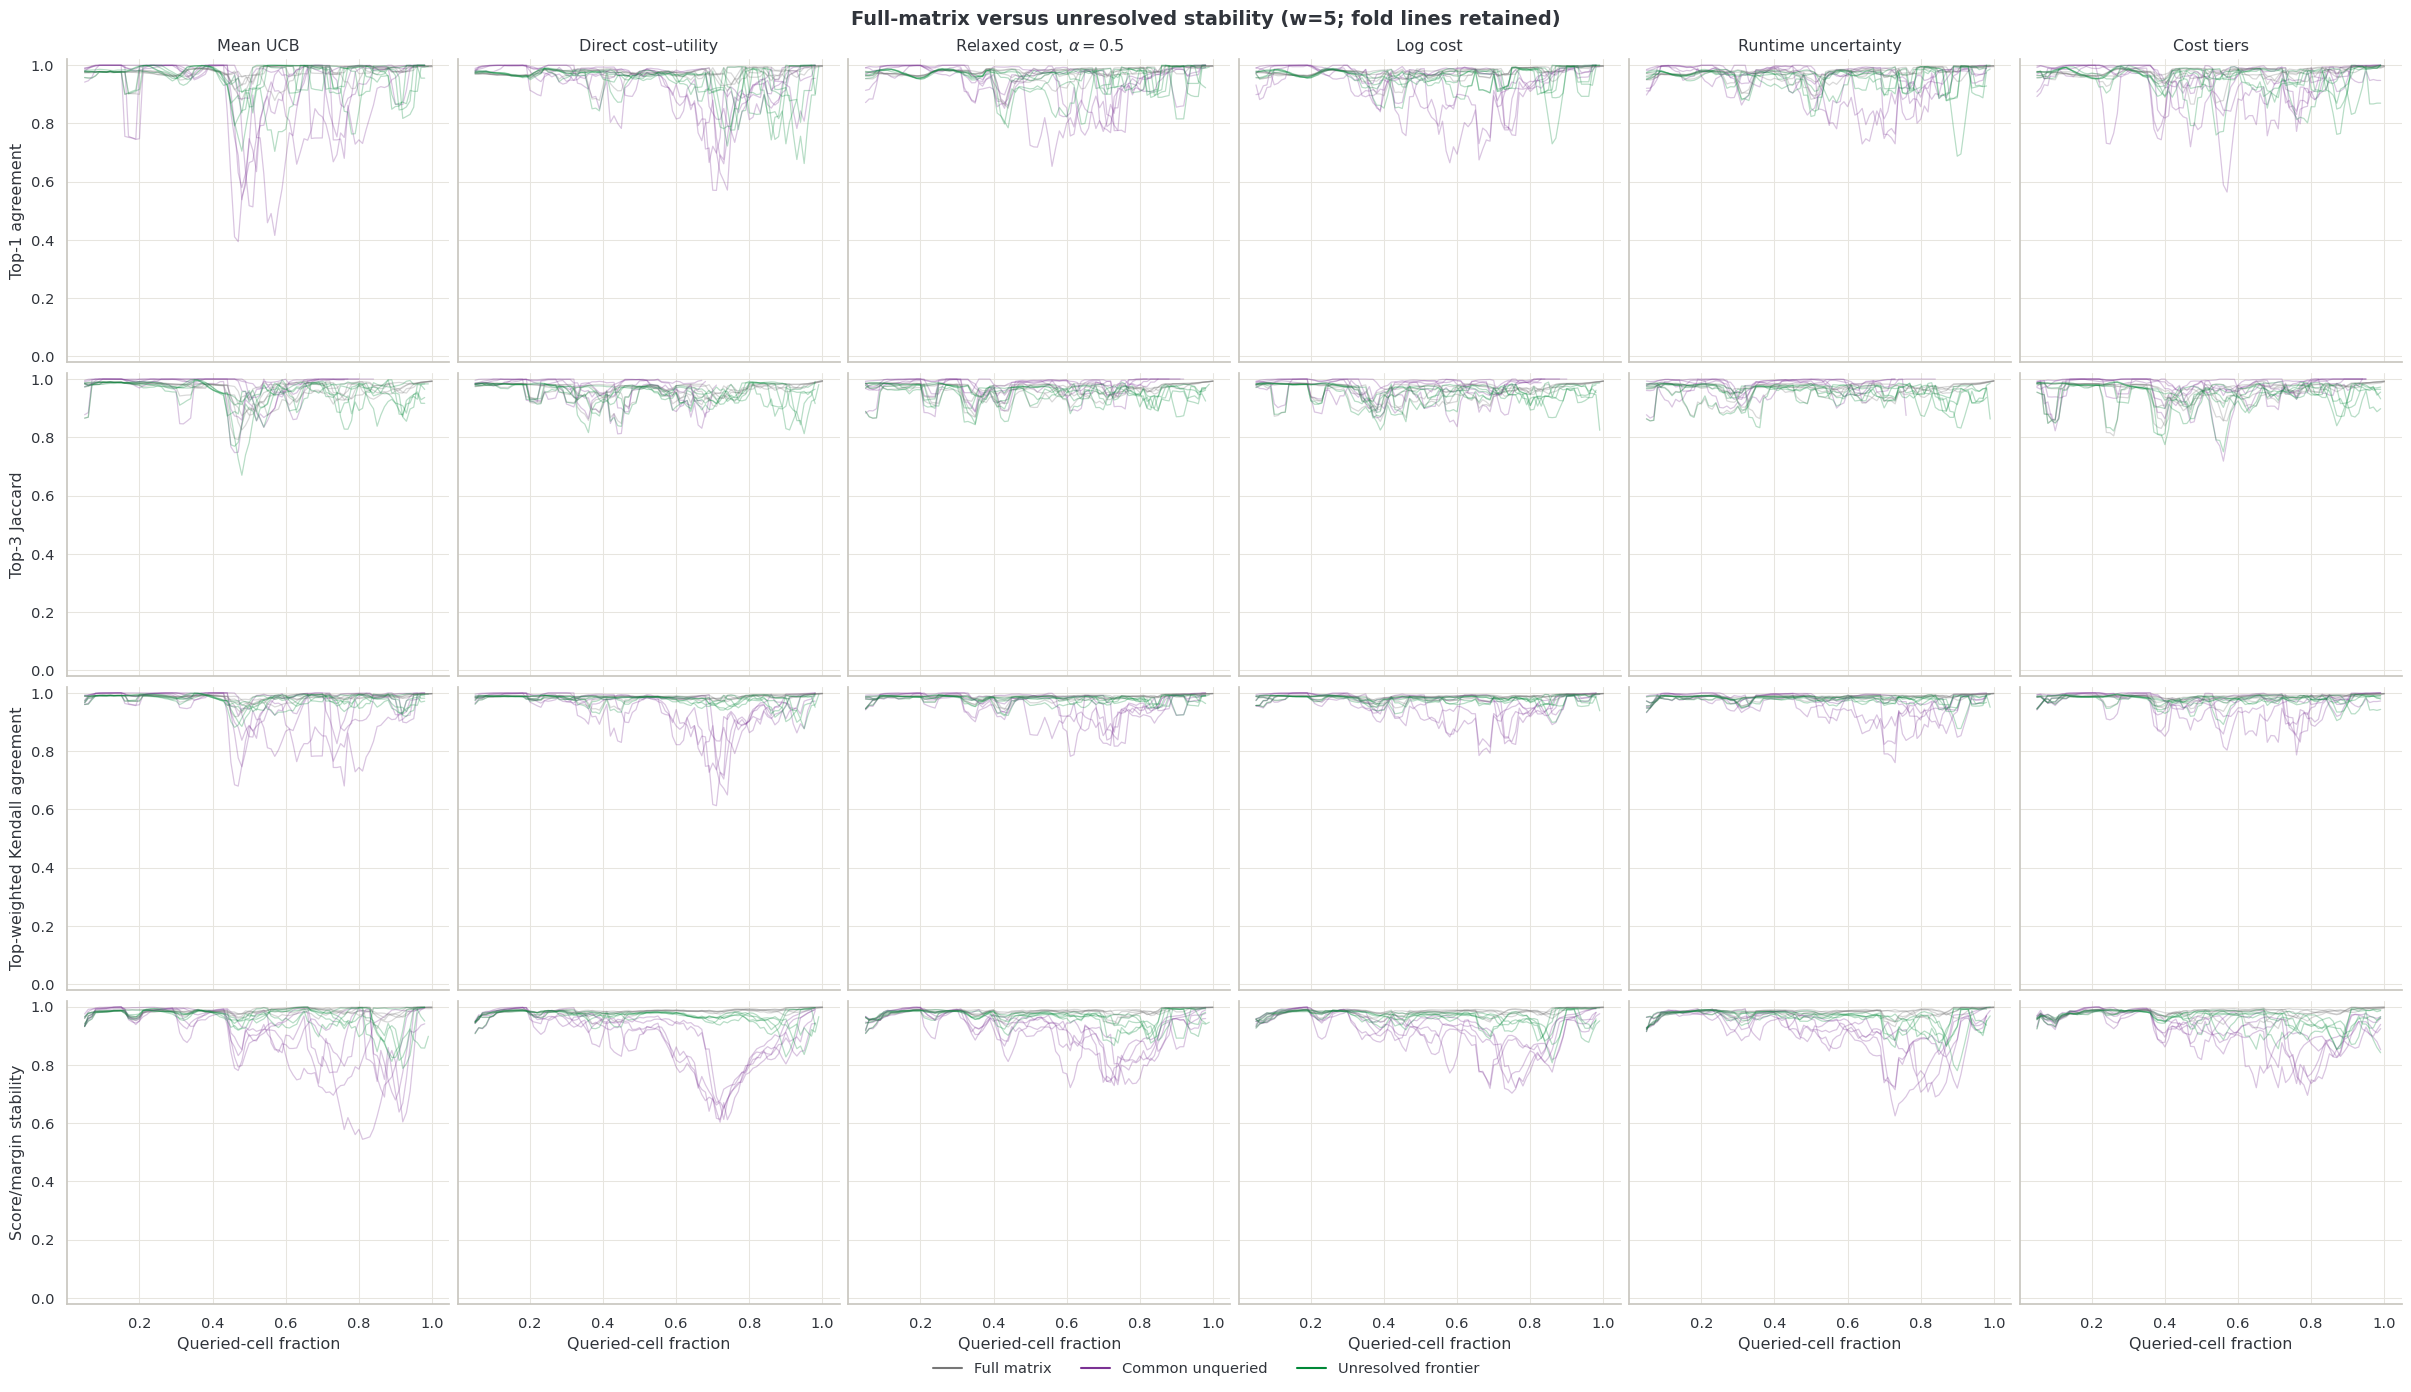

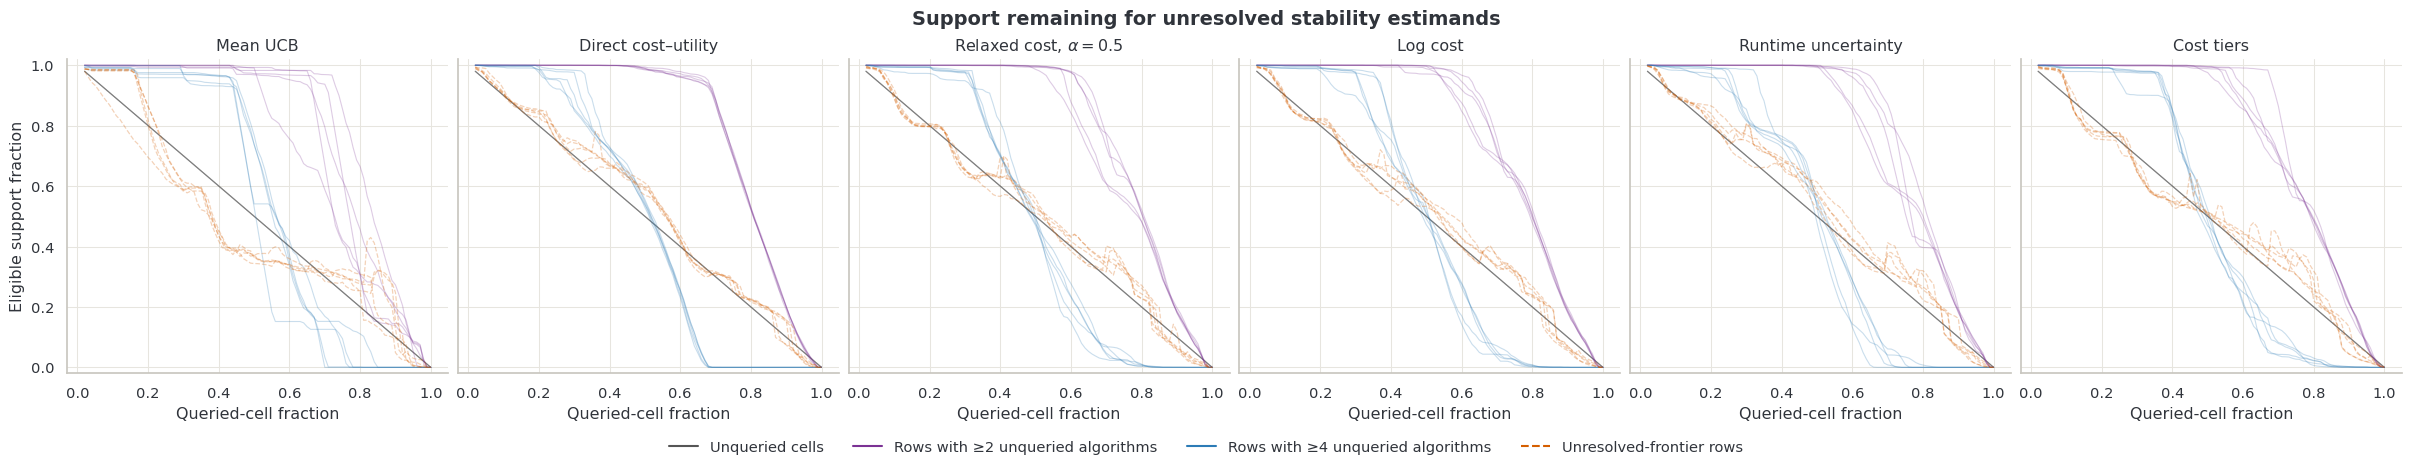

In [132]:
full_scope_rolling = stability_rolling.copy()
if "cost_fraction" not in full_scope_rolling:
    full_scope_rolling = full_scope_rolling.merge(
        query_metrics[["method", "fold", "percentage", "cost_fraction"]],
        on=["method", "fold", "percentage"],
        how="left",
        validate="many_to_one",
    )
scope_stability_rolling = pd.concat([
    full_scope_rolling.assign(stability_scope="full"),
    common_unqueried_rolling.assign(stability_scope="common_unqueried"),
    unresolved_frontier_rolling.assign(stability_scope="unresolved_frontier"),
], ignore_index=True, sort=False)

SCOPE_LABELS = {
    "full": "Full matrix",
    "common_unqueried": "Common unqueried",
    "unresolved_frontier": "Unresolved frontier",
}
SCOPE_COLOURS = {"full": "#777777", "common_unqueried": "#7B3294", "unresolved_frontier": "#008837"}

fig, axes = plt.subplots(
    len(STABILITY_SIGNALS), len(METHODS), figsize=(24, 13.5),
    sharex="col", sharey="row", constrained_layout=True,
)
for row, signal in enumerate(STABILITY_SIGNALS):
    for column, method in enumerate(METHODS):
        ax = axes[row, column]
        subset = scope_stability_rolling[
            scope_stability_rolling["method"].eq(method)
            & scope_stability_rolling["window"].eq(5)
        ]
        for (scope, fold), curve in subset.groupby(["stability_scope", "fold"]):
            ax.plot(
                curve["query_fraction"], curve[signal],
                color=SCOPE_COLOURS[scope], linewidth=0.9, alpha=0.28,
            )
        if row == 0:
            ax.set_title(method_label(method))
        if column == 0:
            ax.set_ylabel(STABILITY_LABELS[signal])
        if row == len(STABILITY_SIGNALS) - 1:
            ax.set_xlabel("Queried-cell fraction")
        ax.set_ylim(-0.02, 1.02)
handles = [plt.Line2D([], [], color=colour, label=SCOPE_LABELS[scope]) for scope, colour in SCOPE_COLOURS.items()]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.025), ncol=3, frameon=False)
fig.suptitle("Full-matrix versus unresolved stability (w=5; fold lines retained)", fontsize=14, fontweight="semibold")
save_figure(fig, "matrix_stability_scope_comparison")
plt.show()
plt.close(fig)

support_styles = {
    "eligible_cell_fraction": ("Unqueried cells", "#555555", "-"),
    "eligible_row_fraction_top1": ("Rows with ≥2 unqueried algorithms", "#7B3294", "-"),
    "eligible_row_fraction_top3": ("Rows with ≥4 unqueried algorithms", "#2C7BB6", "-"),
}
fig, axes = plt.subplots(1, len(METHODS), figsize=(24, 4.2), sharex=True, sharey=True, constrained_layout=True)
for ax, method in zip(axes, METHODS):
    common = common_unqueried_consecutive[common_unqueried_consecutive["method"].eq(method)]
    frontier = unresolved_frontier_consecutive[unresolved_frontier_consecutive["method"].eq(method)]
    for column, (_, colour, style) in support_styles.items():
        for _, curve in common.groupby("fold"):
            ax.plot(
                curve["query_fraction"], curve[column], color=colour,
                linestyle=style, linewidth=0.8, alpha=0.25,
            )
    for _, curve in frontier.groupby("fold"):
        ax.plot(
            curve["query_fraction"], curve["frontier_row_fraction"],
            color="#D55E00", linestyle="--", linewidth=0.9, alpha=0.28,
            label="Unresolved-frontier rows",
        )
    ax.set(title=method_label(method), xlabel="Queried-cell fraction", ylim=(-0.02, 1.02))
axes[0].set_ylabel("Eligible support fraction")
handles = [
    plt.Line2D([], [], color=colour, linestyle=style, label=label)
    for (label, colour, style) in (
        *support_styles.values(),
        ("Unresolved-frontier rows", "#D55E00", "--"),
    )
]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.10), ncol=4, frameon=False)
fig.suptitle("Support remaining for unresolved stability estimands", fontsize=14, fontweight="semibold")
save_figure(fig, "matrix_stability_scope_support")
plt.show()
plt.close(fig)


**Future-best-gain association before and after progress control.** Medians are taken only after computing associations separately for every method/fold/seed/window/outcome trajectory.

,stability_scope,stability_metric,progress_control,n_estimates,median_rho_unadjusted,median_rho_progress_controlled,fraction_negative_controlled
0,common_unqueried,score_margin_stability,cost_fraction,270,0.224,0.038,0.422
1,common_unqueried,score_margin_stability,query_fraction,270,0.224,0.038,0.422
2,common_unqueried,top1_agreement,cost_fraction,270,0.152,-0.025,0.533
3,common_unqueried,top1_agreement,query_fraction,270,0.152,-0.025,0.533
4,common_unqueried,top3_jaccard,cost_fraction,270,-0.099,-0.065,0.563
5,common_unqueried,top3_jaccard,query_fraction,270,-0.099,-0.065,0.563
6,common_unqueried,top_weighted_kendall,cost_fraction,270,0.110,-0.010,0.515
7,common_unqueried,top_weighted_kendall,query_fraction,270,0.110,-0.010,0.515
8,full,score_margin_stability,cost_fraction,270,-0.342,0.016,0.481
9,full,score_margin_stability,query_fraction,270,-0.342,0.016,0.481


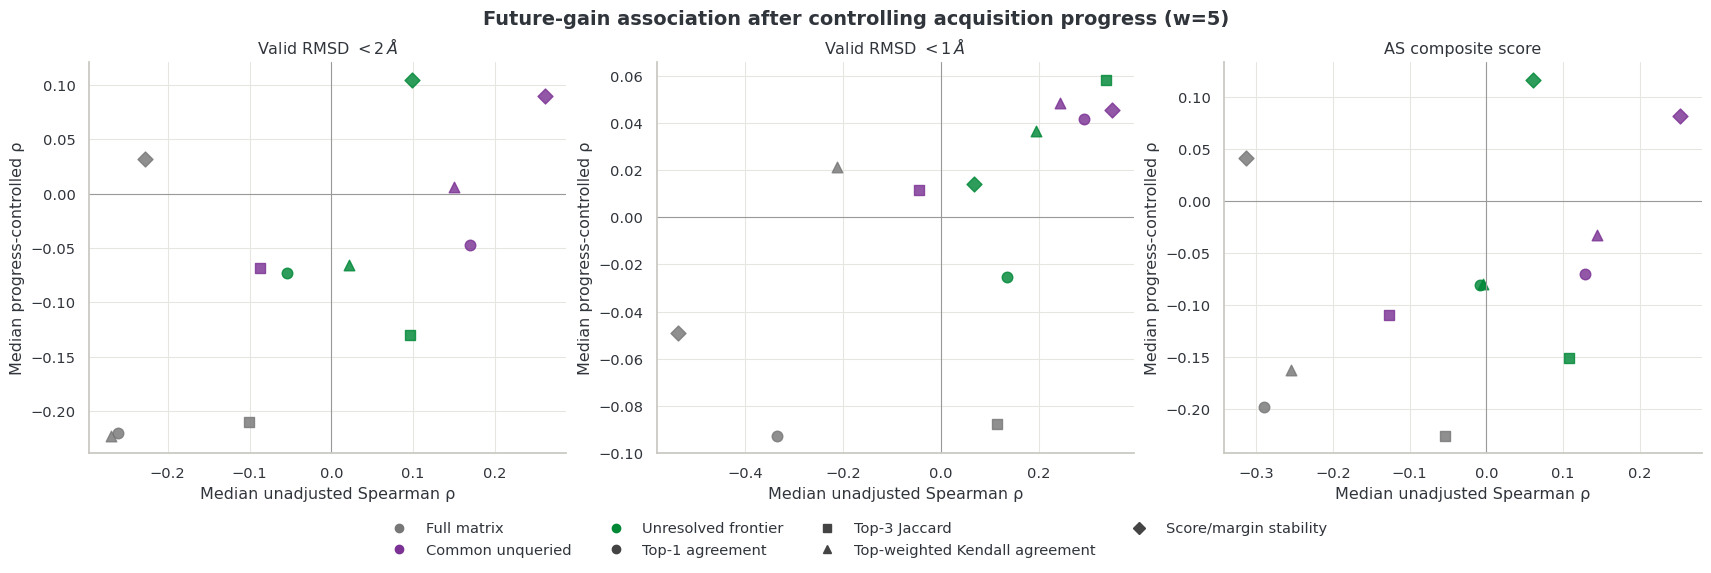

In [133]:
work_a_point_parts = []
for scope, values in scope_stability_rolling.groupby("stability_scope", sort=False):
    part = downstream_gain_table(values, downstream, tuple(DOWNSTREAM_METRICS))
    part["stability_scope"] = scope
    work_a_point_parts.append(part)
work_a_downstream_points = pd.concat(work_a_point_parts, ignore_index=True)

progress_controlled_by_trajectory = progress_controlled_associations(work_a_downstream_points)
progress_controlled_summary = (
    progress_controlled_by_trajectory.groupby([
        "stability_scope", "stability_metric", "window", "downstream_metric",
        "target", "progress_control",
    ], as_index=False)
    .agg(
        n_trajectories=("fold", "size"),
        n_defined=("rho_progress_controlled", "count"),
        median_rho_unadjusted=("rho_unadjusted", "median"),
        median_rho_progress_controlled=("rho_progress_controlled", "median"),
        fraction_negative_controlled=(
            "rho_progress_controlled",
            lambda values: values.dropna().lt(0).mean(),
        ),
    )
)
future_gain_progress_summary = (
    progress_controlled_by_trajectory[
        progress_controlled_by_trajectory["target"].eq("future_best_gain")
    ]
    .groupby(["stability_scope", "stability_metric", "progress_control"], as_index=False)
    .agg(
        n_estimates=("rho_progress_controlled", "count"),
        median_rho_unadjusted=("rho_unadjusted", "median"),
        median_rho_progress_controlled=("rho_progress_controlled", "median"),
        fraction_negative_controlled=(
            "rho_progress_controlled",
            lambda values: values.dropna().lt(0).mean(),
        ),
    )
)
display(Markdown(
    "**Future-best-gain association before and after progress control.** Medians are taken only after "
    "computing associations separately for every method/fold/seed/window/outcome trajectory."
))
display(future_gain_progress_summary.round(3))

plot_data = progress_controlled_summary[
    progress_controlled_summary["target"].eq("future_best_gain")
    & progress_controlled_summary["window"].eq(5)
    & progress_controlled_summary["progress_control"].eq("query_fraction")
]
signal_markers = dict(zip(STABILITY_SIGNALS, ("o", "s", "^", "D")))
fig, axes = plt.subplots(1, len(DOWNSTREAM_METRICS), figsize=(17, 5), constrained_layout=True)
for ax, metric in zip(axes, DOWNSTREAM_METRICS):
    subset = plot_data[plot_data["downstream_metric"].eq(metric)]
    for row in subset.itertuples(index=False):
        ax.scatter(
            row.median_rho_unadjusted,
            row.median_rho_progress_controlled,
            color=SCOPE_COLOURS[row.stability_scope],
            marker=signal_markers[row.stability_metric],
            s=58,
            alpha=0.82,
        )
    ax.axhline(0, color="#999999", linewidth=0.8)
    ax.axvline(0, color="#999999", linewidth=0.8)
    ax.set(
        xlabel="Median unadjusted Spearman ρ",
        ylabel="Median progress-controlled ρ",
        title=DOWNSTREAM_METRICS[metric][0],
    )
scope_handles = [plt.Line2D([], [], marker="o", linestyle="", color=colour, label=SCOPE_LABELS[scope]) for scope, colour in SCOPE_COLOURS.items()]
signal_handles = [plt.Line2D([], [], marker=marker, linestyle="", color="#444444", label=STABILITY_LABELS[signal]) for signal, marker in signal_markers.items()]
fig.legend(handles=[*scope_handles, *signal_handles], loc="lower center", bbox_to_anchor=(0.5, -0.13), ncol=4, frameon=False)
fig.suptitle("Future-gain association after controlling acquisition progress (w=5)", fontsize=14, fontweight="semibold")
save_figure(fig, "matrix_stability_progress_controlled")
plt.show()
plt.close(fig)


In [134]:
work_a_tables = {
    "matrix_stability_common_unqueried_consecutive": common_unqueried_consecutive,
    "matrix_stability_common_unqueried_rolling": common_unqueried_rolling,
    "matrix_stability_unresolved_frontier_consecutive": unresolved_frontier_consecutive,
    "matrix_stability_unresolved_frontier_rolling": unresolved_frontier_rolling,
    "matrix_stability_scope_rolling": scope_stability_rolling,
    "matrix_stability_work_a_downstream_points": work_a_downstream_points,
    "matrix_stability_progress_controlled_by_trajectory": progress_controlled_by_trajectory,
    "matrix_stability_progress_controlled_summary": progress_controlled_summary,
    "matrix_stability_future_gain_progress_summary": future_gain_progress_summary,
}
if SAVE_OUTPUTS:
    for name, table in work_a_tables.items():
        table.to_csv(TABLE_DIR / f"{name}.csv", index=False)

display(Markdown(
    "**Work A boundary:** these checks diagnose mechanical saturation and temporal confounding only. "
    "They do not introduce selector-level stabilisation or tune another stopping rule."
))
print(f"Exported {len(work_a_tables)} Work A robustness tables to {TABLE_DIR}")


**Work A boundary:** these checks diagnose mechanical saturation and temporal confounding only. They do not introduce selector-level stabilisation or tune another stopping rule.

Exported 9 Work A robustness tables to /data1/home/jw1017/AS_Dock/results/MolAS/AL_analysis/port_as_primary_reconciled_20260827_v1/tables
